# Kharcha reader: build, train, test and export the models

One self-contained notebook. **Nothing is imported from `reader_server`**: every piece of the reader is written out in the cells below,
so you can read it, change it and run it. Run top to bottom on the free Colab CPU (about 10 to 15 minutes, mostly OCR).

| Part | What happens |
|---|---|
| 1 | Install docTR, Tesseract (English + Nepali) and the Python packages |
| 2 | **Settings**: the few numbers you may want to change (review threshold, how cautious the category model is) |
| 3 | **Reading rules** (`parse`): turn OCR text lines into merchant, date, total, items; the arithmetic check |
| 4 | **OCR**: docTR, with Tesseract as the rescue path; the "is this even readable?" check |
| 5 | **The two trained models**: the line model (what is each line?) and the category model (what is each item?) |
| 6 | **Training data**: fake receipts plus your 25 real bills, and how to train |
| 7 | **Test 1**: the models on fake receipts they have never seen |
| 8 | **Test 2**: the models on real bills they have never seen (the honest test), then a PASS / FAIL list |
| 9 | **Train the final models**, check the hard bills |
| 10 | **Your own photo**: any image in, full explanation + JSON out |
| 11 | **Export**: a folder with the models and one `kharcha_reader.py` for the backend, tested in a fresh process |

**What changed in this version (the problems found on bills 1, 3 and 21)**
* `HSC:` (the HS-code column of Bhat-Bhateni bills) is no longer read as an item, and an item whose name and numbers the OCR put on two lines is joined back together.
* The **Grand Total** line now wins over a plain "Total" line, and `4802/50` is read as 4802.50. A total that is exactly items + 13% VAT is accepted even when the VAT line itself is unreadable.
* The date is searched in the "Date" lines as well, so a garbled "Bill #" line can no longer hide the real date. If a date was printed but misread (`2082-47-78`) it says so instead of just "not found".
* The category model says **Other** unless it is clearly sure (a 0.39 guess of "Dining" for a chair is now "Other").
* If the line model finds no item at all but a total exists, the plain rules look for a "name  amount" line (this is what rescues a one-line handwritten bill).
* Text that is just noise (handwritten Nepali read as Latin) is reported as **not readable**, with no invented items.

## 1. Install

In [1]:
!apt-get -qq update && apt-get -qq install -y tesseract-ocr tesseract-ocr-eng tesseract-ocr-nep > /dev/null
!pip -q install "python-doctr[torch]" pytesseract opencv-python-headless scikit-learn joblib scipy pillow numpy
!tesseract --list-langs

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
nep
osd


## 2. Settings
Everything you may want to tune is in this one cell. The cells below read these names.
(Cells that start with `# export` are the ones copied into `kharcha_reader.py` in part 11. Do not delete that first line.)

In [2]:
# export order=0 name=settings
# Every number you may want to change is here. The cells below read these names.
import os, re, io, json, math, random, statistics, unicodedata, zipfile, glob, shutil, time
from datetime import date as _date, timedelta

REVIEW_THRESHOLD = 0.7        # confidence at or above this: filed automatically; below: the review screen
CATEGORY_MIN_PROB = 0.45      # an item whose best category is less likely than this becomes "Other" (the user decides)
CATEGORY_MIN_MARGIN = 0.10    # ... or whose best category is not at least this much ahead of the second best
RESCUE = 0.25                 # a "name  amount" line the line model only half believes is an item (p >= this) is kept as one
os.environ.setdefault("OCR_ENGINE", "auto")          # auto = docTR, with Tesseract (English + Nepali) as the rescue path
os.environ.setdefault("KHARCHA_DATE_ORDER", "mdy")   # how to read an ambiguous 05/10/2026: mdy (Nepali POS printers) or dmy
os.environ.setdefault("USE_TORCH", "1")              # Colab also has TensorFlow; make docTR use PyTorch
os.environ.setdefault("USE_TF", "0")
print("settings loaded")

settings loaded


## 3. Reading rules (`parse`)
Plain rules, no model. They pull the numbers out of the lines the trained model picked: the amount at the end of a line, the quantity, the date (including Nepali Bikram Sambat dates, converted to an approximate Gregorian date), and the **arithmetic check**
(do the items plus VAT minus discount add up to the total?). That check is the strongest signal that a read is right, so it drives the confidence.

In [3]:
# export order=1 name=parse
import os
import re
import unicodedata
from datetime import date as _date, timedelta

_DIGITS = str.maketrans("०१२३४५६७८९", "0123456789")
_NUM = r"\d[\d,]*(?:\.\d{1,2})?"
_NUM_AT_END = re.compile(rf"(?<![\w.,/-])({_NUM})\s*(?:/-|-)?\s*$")
_ANY_NUM = re.compile(rf"(?<![\w.,/-])({_NUM})(?![\w/-]*\d)")
_CURRENCY = re.compile(r"(?i)\b(?:rs|npr|inr|usd)\b\.?|रु\.?|₹|\$")

# Lines containing these are never items.
_NOT_ITEM = re.compile(
    r"(?i)sub\s*-?\s*total|\b(?:total|grand|gross|tax(?:able)?|vat|discount|change|cash|tender|paid|balance|amount|"
    r"round(?:ing|ed)?|qr|tip|invoice|date|earned|points?|savings?|qty|cashier|counter)s?\b|\btime\s*:|bill\s*no|\bpan\b|\btel\b|"
    # words that are ALSO part of real item names (phone cover, card holder, table lamp, bike service) only count as labels in label-shaped lines:
    r"\bservice\s*(?:charge|tax|fee)s?\b|\btable\s*(?:no\.?|#|number)?\s*[:.\-]?\s*\d|"
    r"\bphone\s*(?:no\.?|number|#)?\s*[:.\-]?\s*[\d+(]|"
    r"\b(?:credit|debit|visa|master)\s*card\b|^\s*card\s*(?:no\.?|number|payment|pay|\*|x{2,}|[:\-]|\d)|\bvisa\b|"
    r"कुल|जम्मा|उप\s*जम्मा|कर|छुट|फिर्ता|नगद|भ्याट|सेवा|रकम|मिति|बिल\s*नं|प्यान"
)   # whole words only: "Vegetable", "Cashew", "Cardamom" and "Time Pass" are items, "Table 4" and "Cash" are not
_TOTAL_WORDS = re.compile(r"(?i)grand\s*total|net\s*(?:amount|total|payable)|amount\s*(?:due|payable)|total|कुल|जम्मा")
_NOT_TOTAL = re.compile(r"(?i)sub\s*-?\s*total|tax|vat|before|excl|उप\s*जम्मा|कर|भ्याट")
_STRONG_TOTAL = re.compile(r"(?i)grand|net|payable|due|जम्मा")
_NOISE_TOP = re.compile(
    r"(?i)invoice|bill|receipt|tax|vat|pan\b|reg|phone|tel\b|address|date|welcome|thank|www|http|@|"
    r"cash\s*memo|बिल|रसिद|प्यान|मिति|कर"
)
_HSC = re.compile(r"(?i)\bHSC\b\s*:?|\bHS\s*code\b\s*:?")      # the "HS code" column on Bhat-Bhateni style bills
_MONTHS = {m: i + 1 for i, m in enumerate("jan feb mar apr may jun jul aug sep oct nov dec".split())}


def unwrap_json(o):
    """Decode JSON stored inside JSON strings (how the v2 dataset keeps its labels)."""
    import json
    if isinstance(o, str):
        t = o.strip()
        if t[:1] in "{[":
            try:
                return unwrap_json(json.loads(t))
            except Exception:
                return o
        return o
    if isinstance(o, dict):
        return {k: unwrap_json(v) for k, v in o.items()}
    if isinstance(o, list):
        return [unwrap_json(v) for v in o]
    return o


_LOOKALIKE = str.maketrans({"o": "0", "O": "0", "l": "1", "I": "1", "'": "", "\u2019": "", "`": ""})


def normalize(text: str) -> str:
    t = text.translate(_DIGITS)
    t = re.sub(r"(?<![/\-\d])(\d{3,})/(\d{2})\s*$", r"\1.\2", t)               # OCR writes "4802/50" for 4802.50
    t = re.sub(r"(?<=\d)[ \t]*([.,])[ \t]*(?=\d)", r"\1", t)    # OCR often leaves "125 .00" or "120. 00"
    t = re.sub(r"(?<=\d)\.{2,}(?=\d)", ".", t)
    t = re.sub(r"(?<=\d),(\d{2})\s*$", r".\1", t)                  # "309,73" at the end of a line is 309.73 (not a thousands group)
    m = re.search(r"(\S+)\s*$", t)                                # "960.0o" -> "960.00" (look-alike letters in the amount)
    if m and re.search(r"\d", m.group(1)) and re.fullmatch(r"[\dolOI.,'\u2019`]+", m.group(1)):
        t = t[: m.start(1)] + m.group(1).translate(_LOOKALIKE)
    return t


def to_amount(s):
    """'1,234.50' -> 1234.5 (None if it is not a plain amount)."""
    if s is None:
        return None
    s = s.replace(",", "")
    try:
        return float(s)
    except ValueError:
        return None


def _has_letter(s: str) -> bool:
    return any(ch.isalpha() for ch in s)


def _last_amount(line: str):
    line = _CURRENCY.sub(" ", normalize(line)).strip()
    m = _NUM_AT_END.search(line)
    if m:
        return to_amount(m.group(1)), line[: m.start()].strip()
    return None, line


def find_total(lines):
    cands = []
    for i, raw in enumerate(lines):
        line = normalize(raw)
        if _TOTAL_WORDS.search(line) and not _NOT_TOTAL.search(line):
            amt, _ = _last_amount(line)
            if amt is None and i + 1 < len(lines):          # amount sits on the next line
                amt, _ = _last_amount(lines[i + 1])
            if amt is not None and amt > 0:
                cands.append((bool(_STRONG_TOTAL.search(line)), i, amt))
    if cands:
        strong = [c for c in cands if c[0]]
        return (strong or cands)[-1][2]
    return None


def find_date(text: str):
    t = normalize(text)
    m = re.search(r"(\d{4})[-/.](\d{1,2})[-/.](\d{1,2})", t)
    if m:
        y, mo, d = int(m[1]), int(m[2]), int(m[3])
        if 2050 <= y <= 2100:        # Bikram Sambat year: not converted, so no guess
            return None
        return _valid(y, mo, d)
    m = re.search(r"(\d{1,2})[-/.](\d{1,2})[-/.](\d{4})\b", t)
    if m:
        a, b, y = int(m[1]), int(m[2]), int(m[3])
        if y >= 2050:
            return None
        day, mon = (b, a) if b > 12 >= a else (a, b)
        return _valid(y, mon, day)
    m = re.search(r"(\d{1,2})[-/.](\d{1,2})[-/.](\d{2})\b", t)
    if m:
        a, b, y = int(m[1]), int(m[2]), 2000 + int(m[3])
        day, mon = (b, a) if b > 12 >= a else (a, b)
        return _valid(y, mon, day)
    m = re.search(r"(?i)(\d{1,2})[ \-.,]*([a-z]{3})[a-z]*[ \-.,]*(\d{4})", t)
    if m and m[2].lower() in _MONTHS:
        return _valid(int(m[3]), _MONTHS[m[2].lower()], int(m[1]))
    return None


def _valid(y, mo, d):
    try:
        return _date(y, mo, d).isoformat()
    except ValueError:
        return None


# --- Bikram Sambat (Nepali calendar) -------------------------------------------------------------
# Month start dates (Gregorian month, day) for BS months 1..12 (Baisakh..Chaitra). They move by a day or two
# between years, so a converted date is approximate (about +-2 days): good enough to pick the right month.
DATE_ORDER = os.environ.get("KHARCHA_DATE_ORDER", "mdy").lower()      # which way to read an ambiguous 05/10/2026
_BS_STARTS = [(4, 14), (5, 15), (6, 15), (7, 17), (8, 17), (9, 17), (10, 18), (11, 17), (12, 16), (1, 14), (2, 13), (3, 14)]


def bs_to_ad(y, mo, d):
    """Approximate Bikram Sambat -> Gregorian ISO date, or None if it is not a plausible BS date."""
    if not (2070 <= y <= 2100 and 1 <= mo <= 12 and 1 <= d <= 32):
        return None
    gm, gd = _BS_STARTS[mo - 1]
    gy = y - 57 + (1 if mo >= 10 else 0)             # BS year starts mid-April of (y - 57)
    try:
        return (_date(gy, gm, gd) + timedelta(days=d - 1)).isoformat()
    except ValueError:
        return None


def find_date_bs(text: str):
    """A Bikram Sambat date in the text (year 207x-209x, y/m/d or d/m/y), converted to an approximate Gregorian date."""
    t = normalize(text)
    m = re.search(r"\b(20[7-9]\d)[-/.](\d{1,2})[-/.](\d{1,2})\b", t)
    if m:
        return bs_to_ad(int(m[1]), int(m[2]), int(m[3]))
    m = re.search(r"\b(\d{1,2})[-/.](\d{1,2})[-/.](20[7-9]\d)\b", t)
    if m:
        return bs_to_ad(int(m[3]), int(m[2]), int(m[1]))
    return None


def _plausible(d, today):
    return bool(d) and _date(2015, 1, 1) <= _date.fromisoformat(d) <= today + timedelta(days=2)


def resolve_date(text: str, today=None):
    """The receipt's date, or None. A date in the future or before 2015 is an OCR misread ("2036"), so it is dropped
    (the Bikram Sambat date is tried instead, else the user types it)."""
    today = today or _date.today()
    d = _resolve_date_raw(text, today)
    if d and not _plausible(d, today):
        bs = find_date_bs(normalize(text))
        return bs if _plausible(bs, today) else None
    return d


def resolve_date_info(text: str, today=None):
    """(date, approx): approx is True when the date was converted from a Bikram Sambat date (about +-2 days).
    Tries the whole text first, then the lines that say "date", then every line, so a garbled "Bill #" line that holds
    a future date no longer hides the real "Transaction Date" line."""
    today = today or _date.today()

    def one(t):
        d = resolve_date(t, today)
        return d, bool(d) and d == find_date_bs(normalize(t))
    lines = [l for l in text.split("\n") if l.strip()]
    labelled = [l for l in lines if re.search(r"(?i)date|\u092e\u093f\u0924\u093f", l) and not re.search(r"(?i)bill\s*(?:#|no)", l)]
    for t in [text] + labelled + lines:
        d, ap = one(t)
        if d:
            return d, ap
    return None, False


def _resolve_date_raw(text: str, today=None):
    """The receipt's date. Tries the plain Gregorian reading first. When day and month could be swapped
    (05/10/2026), a Bikram Sambat date on the same receipt decides, then 'not in the future', then day-first.
    If only a BS date exists it is converted (approximately)."""
    today = today or _date.today()
    t = normalize(text)
    bs = find_date_bs(t)
    m = re.search(r"(\d{1,2})[-/.](\d{1,2})[-/.](20[0-4]\d)\b", t)
    if m:
        a, b, y = int(m[1]), int(m[2]), int(m[3])
        if a != b and a <= 12 and b <= 12:
            day_first, month_first = _valid(y, b, a), _valid(y, a, b)
            # The Nepali POS printers on the sample bills print MM/DD/YYYY (confirmed by their Bikram Sambat dates),
            # so month-first is the default; KHARCHA_DATE_ORDER=dmy flips it.
            cands = [c for c in ((month_first, day_first) if DATE_ORDER == "mdy" else (day_first, month_first)) if c]
            if len(cands) == 2:
                if bs:
                    ref = _date.fromisoformat(bs)
                    return min(cands, key=lambda c: abs((_date.fromisoformat(c) - ref).days))
                ok = [c for c in cands if _date.fromisoformat(c) <= today]
                if len(ok) == 1:
                    return ok[0]
                return cands[0]
    return find_date(t) or bs


_ADD = re.compile(r"(?i)\bvat\b|\btax\b|service\s*(?:charge|tax)|कर|भ्याट|सेवा")
_SUB = re.compile(r"(?i)discount|\bdisc\b|छुट")
_CASH = re.compile(r"(?i)\bcash\b|tender|paid|received|नगद")
_CHANGE = re.compile(r"(?i)change|refund|return|फिर्ता")


def arithmetic_check(lines, items, total, detail=None):
    """Does the arithmetic of the receipt hold? Returns "items" when item amounts (+ VAT / service charge - discount
    printed on the bill) add up to the total, "paid" when only cash minus change equals the total, else None.
    A wrong or half-read receipt rarely adds up by accident, so this is a better confidence signal than the OCR's own."""
    if not total or total <= 0:
        return None
    tol = max(0.5, 0.0003 * total)          # bills round to the rupee at most; one misread digit must not pass
    adds, subs, cash, change = [0.0], [0.0], [], []
    for raw in lines:
        a = line_amount(raw)
        if a is None or a <= 0:
            continue
        t = normalize(raw)
        if re.search(r"(?i)\b(?:vat|pan)\s*(?:no|number|#)", t) or a > total * 2:       # "VAT No: 606762403" is not a tax amount
            continue
        if _SUB.search(t):
            subs.append(a)
        elif _ADD.search(t):
            adds.append(a)
        elif _CASH.search(t):
            cash.append(a)
        elif _CHANGE.search(t):
            change.append(a)
    base = sum(i["price"] for i in items)
    if detail is not None:
        detail.update(items_sum=round(base, 2), tax_amounts_found=[a for a in adds if a], discount_amounts_found=[a for a in subs if a],
                      cash_found=cash, change_found=change, tolerance=round(tol, 2), printed_total=total)
    if items:
        for v in adds:
            for w in adds:
                for d in subs:
                    if abs(base + v + (w if w != v else 0.0) - d - total) <= tol:
                        if detail is not None:
                            detail.update(matched=f"items {base:.2f} + tax {v + (w if w != v else 0.0):.2f} - discount {d:.2f} = {base + v + (w if w != v else 0.0) - d:.2f} = total")
                        return "items"
    if items:
        tol2 = max(1.0, 0.001 * total)
        for mult, why in ((1.13, "13% VAT"), (1.10 * 1.13, "10% service charge + 13% VAT")):
            if abs(base * mult - total) <= tol2:
                if detail is not None:
                    detail.update(matched=f"items {base:.2f} + {why} (the tax line itself was unreadable, rate inferred) = {base * mult:.2f} = total")
                return "items"
    if any(abs(c - total) <= tol for c in cash) or any(abs(c - h - total) <= tol for c in cash for h in change):
        if detail is not None:
            detail.update(matched="cash paid minus change equals the total (items not confirmed)")
        return "paid"
    return None


def find_merchant(lines):
    for raw in lines[:6]:
        line = re.sub(r"^[\W_]+|[\W_]+$", "", raw.strip())
        if not (3 <= len(line) <= 40) or _NOISE_TOP.search(line):
            continue
        # Devanagari vowel signs are marks (category M), not letters, so count both.
        letters = sum(unicodedata.category(ch)[0] in "LM" for ch in line)
        if letters / len(line) >= 0.6:
            return line
    return None


def parse_item_line(raw, strict=True, serial=False):
    """One OCR line -> {name, qty, price} or None. strict=True also rejects lines that
    look like totals, tax, dates and so on (the rules path); the trained line model
    makes that decision itself, so it calls this with strict=False.
    serial=True: the receipt numbers its lines (1, 2, 3 ...), so a leading number is a serial, not a quantity."""
    line = _HSC.sub(" ", _CURRENCY.sub(" ", normalize(raw))).strip()
    line = re.sub(r"(?<=\s)[=|~:;¢_]+(?=\s|$)", " ", line)         # stray OCR marks between the columns ("1 341.00 = 341.00")
    line = re.sub(r"\s{2,}", " ", line).strip()
    if not line:
        return None
    if strict:
        if _NOT_ITEM.search(line) or re.search(r"\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}", line):
            return None
    price, rest = _last_amount(line)
    if price is None or price <= 0 or price >= 10_000_000 or not _has_letter(rest):
        return None
    qty = 1
    if serial:
        rest = re.sub(r"^\d{1,3}[.)]?\s+(?=\S)", "", rest)
    tail = re.search(rf"(?:^|\s)(\d{{1,3}})\s+({_NUM})\s*$", rest)          # "... 4 400.00" before the amount 1600.00
    if tail and abs(int(tail[1]) * (to_amount(tail[2]) or 0) - price) <= 0.5:
        qty = int(tail[1])
        rest = re.sub(r"^\d{1,3}[.)]?\s+(?=\D)", "", rest[: tail.start()].strip())    # also drop a leading serial number "1 "
        name = re.sub(r"^[\W_]+|[\W_]+$", "", rest).strip()
        if len(name) < 2 or not _has_letter(name):
            return None
        return {"name": name, "qty": max(qty, 1), "price": price}
    m = re.search(r"(?:^|\s)(\d{1,3})\s*[xX×*@]{1,2}\s*\d[\d,]*(?:\.\d{1,2})?", rest)
    if m:
        qty = int(m[1])
        rest = (rest[: m.start()] + " " + rest[m.end():]).strip()
    else:
        m = re.match(r"^(\d{1,3})\s*[xX×*]{1,2}\s+(?=\D)", rest) or (None if serial else re.match(r"^(\d{1,3})\s+(?=\D)", rest))
        if m:
            qty = int(m[1])
            rest = rest[m.end():]
    rest = re.sub(rf"(?:\s+{_NUM})+\s*$", "", rest)          # drop unit prices left of the line total
    name = re.sub(r"^[\W_]+|[\W_]+$", "", rest).strip()
    if len(name) < 2 or not _has_letter(name):
        return None
    return {"name": name, "qty": max(qty, 1), "price": price}


def numbered(lines):
    """True when most of these lines start with 1, 2, 3 ... (a serial-number column, as on Bhat-Bhateni bills)."""
    lead = [int(m[1]) for m in (re.match(r"^\W*(\d{1,3})[.)]?\s+\D", normalize(l)) for l in lines) if m]
    if len(lead) < 3:
        return False
    rising = sum(1 for a, b in zip(lead, lead[1:]) if 0 < b - a <= 5)      # gaps happen when the OCR drops a line
    return rising >= 0.8 * (len(lead) - 1)


def find_items(lines):
    return [i for i in (parse_item_line(l) for l in lines) if i]


def line_amount(raw):
    """The amount at the end of a line, or None."""
    return _last_amount(raw)[0]


_NAMELESS = re.compile(r"^\W*(?:HSC|HS\s*code)\W*:?\s*((?:\d[\d,]*(?:\.\d{1,2})?\s*){1,3})$", re.I)


def join_split_items(lines, joined=None):
    """On some bills the OCR puts an item's numbers (\"HSC: 45.00 45.00\") on one line and its name (\"3 2PM AKABARE\") on the next.
    Put them back together. joined: pass a list to be told which lines were merged."""
    out, i = [], 0
    while i < len(lines):
        m = _NAMELESS.match(normalize(lines[i]))
        if m and i + 1 < len(lines):
            nxt = lines[i + 1]
            if _has_letter(nxt) and line_amount(nxt) is None and not _NOT_ITEM.search(normalize(nxt)):
                out.append(nxt.strip() + " " + m.group(1).strip())
                if joined is not None:
                    joined.append((lines[i], nxt))
                i += 2
                continue
        out.append(lines[i])
        i += 1
    return out


def looks_like_receipt(lines):
    """False when the text is noise (handwriting or a script the OCR cannot read, e.g. Devanagari read as Latin):
    not one total / tax / date / bill word, and fewer than 3 lines that end in an amount."""
    kw = sum(bool(_NOT_ITEM.search(normalize(l)) or re.search(r"(?i)\brs\b|\u0930\u0941|\brate\b", l)) for l in lines)
    prices = sum(line_amount(l) is not None and 0 < line_amount(l) < 1_000_000 and _has_letter(l) for l in lines)      # a 7-digit number is an ID or phone, not a price
    return kw >= 1 or prices >= 3


def parse_receipt(lines, line_model=None, trace=None):
    """lines: text lines, top to bottom.

    With a trained line model (line_model.LineModel) the MODEL decides which line is the
    merchant, an item or the total; the rules above only pull the numbers out of the lines
    it picked. Without one, the rules decide everything (the baseline to beat).
    """
    lines = [l for l in (s.strip() for s in lines) if l]
    joined = []
    lines = join_split_items(lines, joined)
    if trace is not None:
        trace["rejoined_lines"] = joined
    if line_model is None:
        return _parse_rules(lines)
    return _parse_model(lines, line_model, trace)


def _parse_rules(lines):
    items = find_items(lines)
    total = find_total(lines)
    if total is None and items:
        total = round(sum(i["price"] for i in items), 2)
    out = {"total": total, "items": items}
    merchant = find_merchant(lines)
    if merchant:
        out["merchant"] = merchant
    d, approx = resolve_date_info("\n".join(lines))
    if d:
        out["date"] = d
        if approx:
            out["date_approx"] = True
    return out


RESCUE = 0.25


def _parse_model(lines, model, trace=None):
    if not lines:
        return {"total": None, "items": [], "confidence": 0.0}
    probs = model.predict_proba(lines)               # list of {label: p} per line
    labels = [max(p, key=p.get) for p in probs]
    roles = [""] * len(lines)
    items, item_p = [], []
    for k, (line, lab, p) in enumerate(zip(lines, labels, probs)):
        # Rescue: a plain "name  amount" line the model only half-believes is an item (p >= RESCUE) is kept as one,
        # unless it holds a total/tax/cash/date word or the model is fairly sure it is something else.
        noise = bool(_NOT_ITEM.search(normalize(line)))
        rescue = lab == "other" and p["item"] >= RESCUE and p["other"] < 0.6 and not noise
        # A line holding a total / tax / cash / date word is never an item, whatever the model says (whole words only).
        if (lab == "item" and not noise) or rescue:
            it = parse_item_line(line, strict=False)
            if it:
                items.append(it)
                item_p.append(p["item"])
                roles[k] = "ITEM (rescued: model was unsure)" if rescue else "ITEM"
            else:
                roles[k] = "model said item, but no price found at the end of the line"
        elif lab == "item" and noise:
            roles[k] = "model said item, rejected: line has a total/tax/cash/date word"
    used = [k for k, r in enumerate(roles) if r.startswith("ITEM")]
    if numbered([lines[k] for k in used]):          # the bill numbers its lines: a leading number is a serial, not a quantity
        items = [parse_item_line(lines[k], strict=False, serial=True) or it for k, it in zip(used, items)]
    total, total_p, from_line, total_at, total_src = None, 0.0, False, None, "none"
    cands = []
    for i, (line, lab, p) in enumerate(zip(lines, labels, probs)):
        if lab == "total" and not _NOT_TOTAL.search(normalize(line)):        # never a subtotal, tax or "taxable amount" line
            amt = line_amount(line)
            if amt is None and i + 1 < len(lines):
                amt = line_amount(lines[i + 1])
            if amt is not None and amt > 0:
                cands.append((i, amt, p["total"], bool(_STRONG_TOTAL.search(normalize(line)))))
    for i, amt, pt, _ in ([c for c in cands if c[3]] or cands):               # a "Grand Total" / "Net" line beats a plain "Total" line
        if pt >= total_p - 0.15:
            total, total_p, from_line, total_at = amt, max(total_p, pt), True, i
    if total is not None:
        total_src = "the model's total line"
    if total is None:
        total = find_total(lines)                    # the model found no total line: ask the rules
        total_p, from_line = (0.3, True) if total is not None else (0.0, False)
        if total is not None:
            total_src = "rules (the model found no total line)"
    if total is None and items:
        total, total_p = round(sum(i["price"] for i in items), 2), 0.2
        total_src = "estimated: sum of the items (no total line found)"
    if not items and total is not None:     # the model found no item line at all: ask the plain rules (a name and an amount, nothing like a total or date)
        for k, line in enumerate(lines):
            if labels[k] not in ('item', 'other') or roles[k]:
                continue
            it = parse_item_line(line)
            if it and it['price'] <= total and len(re.sub(r'[^A-Za-z\u0900-\u097F]', '', it['name'])) >= 3:
                items.append(it)
                item_p.append(0.3)
                roles[k] = 'ITEM (rules: the model found no item line)'
    out = {"total": total, "items": items}
    top = [(p["merchant"], l) for l, p in zip(lines[:8], probs[:8])]
    merchant_at = None
    if top and max(top)[0] >= 0.4:
        m = re.sub(r"^[\W_]+|[\W_]+$", "", max(top)[1]).strip()
        if m:
            out["merchant"] = m
            merchant_at = top.index(max(top))
    d, approx = resolve_date_info("\n".join(lines))
    if d:
        out["date"] = d
        if approx:
            out["date_approx"] = True
    date_note = None
    if not d:
        m = next((l for l in lines if re.search(r"(?i)date|\u092e\u093f\u0924\u093f", l) and re.search(r"\d{1,4}\s*[-/.]\s*\d{1,2}\s*[-/.]\s*\d{1,4}", normalize(l))), None)
        if m:
            date_note = f"a date was printed ({m.strip()[:50]!r}) but what the OCR read is not a valid date (a misread digit); type it in or use the upload day"
    # Confidence: how sure the model was about the two things the app depends on.
    mean_p = sum(item_p) / len(item_p) if item_p else 0.0
    conf = min(total_p, mean_p)
    check, detail, rule = None, {}, "no total line found, so the model's own sureness is used"
    conf_model = conf
    if from_line:
        # Arithmetic is the stronger signal: if the amounts add up the read is almost surely right; a total that
        # a line was found for but that the items do not explain caps the confidence (review screen).
        check = arithmetic_check(lines, items, total, detail)
        if check == "items":
            conf = max(conf, 0.75 + 0.2 * min(total_p, max(mean_p, 0.0)))
            rule = "items add up to the total: confidence raised to at least 0.75"
        elif check == "paid":
            conf = min(max(conf, 0.6), 0.65)       # the total is corroborated but the items are not: always review
            rule = "only cash minus change matches the total: capped at 0.65 (always review)"
        else:
            conf = min(conf, 0.5)
            rule = "items do not add up to the total: capped at 0.5 (always review)"
    out["confidence"] = round(min(conf, 0.95), 3)
    out["needs_review"] = out["confidence"] < REVIEW_THRESHOLD or total is None
    out["reconciliation"] = (
        "No total found" if total is None else
        "Items add up to the total (VAT and discount included)" if check == "items" else
        "Total matches cash minus change; some items may be missed" if check == "paid" else
        "Items do not add up to the total" if from_line else
        "No total line found; total estimated from items")
    if trace is not None:
        date_at = next((i for i, l in enumerate(lines) if resolve_date_info(l)[0]), None)
        trace.update(
            lines=[{"index": i, "text": l, "model_label": lab, "model_sureness": round(p[lab], 2),
                    "top3": {k: round(v, 2) for k, v in sorted(p.items(), key=lambda kv: -kv[1])[:3]},
                    "role": roles[i] or ("TOTAL LINE" if i == total_at else "MERCHANT" if i == merchant_at else
                                         "DATE LINE" if i == date_at else "ignored")}
                   for i, (l, lab, p) in enumerate(zip(lines, labels, probs))],
            total={"value": total, "source": total_src, "line_index": total_at, "model_sureness": round(total_p, 2)},
            merchant={"value": out.get("merchant"), "line_index": merchant_at},
            date={"value": out.get("date"), "from_line": date_at, "note": date_note, "approx_from_bikram_sambat": bool(out.get("date_approx"))},
            arithmetic={"result": check, **detail},
            confidence={"model_total_sureness": round(total_p, 2), "model_mean_item_sureness": round(mean_p, 2),
                        "model_only": round(conf_model, 3), "rule_applied": rule, "final": out["confidence"],
                        "review_threshold": REVIEW_THRESHOLD})
    return out

## 4. OCR
docTR reads the photo. If the text it returns is too thin or looks like noise, Tesseract (English + Nepali) reads it too and the better reading wins.
Both give words with positions; `_rows` groups them into lines, top to bottom.

In [4]:
# export order=2 name=ocr

# Colab ships TensorFlow too; make docTR use PyTorch (what we install) instead of guessing.

from PIL import Image, ImageOps

LANGS = os.environ.get("OCR_LANGS", "eng+nep")
PSM = os.environ.get("OCR_PSM", "6")      # 6 = one block of text; measured better than 4 on real phone photos
_cmd = os.environ.get("TESSERACT_CMD")     # Windows: C:\Program Files\Tesseract-OCR\tesseract.exe


def _tess():
    import pytesseract

    if _cmd:
        pytesseract.pytesseract.tesseract_cmd = _cmd
    return pytesseract


def available_langs() -> str:
    """The requested languages that are actually installed (so a missing Nepali pack is not fatal)."""
    have = set(_tess().get_languages(config=""))
    use = [l for l in LANGS.split("+") if l in have]
    return "+".join(use) or "eng"


def _flatten_background(img: Image.Image) -> Image.Image:
    """Divide by a blurred copy of the page: removes shadows and creases from phone photos.
    Needs OpenCV; without it the image is returned unchanged (OCR still works, a bit worse)."""
    try:
        import cv2
        import numpy as np
    except ImportError:
        return img
    a = np.array(img)
    bg = cv2.medianBlur(cv2.dilate(a, np.ones((15, 15), np.uint8)), 31)
    n = cv2.divide(a, bg, scale=255)
    return Image.fromarray(cv2.normalize(n, None, 0, 255, cv2.NORM_MINMAX))


def prepare(image: Image.Image) -> Image.Image:
    img = ImageOps.exif_transpose(image).convert("L")
    img = _flatten_background(img) if os.environ.get("OCR_FLATTEN", "1") == "1" else ImageOps.autocontrast(img, cutoff=1)
    w = img.width
    if w < 1200:
        img = img.resize((1200, round(img.height * 1200 / w)), Image.LANCZOS)
    elif w > 2400:
        img = img.resize((2400, round(img.height * 2400 / w)), Image.LANCZOS)
    return img


def _tesseract_lines(image: Image.Image, min_conf: int = 30):
    """Tesseract: photo in, list of text lines (top to bottom) out."""
    t = _tess()
    data = t.image_to_data(prepare(image), lang=available_langs(), config=f"--oem 1 --psm {PSM}",
                           output_type=t.Output.DICT)
    words = []
    for i, text in enumerate(data["text"]):
        text = text.strip()
        try:
            conf = float(data["conf"][i])
        except ValueError:
            conf = -1
        if text and conf >= min_conf:
            words.append((data["top"][i] + data["height"][i] / 2, data["left"][i], data["height"][i], text))
    if not words:
        return []
    return _rows(words)


def _rows(words):
    """words: (y_centre, x_left, height, text) -> text lines, top to bottom, words left to right."""
    words = sorted(words)
    tol = 0.6 * statistics.median(w[2] for w in words)
    rows, cur = [], [words[0]]
    for w in words[1:]:
        if abs(w[0] - statistics.mean(x[0] for x in cur)) <= tol:
            cur.append(w)
        else:
            rows.append(cur)
            cur = [w]
    rows.append(cur)
    return [" ".join(x[3] for x in sorted(r, key=lambda x: x[1])) for r in rows]


# --- docTR (open-source, self-hosted: db_resnet50 text detector + crnn_vgg16_bn recogniser) -------------
ENGINE = os.environ.get("OCR_ENGINE", "auto")      # auto = docTR if installed (plus Tesseract rescue), "doctr", "tesseract"
_doctr_model = None
last_engine = None          # which engine produced the lines of the last ocr_lines call


def doctr_available() -> bool:
    try:
        import doctr  # noqa: F401
        return True
    except ImportError:
        return False


def _doctr():
    global _doctr_model
    if _doctr_model is None:
        from doctr.models import ocr_predictor
        _doctr_model = ocr_predictor(det_arch="db_resnet50", reco_arch="crnn_vgg16_bn", pretrained=True)
    return _doctr_model


def _doctr_lines(image: Image.Image, max_side: int = 2200, min_conf: float = 0.2):
    import numpy as np
    img = ImageOps.exif_transpose(image).convert("RGB")
    s = max_side / max(img.size)
    if s < 1:
        img = img.resize((round(img.width * s), round(img.height * s)), Image.LANCZOS)
    page = _doctr()([np.array(img)]).pages[0]
    H, W = img.height, img.width
    words = []
    for block in page.blocks:
        for line in block.lines:
            for w in line.words:
                (x0, y0), (x1, y1) = w.geometry
                if w.value.strip() and w.confidence >= min_conf:
                    words.append(((y0 + y1) / 2 * H, x0 * W, max((y1 - y0) * H, 1.0), w.value.strip()))
    return _rows(words) if words else []


def _price_lines(lines) -> int:
    return sum(line_amount(l) is not None and any(c.isalpha() for c in l) for l in lines)


def ocr_lines(image: Image.Image, min_conf: int = 30):
    """Photo in, list of text lines (top to bottom) out. THIS IS THE OCR AI STEP (docTR, with Tesseract as the
    Nepali / rescue path): `ocr_lines` in this file.
    auto: docTR reads the photo; if it finds almost no "name  amount" lines (handwriting, mostly Devanagari bills)
    Tesseract eng+nep reads it too and the reading with more such lines wins."""
    global last_engine
    if ENGINE == "tesseract" or (ENGINE == "auto" and not doctr_available()):
        last_engine = "Tesseract"
        return _tesseract_lines(image, min_conf)
    try:
        lines = _doctr_lines(image)
    except Exception as e:
        if ENGINE == "doctr":
            raise
        print(f"[ocr] docTR failed ({type(e).__name__}: {str(e)[:120]}); using Tesseract instead")   # a broken docTR must not take the reader down
        last_engine = f"Tesseract (docTR failed: {type(e).__name__})"
        return _tesseract_lines(image, min_conf)
    last_engine = "docTR"
    if ENGINE == "auto" and (_price_lines(lines) < 3 or not looks_like_receipt(lines)):
        try:
            alt = _tesseract_lines(image, min_conf)
            better = (looks_like_receipt(alt) and not looks_like_receipt(lines)) or _price_lines(alt) > _price_lines(lines)
            if better:
                last_engine = "Tesseract (rescue: docTR text was too thin or looked like noise)"
                return alt
        except Exception:
            pass
    return lines

## 5. The two trained models
* **Line model**: for every OCR line, how likely it is the merchant, the date, an item, a subtotal, tax, the total or something else. Character n-grams plus a few layout numbers into a logistic regression.
* **Category model**: item name to one of eight categories. Character n-grams, so a badly spelled name still lands near the right category. If it is not clearly sure it answers **Other** (settings: `CATEGORY_MIN_PROB`, `CATEGORY_MIN_MARGIN`).

Both are tiny (about 1 MB) and train in seconds on a CPU.

In [5]:
# export order=3 name=models
import joblib
import numpy as np
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression



_DEV = str.maketrans("०१२३४५६७८९", "0123456789")
_AMOUNT_END = re.compile(r"\d[\d,]*(?:\.\d{1,2})?\s*(?:/-|-)?\s*$")
_DATE = re.compile(r"\d{1,4}\s*[-/.]\s*\d{1,2}\s*[-/.]\s*\d{1,4}|\d{1,2}\s*[a-z]{3}[a-z]*\s*,?\s*\d{4}", re.I)
_CURRENCY = re.compile(r"(?i)\b(?:rs|npr)\b\.?|रु\.?")


def shape(text: str) -> str:
    """Lower-case, every run of digits becomes one '0', so '1,118.70' and '45.00' look alike."""
    t = text.translate(_DEV).lower()
    return re.sub(r"\d+", "0", t)


def numeric_features(lines):
    """One row per line: position in the receipt and what the line is made of."""
    n = len(lines)
    rows = []
    for i, raw in enumerate(lines):
        t = raw.translate(_DEV)
        L = max(len(t), 1)
        digits = sum(c.isdigit() for c in t)
        letters = sum(unicodedata.category(c)[0] in "LM" for c in t)
        upper = sum(c.isupper() for c in t)
        rows.append([
            1.0 if _AMOUNT_END.search(t) else 0.0,
            i / max(n - 1, 1),                       # 0 at the top, 1 at the bottom
            min(i, 8) / 8,                           # lines from the top / bottom, capped, so short and long receipts agree
            min(n - 1 - i, 8) / 8,
            digits / L,
            letters / L,
            min(L, 60) / 60,
            upper / max(letters, 1),
            min(len(re.findall(r"\d[\d,.]*", t)), 6) / 6,
            1.0 if _DATE.search(t) else 0.0,
            1.0 if _CURRENCY.search(t) else 0.0,
            1.0 if _NOT_ITEM.search(t) else 0.0,     # contains a total / tax / cash / date word (the same list the rules use)
        ])
    return np.array(rows, dtype=float)



LABELS = ["merchant", "date", "item", "subtotal", "tax", "total", "other"]


class LineModel:
    def __init__(self):
        self.chars = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True, max_features=40000)
        self.words = TfidfVectorizer(analyzer="word", token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        self.clf = LogisticRegression(C=8.0, max_iter=3000, class_weight="balanced")

    def _x(self, lines, fit=False):
        shaped = [shape(l) for l in lines]
        f = (self.chars.fit_transform if fit else self.chars.transform)
        g = (self.words.fit_transform if fit else self.words.transform)
        return hstack([f(shaped), g(shaped), csr_matrix(numeric_features(lines))], format="csr")

    def fit(self, receipts):
        """receipts: list of [(line_text, label), ...], one list per receipt, top to bottom."""
        lines, y = [], []
        # numeric features depend on position inside the receipt, so build them per receipt
        feats = []
        for r in receipts:
            texts = [t for t, _ in r]
            feats.append(numeric_features(texts))
            lines += texts
            y += [lab for _, lab in r]
        shaped = [shape(l) for l in lines]
        X = hstack([self.chars.fit_transform(shaped), self.words.fit_transform(shaped), csr_matrix(np.vstack(feats))], format="csr")
        self.clf.fit(X, y)
        return self

    def predict_proba(self, lines):
        P = self.clf.predict_proba(self._x(lines))
        classes = list(self.clf.classes_)
        return [{lab: float(P[i, classes.index(lab)]) if lab in classes else 0.0 for lab in LABELS} for i in range(len(lines))]

    def predict(self, lines):
        return [max(p, key=p.get) for p in self.predict_proba(lines)]

    def save(self, path):
        joblib.dump(self, path, compress=3)

    @staticmethod
    def load(path):
        return joblib.load(path)



CATEGORIES = ["Groceries", "Dining", "Transport", "Shopping", "Health", "Bills", "Entertainment", "Other"]


class CategoryModel:
    def __init__(self):
        self.chars = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True)
        self.words = TfidfVectorizer(analyzer="word", token_pattern=r"\S+", sublinear_tf=True)
        self.clf = LogisticRegression(C=15.0, max_iter=3000, class_weight="balanced")

    def _x(self, names, fit=False):
        t = [shape(n) for n in names]
        if fit:
            return hstack([self.chars.fit_transform(t), self.words.fit_transform(t)], format="csr")
        return hstack([self.chars.transform(t), self.words.transform(t)], format="csr")

    def fit(self, rows):
        """rows: [(item_name, category), ...]"""
        self.clf.fit(self._x([n for n, _ in rows], fit=True), [c for _, c in rows])
        return self

    def predict(self, names):
        """-> [(category, probability)]. When the model is not clearly sure (best probability under CATEGORY_MIN_PROB, or
        less than CATEGORY_MIN_MARGIN ahead of the runner-up) the item is "Other": a wrong confident label is worse than a
        blank one the user fills in."""
        if not names:
            return []
        P = self.clf.predict_proba(self._x(names))
        out = []
        for row in P:
            order = row.argsort()[::-1]
            k, k2 = int(order[0]), int(order[1]) if len(order) > 1 else None
            cat, p = str(self.clf.classes_[k]), float(row[k])
            p2 = float(row[k2]) if k2 is not None else 0.0
            unsure = p < CATEGORY_MIN_PROB or (p - p2) < CATEGORY_MIN_MARGIN
            out.append(("Other" if unsure else cat, p))
        return out

    def predict_top(self, names, k=3):
        """-> per name, the k most likely [(category, probability)], for explaining a result."""
        if not names:
            return []
        P = self.clf.predict_proba(self._x(names))
        return [[(str(self.clf.classes_[j]), round(float(row[j]), 2)) for j in row.argsort()[::-1][:k]] for row in P]

    def save(self, path):
        joblib.dump(self, path, compress=3)

    @staticmethod
    def load(path):
        return joblib.load(path)

### The photo-to-receipt function
`read_photo` is the whole product in one call: OCR, then line model, then category model. `KharchaReader` is the small wrapper the backend will use.

In [6]:
# export order=4 name=pipeline
from PIL import Image


class ModelsMissing(RuntimeError):
    """The trained models are not there. The reader refuses to run without them (the "delete the AI" proof)."""


class Models:
    def __init__(self, line, category):
        self.line = line
        self.category = category

    def save(self, folder):
        os.makedirs(folder, exist_ok=True)
        self.line.save(os.path.join(folder, "line_model.joblib"))
        self.category.save(os.path.join(folder, "category_model.joblib"))


def load_models(folder):
    """Both trained models from a folder, or None if the files are missing or were saved by another scikit-learn version."""
    lp, cp = os.path.join(folder, "line_model.joblib"), os.path.join(folder, "category_model.joblib")
    if not (os.path.exists(lp) and os.path.exists(cp)):
        return None
    try:
        m = Models(LineModel.load(lp), CategoryModel.load(cp))
        m.line.predict_proba(["Total 100.00"])        # use each once now: a model from another scikit-learn version
        m.category.predict(["rice"])                  # loads fine and then fails on its first real use
        return m
    except Exception as e:
        print(f"Could not use the trained models in {folder} ({type(e).__name__}: {e}). Train them again.")
        return None


def read_lines(lines, models, trace=None):
    """OCR lines -> receipt dict. models=None runs the plain rules only. trace: pass a dict to get the full reasoning back."""
    lines = [l.strip() for l in lines if l and l.strip()]
    if not looks_like_receipt(lines):
        if trace is not None:
            trace.update(unreadable=True, lines=[{"index": i, "text": l, "model_label": "-", "model_sureness": 0.0, "top3": {}, "role": "ignored"}
                                                 for i, l in enumerate(lines)], total={}, merchant={}, date={}, arithmetic={}, categories=[],
                         confidence={"final": 0.0, "review_threshold": REVIEW_THRESHOLD, "rule_applied": "text is noise, nothing was trusted"})
        return {"total": None, "items": [], "confidence": 0.0, "needs_review": True, "readable": False,
                "reconciliation": "The photo could not be read: the text looks like noise (handwriting, or a script the OCR cannot read). Enter it by hand."}
    out = parse_receipt(lines, models.line if models else None, trace)
    if models and out["items"]:
        names = [i["name"] for i in out["items"]]
        for item, (cat, _) in zip(out["items"], models.category.predict(names)):
            item["category"] = cat
        if trace is not None:
            trace["categories"] = [{"item": n, "top3": dict(t)} for n, t in zip(names, models.category.predict_top(names))]
    return out


def read_photo(image, models, trace=None):
    """Photo (PIL image or file path) -> {merchant, date, total, items[{name, qty, price, category}], confidence, needs_review}.
    The whole product in one call: OCR, then the trained line model, then the category model.
    models=None runs the rules-only baseline; a Models object is the normal case."""
    if isinstance(image, (str, os.PathLike)):
        image = Image.open(image)
    lines = ocr_lines(image)
    if trace is not None:
        trace["ocr_engine"] = last_engine
        trace["ocr_lines"] = lines
    return read_lines(lines, models, trace)


class KharchaReader:
    """What the backend uses:  reader = KharchaReader("folder with the two .joblib files");  reader.read("photo.jpg")"""

    def __init__(self, folder="."):
        self.models = load_models(folder)
        if self.models is None:
            raise ModelsMissing(f"No usable trained models in {folder!r}.")

    def read(self, image, trace=None):
        return read_photo(image, self.models, trace)

## 6. Training data and how to train
**Fake receipts** (`make_dataset`): receipts generated with known answers, English and Nepali, with OCR-style typos. Good for a first model, but easier than real life.
**Your real bills**: the 25 photos in `Bills.zip`, read by the OCR and labelled automatically from the answer key (`bills_gold.json`, read by eye from the photos, so it can contain mistakes).

In [7]:
import re
try:
    _NOT_ITEM                      # inside the notebook this already exists (the patched one from the parse cell)
except NameError:                  # standalone: the same pattern, copied
    _NOT_ITEM = re.compile('(?i)sub\\s*-?\\s*total|\\b(?:total|grand|gross|tax(?:able)?|vat|service|discount|change|cash|tender|paid|balance|amount|round(?:ing|ed)?|card|visa|qr|tip|invoice|table|date|earned|points?|savings?|qty|cashier|counter)s?\\b|\\btime\\s*:|bill\\s*no|\\bpan\\b|\\bphone\\b|\\btel\\b|कुल|जम्मा|उप\\s*जम्मा|कर|छुट|फिर्ता|नगद|भ्याट|सेवा|रकम|मिति|बिल\\s*नं|प्यान|phone\\s*p(?:e|ay)\\b|e-?sewa|khalti|fone\\s*pay|fonepay|ime\\s*pay|connect\\s*ips|prabhu\\s*pay|cell\\s*pay|namaste\\s*pay|nepal\\s*pay|\\bg\\s*pay\\b|google\\s*pay|paytm|\\bupi\\b|amazon\\s*pay|apple\\s*pay|samsung\\s*pay|paypal|mobile\\s*banking|net\\s*banking|internet\\s*banking|bank\\s*transfer|e-?wallet|digital\\s*wallet|\\bdebit\\b|master\\s*card|unionpay|\\bcod\\b|cash\\s*on\\s*delivery|delivery\\s*(?:charge|fee)|pack(?:ing|aging)\\s*(?:charge|fee)|\\btxn\\b|transaction|approval\\s*code|\\brrn\\b|\\butr\\b|\\bauth\\b|\\bref(?:erence)?\\s*(?:no|id|#)|terminal|\\bkot\\b|\\btoken\\b|\\bpax\\b|\\bscan\\b|फोन\\s*पे|फोनपे|इ-?सेवा|ईसेवा|खल्ती|क्यू\\s*आर|भुक्तानी|कार्ड|वालेट|उधारो|लेनदेन')

# The original notebook's starter vocabulary, kept as-is (it wins when a name is also generated under another category).
SEED_NAMES = {'Groceries': ['basmati rice 5kg',
               'rice 25kg',
               'chamal',
               'चामल',
               'jeera masino rice',
               'lentils 2kg',
               'dal',
               'दाल',
               'masoor dal',
               'cooking oil 5l',
               'mustard oil',
               'tel',
               'तेल',
               'sunflower oil',
               'toned milk 1l',
               'milk packet',
               'dudh',
               'दूध',
               'eggs tray',
               'egg 12 pcs',
               'anda',
               'अण्डा',
               'vegetables',
               'tarkari',
               'तरकारी',
               'potato 2kg',
               'onion 1kg',
               'tomato',
               'garlic ginger',
               'fruits',
               'apple 1kg',
               'banana dozen',
               'orange',
               'falful',
               'फलफूल',
               'atta 10kg',
               'आटा',
               'maida flour',
               'sugar 2kg',
               'chini',
               'चिनी',
               'salt packet',
               'nun',
               'नुन',
               'tea 500g',
               'tea leaves',
               'butter 500g',
               'ghee 1l',
               'ghiu',
               'घिउ',
               'dairy',
               'curd 1kg',
               'dahi',
               'दही',
               'paneer',
               'bread loaf',
               'brown bread',
               'pau roti',
               'noodles pack',
               'wai wai',
               'वाइवाइ',
               'biscuits',
               'snacks',
               'chips',
               'chicken 1kg',
               'mutton 1kg',
               'masu',
               'मासु',
               'fish',
               'spices masala',
               'turmeric powder',
               'chana',
               'rajma beans',
               'peanuts',
               'dry fruits',
               'honey',
               'jam',
               'pickle achar',
               'अचार'],
 'Dining': ['momo',
            'mo:mo',
            'मोमो',
            'chicken momo',
            'buff momo',
            'veg momo',
            'jhol momo',
            'thali set',
            'थाली',
            'dal bhat set',
            'khana set',
            'खाना',
            'nasi goreng',
            'nasi campur',
            'mie goreng',
            'burger',
            'cheese burger',
            'pizza',
            'margherita pizza',
            'pasta',
            'chowmein',
            'चाउमिन',
            'chow mein',
            'fried rice',
            'chilli chicken',
            'sekuwa',
            'सेकुवा',
            'choila',
            'chatamari',
            'चटामरी',
            'sizzler',
            'steak',
            'wagyu ribeye',
            'sandwich',
            'club sandwich',
            'french fries',
            'samosa',
            'चिया',
            'chiya',
            'milk tea',
            'masala tea',
            'coffee',
            'कफी',
            'cappuccino',
            'latte',
            'espresso',
            'americano',
            'cold coffee',
            'ice tea',
            'lassi',
            'लस्सी',
            'mango lassi',
            'juice',
            'orange juice',
            'soft drink',
            'coke',
            'beer',
            'chhyang',
            'whisky',
            'cake slice',
            'chocolate cake',
            'brownies',
            'ice cream',
            'dessert',
            'service charge',
            'set breakfast',
            'puri tarkari',
            'jeri swari',
            'lunch',
            'dinner',
            'drinks'],
 'Transport': ['petrol 30l',
               'petrol',
               'पेट्रोल',
               'diesel 20l',
               'डिजेल',
               'fuel',
               'taxi fare',
               'taxi',
               'pathao ride',
               'pathao',
               'indrive',
               'uber trip',
               'bus ticket',
               'micro fare',
               'tempo fare',
               'parking',
               'parking fee',
               'toll',
               'bike service',
               'tyre repair',
               'puncture',
               'engine oil',
               'bike wash',
               'airport transfer',
               'flight ticket',
               'bus pass',
               'ride fare',
               'vehicle tax',
               'ev charging',
               'cng',
               'स्कुटर सर्भिस'],
 'Shopping': ['detergent',
              'washing powder',
              'soap',
              'साबुन',
              'dish soap',
              'shirt',
              'tshirt',
              'jeans',
              'कपडा',
              'lugha',
              'लुगा',
              'shoes',
              'जुत्ता',
              'sandals',
              'earphones',
              'earphone',
              'cable',
              'usb cable',
              'charger',
              'phone cover',
              'power bank',
              'bag',
              'backpack',
              'wallet',
              'watch',
              'cushion',
              'bedsheet',
              'towel',
              'utensils',
              'pressure cooker',
              'bulb',
              'extension cord',
              'notebook',
              'pen set',
              'gift item',
              'toy',
              'perfume',
              'jacket',
              'cap',
              'umbrella'],
 'Health': ['vitamins',
            'vitamin c',
            'multivitamin',
            'paracetamol',
            'tablet',
            'capsule',
            'syrup',
            'cough syrup',
            'medicine',
            'औषधि',
            'pharmacy',
            'फार्मेसी',
            'antibiotic',
            'bandage',
            'face wash',
            'shampoo',
            'toothpaste',
            'toothbrush',
            'sanitizer',
            'mask',
            'thermometer',
            'doctor fee',
            'consultation',
            'clinic',
            'lab test',
            'blood test',
            'x-ray',
            'dental checkup',
            'eye drops',
            'ointment',
            'protein powder',
            'first aid',
            'pad',
            'diapers',
            'baby lotion',
            'ors'],
 'Bills': ['electricity bill',
           'nea electricity',
           'बिजुली',
           'bijuli bill',
           'water bill',
           'khanepani',
           'खानेपानी',
           'internet bill',
           'wifi',
           'broadband',
           'worldlink',
           'subisu',
           'mobile top-up',
           'mobile topup',
           'recharge',
           'ntc recharge',
           'ncell recharge',
           'data pack',
           'phone bill',
           'cable tv',
           'dish home',
           'rent',
           'room rent',
           'भाडा',
           'house rent',
           'gas cylinder',
           'lpg',
           'insurance premium',
           'loan emi',
           'school fee',
           'tuition fee',
           'garbage fee',
           'tax payment',
           'subscription',
           'app subscription'],
 'Entertainment': ['movie tickets',
                   'movie ticket',
                   'cinema',
                   'qfx',
                   'film ticket',
                   'popcorn',
                   'popcorn and drinks',
                   'netflix',
                   'spotify',
                   'youtube premium',
                   'game top-up',
                   'pubg uc',
                   'free fire diamonds',
                   'concert ticket',
                   'event pass',
                   'bowling',
                   'arcade',
                   'karaoke',
                   'museum entry',
                   'zoo ticket',
                   'amusement park',
                   'gaming cafe',
                   'book',
                   'magazine',
                   'ps5 game',
                   'playstation',
                   'cricket match ticket',
                   'dj night',
                   'club entry',
                   'paragliding',
                   'rafting',
                   'trek permit'],
 'Other': ['miscellaneous',
           'misc',
           'other',
           'sundry',
           'adjustment',
           'donation',
           'gift',
           'courier',
           'postage',
           'photocopy',
           'printing',
           'laundry',
           'repair',
           'service',
           'stamp',
           'xerox',
           'lamination',
           'locker fee',
           'handling fee',
           'chair',
           'wooden chair',
           'table',
           'sofa',
           'furniture',
           'almirah',
           'cupboard',
           'wooden bed',
           'desk',
           'stool',
           'shelf']}



# Item vocabulary per category.  Each group = (products, brands, sizes).  The builder
# combines them:  product / product+size / brand+product / brand+product+size / BILL-STYLE TRUNCATED / typo.
# Convention kept from the original notebook: soap + cleaning + makeup + stationery + kitchenware = Shopping,
# toiletries / skin care / medicine = Health, packaged drinks and snacks = Groceries, plated food and
# restaurant drinks = Dining, furniture = Other.
KG = ["250g", "500g", "1kg", "2kg", "5kg"]
BIGKG = ["1kg", "5kg", "10kg", "25kg"]
LTR = ["500ml", "1l", "2l", "5l"]
SML = ["200ml", "250ml", "500ml", "1l"]
GRAM = ["50g", "100g", "200g", "500g"]
PACK = ["1 pack", "pkt", "2 pcs", "box", "combo pack"]
SOFT = ["250ml", "500ml", "600ml", "1l", "1.25l", "2l"]
PLATE = ["half plate", "full plate", "plate", "(6 pcs)", "(10 pcs)", "combo"]
NOSIZE = []

GROUPS = []          # (category, products, brands, sizes)


def grp(cat, products, brands=(), sizes=()):
    GROUPS.append((cat, list(products), list(brands), list(sizes)))


# ------------------------------------------------------------------------------------------ Groceries
grp("Groceries", ["rice", "basmati rice", "sona mansuli rice", "jeera masino rice", "brown rice", "parboiled rice", "chiura", "beaten rice",
                  "mansuli chamal", "taichin rice", "sticky rice", "puffed rice", "murmura", "newari shahi pulao basmati"],
    ["India Gate", "Daawat", "Kohinoor", "Fortune", "Tilda", "Newari"], BIGKG)
grp("Groceries", ["masoor dal", "moong dal", "chana dal", "urad dal", "toor dal", "rahar dal", "kalo dal", "rajma", "kabuli chana", "black chana",
                  "dried peas", "matar", "soyabean", "bhatmas", "gahat", "lentils", "mixed dal", "mung beans", "dal"],
    ["Fortune", "Patanjali", "Organic", "Tata Sampann"], KG)
grp("Groceries", ["mustard oil", "sunflower oil", "soybean oil", "rice bran oil", "olive oil", "vegetable oil", "refined oil", "ghee", "vanaspati ghee",
                  "coconut oil", "cooking oil"], ["Fortune", "Dhara", "Jyoti", "Gagan", "Saffola", "Sundrop", "Patanjali", "Dhara Kachi Ghani"], LTR)
grp("Groceries", ["atta", "wheat flour", "maida", "suji", "sooji", "besan", "rice flour", "corn flour", "chakki atta", "multigrain atta",
                  "baking powder", "baking soda", "yeast", "custard powder"], ["Aashirvaad", "Pillsbury", "Fortune", "Patanjali", "BBSM"], KG + BIGKG[2:])
grp("Groceries", ["sugar", "brown sugar", "icing sugar", "jaggery", "salt", "iodized salt", "rock salt", "tea", "tea leaves", "green tea", "black tea",
                  "ctc tea", "coffee powder", "instant coffee", "hot chocolate", "cocoa powder", "boost", "horlicks", "bournvita", "tang orange",
                  "glucose powder", "nepali coffee beans"], ["Tokla", "Nescafe", "Bru", "Lipton", "Tata Tea", "Red Label", "Himalayan", "STC"], KG)
grp("Groceries", ["milk", "toned milk", "full cream milk", "uht milk", "milk packet", "curd", "dahi", "yogurt", "greek yogurt", "butter", "salted butter",
                  "cheese slice", "mozzarella cheese", "cheese cube", "paneer", "fresh cream", "condensed milk", "milk powder", "khoa", "buttermilk",
                  "organic milk"], ["DDC", "Amul", "Nestle", "Mother Dairy", "Britannia"], SML)
grp("Groceries", ["egg", "eggs", "eggs tray", "chicken", "chicken breast", "chicken leg", "whole chicken", "buff", "buff meat", "buff keema", "mutton",
                  "khasi masu", "goat meat", "pork", "fish", "rohu fish", "trout fish", "sausages", "chicken sausage", "ham", "bacon", "frozen momo",
                  "chicken nuggets frozen", "keema", "dry fish", "sukuti", "chicken curry cut", "chicken wings"],
    ["Urban", "UC", "Fresh", "Hygienic", "Himalayan"], ["500g", "1kg", "250g", "12 pcs", "pack"])
grp("Groceries", ["potato", "onion", "tomato", "cauliflower", "cabbage", "spinach", "palungo", "mustard greens", "brinjal", "bhanta", "okra", "bhindi",
                  "carrot", "radish", "mula", "cucumber", "kakro", "pumpkin", "capsicum", "green chilli", "ginger", "garlic", "coriander leaves",
                  "mushroom", "french beans", "green peas", "broccoli", "lemon", "kagati", "bottle gourd", "lauka", "bitter gourd", "karela",
                  "sweet potato", "sakhar khanda", "beetroot", "spring onion", "pointed gourd", "cress", "gundruk", "vegetables", "mixed vegetables"],
    ["Fresh", "Organic"], ["500g", "1kg", "2kg", "250g", "bunch"])
grp("Groceries", ["apple", "banana", "orange", "suntala", "mango", "grapes", "papaya", "watermelon", "pomegranate", "guava", "pineapple", "litchi",
                  "kiwi", "pear", "plum", "peach", "strawberry", "lapsi", "dragon fruit", "avocado", "coconut", "fruits", "mixed fruits", "mausam",
                  "sweet lime", "custard apple"], ["Fresh", "Imported", "Kashmiri", "Local"], ["500g", "1kg", "2kg", "dozen", "250g"])
grp("Groceries", ["turmeric powder", "cumin seeds", "jeera powder", "coriander powder", "chilli powder", "garam masala", "cardamom", "cinnamon", "cloves",
                  "black pepper", "timur", "jimbu", "bay leaf", "mustard seeds", "fenugreek", "hing", "chicken masala", "meat masala", "chat masala",
                  "tea masala", "pav bhaji masala", "biryani masala", "kitchen king masala", "sabji masala", "whole spices", "spices masala", "methi"],
    ["Everest", "MDH", "Catch", "Mother's", "Badshah", "Patanjali"], ["50g", "100g", "200g", "pkt"])
grp("Groceries", ["noodles", "instant noodles", "chicken noodles", "veg noodles", "masala noodles", "spaghetti", "pasta", "macaroni", "vermicelli",
                  "corn flakes", "muesli", "oats", "peanut butter", "jam", "mixed fruit jam", "honey", "tomato ketchup", "tomato sauce", "chilli sauce",
                  "soy sauce", "vinegar", "mayonnaise", "pickle", "mango pickle", "achar", "papad", "bread", "brown bread", "pau roti", "bun", "rusk",
                  "toast", "cake rusk", "fruit cake", "cup cake pack", "swiss roll", "sandwich bread", "pizza base", "tomato puree", "tinned tuna",
                  "baked beans", "sweet corn tin", "chowmein masala"],
    ["Wai Wai", "Rara", "Yum Yum", "Maggi", "Top Ramen", "Current", "Nestle", "Kissan", "Heinz", "Britannia", "Berrak", "Bahar", "Barilla", "Kellogg's"],
    ["pack", "pkt", "200g", "400g", "500g"])
grp("Groceries", ["biscuit", "cream biscuit", "marie biscuit", "glucose biscuit", "digestive biscuit", "cookies", "chips", "potato chips", "nachos",
                  "hot and spicy nachoz", "puff", "kurkure", "popcorn pack", "namkeen", "bhujia", "mixture", "chocolate", "dairy milk", "milk chocolate",
                  "candy", "toffee", "chewing gum", "mints", "lollipop", "wafer", "chocolate bar", "peanuts", "roasted peanuts", "cashew nuts", "almonds",
                  "raisins", "dates", "walnuts", "dry fruits", "makhana", "trail mix", "50-50 time pass", "sweet and salty", "milky bar", "fruit candy",
                  "ice cream tub", "frozen peas", "cheese balls", "rice crackers"],
    ["Lays", "Kurkure", "Pringles", "Bingo", "Haldiram", "Britannia", "Parle", "Oreo", "Cadbury", "Nestle", "KitKat", "Snickers", "Mars", "Munch",
     "Perk", "Khajurico", "Century", "Hershey's", "Ferrero", "Good Day", "Monaco", "Hide & Seek", "Jim Jam"], ["20g", "50g", "100g", "200g", "pack"])
grp("Groceries", ["coca cola", "coke", "pepsi", "fanta", "sprite", "mountain dew", "7up", "frooti", "slice mango drink", "real fruit juice", "tropicana",
                  "maaza", "appy fizz", "red bull", "sting energy drink", "mineral water", "bottled water", "soda water", "tonic water", "energy drink",
                  "iced tea bottle", "packaged juice", "coconut water", "lemonade bottle", "cold drink", "jeera soda"], ["Himalayan", "Bisleri", "Kinley"], SOFT)
grp("Groceries", ["cerelac", "baby food", "lactogen", "baby cereal", "infant formula", "nestum", "baby biscuits"], ["Nestle", "Nestle"], ["400g", "300g", "pack"])
grp("Groceries", ["bread loaf", "fruit pulp", "ice cubes pack", "gas lighter", "matchbox", "toothpick", "tissue roll", "paper napkins", "aluminium foil",
                  "cling film", "garbage bags", "zip lock bags"], [], PACK)

# ------------------------------------------------------------------------------------------ Dining
grp("Dining", ["momo", "buff momo", "chicken momo", "veg momo", "paneer momo", "cheese momo", "pork momo", "mutton momo", "jhol momo", "kothey momo",
               "fried momo", "steam momo", "tandoori momo", "c momo", "chilli momo", "chicken jhol momo", "buff fried momo", "open momo",
               "afghani momo", "peri peri momo", "steam buff momo", "buff steam momo", "veg fry momo"], [], PLATE)
grp("Dining", ["chicken burger", "veg burger", "cheese burger", "buff burger", "zinger burger", "double patty burger", "chicken sandwich", "club sandwich",
               "veg sandwich", "grilled sandwich", "chicken roll", "kathi roll", "paneer roll", "egg roll", "shawarma", "chicken shawarma", "chicken wings",
               "hot wings", "french fries", "peri peri fries", "chicken nuggets", "popcorn chicken", "drumsticks", "fried chicken bucket",
               "big bucket", "wednesday big bucket", "krunchy bucket", "chicken bucket", "hot dog", "taco", "burrito", "nachos with cheese"], [], ["regular", "large", "plate", "combo", "2 pcs", "4 pcs", "6 pcs"])
grp("Dining", ["margherita pizza", "pepperoni pizza", "farmhouse pizza", "veggie delight pizza", "chicken pizza", "bbq chicken pizza", "paneer tikka pizza",
               "mushroom pizza", "cheese pizza", "mixed pizza", "pasta", "penne alfredo", "spaghetti bolognese", "white sauce pasta", "red sauce pasta",
               "lasagna", "garlic bread", "cheese garlic bread", "calzone", "pizza slice"], [], ['8"', '10"', '12"', "regular", "medium", "large"])
grp("Dining", ["chowmein", "chow mein", "chicken chowmein", "veg chowmein", "buff chowmein", "egg chowmein", "thukpa", "chicken thukpa", "veg thukpa",
               "buff thukpa", "fried rice", "chicken fried rice", "veg fried rice", "egg fried rice", "mixed fried rice", "noodle soup", "manchurian",
               "chilli chicken", "chilli paneer", "chicken lollipop", "spring roll", "hot and sour soup", "sweet corn soup", "chicken soup", "tom yum soup",
               "sushi roll", "ramen", "hakka noodles", "schezwan noodles", "dim sum", "wonton soup", "nasi goreng", "mie goreng", "nasi campur"], [], ["plate", "bowl", "regular", "full", "half"])
grp("Dining", ["thali set", "dal bhat set", "dal bhat tarkari set", "khana set", "veg thali", "non veg thali", "thakali set", "newari khaja set", "newari set",
               "dhido set", "chicken set", "buff set", "mutton set", "fish set", "egg curry set", "set breakfast", "puri tarkari", "puri sabji", "poha",
               "jeri swari", "sel roti", "sel roti tarkari", "aloo paratha", "paneer paratha", "chana masala", "chole bhature", "rajma chawal", "thukpa set",
               "chatamari", "choila", "buff choila", "bara", "woh", "yomari", "samay baji", "kwati", "sapu mhicha", "bhatmas sadeko", "aloo sadeko",
               "sekuwa", "chicken sekuwa", "pork sekuwa", "buff sekuwa", "sukuti sadeko", "tareko machha", "gundruk soup", "mutton curry", "chicken curry",
               "fish curry", "palak paneer", "paneer butter masala", "dal fry", "dal tadka", "jeera rice", "plain rice", "steamed rice"], [], ["plate", "set", "full", "half", "regular"])
grp("Dining", ["biryani", "chicken biryani", "mutton biryani", "veg biryani", "butter chicken", "chicken tikka", "paneer tikka", "tandoori chicken", "kebab",
               "seekh kebab", "naan", "butter naan", "garlic naan", "tandoori roti", "roti", "dosa", "masala dosa", "idli sambar", "vada", "uttapam",
               "samosa", "chat samosa", "pani puri", "sev puri", "bhel puri", "chana chaat", "papdi chaat", "pakoda", "aloo tikki", "kachori", "jalebi",
               "gulab jamun", "rasmalai", "kheer", "lakhamari", "sel roti set", "sweets plate", "laddu", "barfi", "rasbari", "halwa"], [], ["plate", "2 pcs", "4 pcs", "regular"])
grp("Dining", ["chiya", "milk tea", "masala tea", "black tea", "lemon tea", "green tea cup", "ginger tea", "tea", "coffee", "black coffee", "americano",
               "cappuccino", "latte", "cafe latte", "espresso", "double espresso", "mocha", "macchiato", "flat white", "cold coffee", "iced latte",
               "iced americano", "hot chocolate cup", "affogato", "frappe", "milkshake", "oreo shake", "chocolate shake", "banana shake", "mango shake",
               "smoothie", "mango smoothie", "fresh lime soda", "lemon soda", "mint lemonade", "mojito", "virgin mojito", "mocktail", "bubble tea",
               "lassi", "sweet lassi", "mango lassi", "masala lassi", "orange juice", "fresh juice", "apple juice", "watermelon juice", "pineapple juice",
               "soft drink", "coke glass", "mineral water bottle", "water", "jar water"], [], ["small", "medium", "large", "regular", "cup", "glass"])
grp("Dining", ["beer", "gorkha beer", "tuborg beer", "carlsberg", "everest beer", "nepal ice beer", "whisky", "whiskey peg", "old durbar", "khukuri rum",
               "rum", "vodka", "gin", "tequila shot", "wine glass", "red wine", "white wine", "cocktail", "long island iced tea", "rakshi", "tongba",
               "chhyang", "aila", "beer pitcher", "draught beer", "bottle beer", "peg", "shot"], [], ["650ml", "330ml", "bottle", "glass", "pint", "60ml", "30ml"])
grp("Dining", ["cake slice", "chocolate cake", "black forest pastry", "black forest cake", "red velvet pastry", "pineapple pastry", "butterscotch pastry",
               "blueberry cheesecake pastry", "plain cheesecake pastry", "chocolate pastry", "cheesecake", "cheesecake slice", "brownie", "brownies",
               "chocolate brownie", "sizzling brownie", "doughnut", "donut", "cupcake", "croissant", "danish pastry", "muffin", "cookie", "waffle",
               "pancake", "crepe", "tiramisu", "pudding", "sundae", "ice cream", "ice cream scoop", "regular scoop", "double scoop", "kulfi", "gelato",
               "falooda", "banana split", "dessert", "chocolate lava cake", "apple pie", "patty", "veg puff", "egg puff", "cream roll"], [], ["slice", "pc", "single", "regular", "large"])
grp("Dining", ["lunch", "dinner", "breakfast", "drinks", "snacks", "combo meal", "family pack", "set menu", "kids meal", "meal for two", "buffet",
               "lunch buffet", "dinner buffet", "unlimited thali", "tiffin", "khaja", "khaja set", "tea and snacks", "coffee and cake", "chef special",
               "todays special", "house special", "party platter", "starter platter", "veg platter", "non veg platter", "sizzler", "chicken sizzler",
               "veg sizzler", "steak", "wagyu ribeye", "grilled chicken", "fish and chips", "bbq platter"], [], [])

# ------------------------------------------------------------------------------------------ Transport
grp("Transport", ["petrol", "diesel", "premium petrol", "fuel", "petrol for bike", "petrol for car", "cng"], ["Nepal Oil", "NOC"], ["2l", "3l", "5l", "10l", "20l", "30l", "40l"])
grp("Transport", ["pathao ride", "pathao bike ride", "pathao car ride", "pathao parcel", "indrive ride", "indrive bike", "tootle ride", "uber trip",
                  "taxi fare", "taxi", "airport taxi", "airport transfer", "ride fare", "bike ride", "cab fare", "rickshaw fare", "tempo fare",
                  "safa tempo fare", "micro fare", "microbus fare", "bus fare", "local bus ticket", "sajha yatayat", "sajha bus pass", "mahanagar yatayat",
                  "night bus ticket", "deluxe bus ticket", "ac bus ticket", "tourist bus ticket", "greenline ticket", "bus pass", "monthly pass",
                  "ev bus fare", "jeep fare", "jeep reserve", "tuk tuk fare", "boat fare", "cable car ticket", "bike rental", "scooter rental",
                  "car rental", "taxi reserve", "driver charge", "ticket"], [], [])
CITIES = ["Kathmandu", "Pokhara", "Chitwan", "Butwal", "Biratnagar", "Janakpur", "Lumbini", "Dharan", "Nepalgunj", "Bhairahawa", "Hetauda", "Birgunj",
          "Lukla", "Jomsom", "Dhangadhi", "Itahari", "Bhaktapur", "Patan", "Besisahar", "Gorkha", "Damauli", "Narayanghat", "Sauraha", "Nagarkot"]
grp("Transport", ["parking", "parking fee", "bike parking", "car parking", "toll", "toll fee", "bike service", "bike servicing", "car service", "oil change",
                  "engine oil", "engine oil 1l", "tyre repair", "tyre change", "tyre puncture repair", "puncture", "tube replacement", "brake pad",
                  "brake shoe", "chain lube", "chain sprocket", "clutch cable", "spark plug", "air filter", "battery replacement", "wheel alignment",
                  "car wash", "bike wash", "bike polish", "vehicle tax", "bluebook renewal", "pollution test", "vehicle inspection", "ev charging",
                  "ev charge session", "towing charge", "mechanic charge", "scooter service", "headlight bulb", "indicator light", "helmet repair",
                  "side mirror", "clutch plate", "coolant"], [], [])
grp("Transport", ["flight ticket", "domestic flight", "airport tax", "boarding pass fee", "baggage excess charge"], ["Buddha Air", "Yeti Airlines", "Shree Airlines", "Tara Air", "Nepal Airlines", "Saurya Airlines"], [])

# ------------------------------------------------------------------------------------------ Shopping
grp("Shopping", ["shirt", "t shirt", "tshirt", "polo shirt", "formal shirt", "jeans", "pant", "trousers", "shorts", "track pant", "kurta", "kurta suruwal",
                 "daura suruwal", "saree", "blouse", "lehenga", "dhaka topi", "dhaka cap", "sweater", "hoodie", "jacket", "down jacket", "windcheater",
                 "fleece jacket", "thermal inner", "socks", "gloves", "scarf", "muffler", "shawl", "pashmina", "cap", "woolen cap", "belt", "tie",
                 "underwear", "innerwear", "bra", "night suit", "pyjama", "dress", "skirt", "top", "leggings", "school uniform", "lady half t",
                 "ty clothes", "fashion men", "fashion bar", "cotton fabric", "kanisha cotton", "suit piece", "coat pant"], ["Levis", "Nike", "Adidas", "Puma", "Fashion", "Cotton", "Woolen"], ["M", "L", "XL", "XXL", "free size"])
grp("Shopping", ["shoes", "sports shoes", "running shoes", "formal shoes", "sneakers", "sandals", "slippers", "chappal", "flip flops", "boots",
                 "trekking boots", "heels", "crocs", "school shoes", "football boots", "shoe lace", "insole"], ["Goldstar", "Bata", "Caliber", "Nike", "Adidas", "Puma", "Skechers"], ["size 7", "size 8", "size 9", "size 10", "pair"])
grp("Shopping", ["earphones", "earphone", "earbuds", "bluetooth earbuds", "headphones", "bluetooth speaker", "usb cable", "type c cable", "lightning cable",
                 "charger", "fast charger", "car charger", "power bank", "phone cover", "mobile case", "screen protector", "tempered glass", "memory card",
                 "pen drive", "sd card", "mouse", "keyboard", "wireless mouse", "laptop bag", "laptop stand", "hdmi cable", "extension cord", "multi plug",
                 "led bulb", "bulb", "tube light", "torch", "rechargeable torch", "batteries", "aa batteries", "aaa batteries", "watch", "smart watch",
                 "digital watch", "calculator", "table fan", "hair dryer", "iron", "electric kettle", "induction cooker", "rice cooker", "mixer grinder",
                 "ups battery", "router", "webcam", "smart band", "selfie stick", "tripod"], ["Samsung", "Xiaomi", "Realme", "Anker", "Boat", "JBL", "Philips", "Havells", "Baja"], [])
grp("Shopping", ["detergent", "washing powder", "washing liquid", "fabric softener", "dish soap", "dishwash bar", "dishwash liquid", "floor cleaner",
                 "toilet cleaner", "phenyl", "bleach", "glass cleaner", "mosquito coil", "mosquito repellent", "room freshener", "naphthalene balls",
                 "broom", "mop", "bucket", "scrub pad", "sponge", "garbage bin", "hand wash", "soap", "bath soap", "laundry soap", "soap bar",
                 "tide plus extra", "tide white", "vim bar", "surf excel", "rin soap", "harpic", "lizol", "colin", "odonil", "all out refill", "good knight"],
    ["Tide", "Surf Excel", "Vim", "Rin", "Wheel", "Ariel", "Lux", "Lifebuoy", "Dove", "Pears", "Santoor", "Godrej", "Harpic"], ["500g", "1kg", "100g", "pack", "1l"])
grp("Shopping", ["pressure cooker", "kadai", "frying pan", "non stick pan", "tawa", "steel plate", "steel glass", "steel bowl", "thermos flask", "flask",
                 "water bottle", "lunch box", "tiffin box", "container set", "spice rack", "knife set", "chopping board", "cooking pot", "steel pot",
                 "regan steel", "hot pot", "casserole", "water jug", "glass set", "cup set", "plate set", "spoon set", "cutlery set", "utensils",
                 "kitchen towel", "oven gloves", "ladle", "peeler", "grater", "dinner set", "serving bowl", "tea strainer", "kettle"], ["Prestige", "Hawkins", "Milton", "Cello", "Regan", "Tupperware"], [])
grp("Shopping", ["bedsheet", "double bedsheet", "pillow", "pillow cover", "cushion", "cushion cover", "blanket", "quilt", "razai", "mattress", "towel",
                 "bath towel", "hand towel", "curtain", "carpet", "door mat", "mat", "table cloth", "mosquito net", "wall clock", "photo frame",
                 "flower vase", "artificial flowers", "candle", "scented candle", "wall hanging", "mirror", "hanger", "clothes stand", "laundry basket",
                 "storage box", "plastic stool", "plastic chair", "mangaldeep", "incense holder", "lamp shade", "table lamp", "decor item"], ["Sleepwell", "Cotton", "Woolen"], [])
grp("Shopping", ["notebook", "note book", "copy", "exercise copy", "drawing copy", "sketch book", "register", "diary", "pen", "pen set", "ball pen", "gel pen",
                 "pencil", "pencil box", "eraser", "sharpener", "ruler", "geometry box", "marker", "highlighter", "whiteboard marker", "stapler", "stapler pins",
                 "glue stick", "fevicol", "scissors", "tape", "cello tape", "file folder", "a4 paper", "a4 paper ream", "sticky notes", "chart paper",
                 "colour pencils", "crayons", "water colour set", "paint brush", "art colour", "artist pencil", "school bag", "backpack", "tiffin bag",
                 "id card holder", "clip board", "envelope", "ink bottle", "fountain pen"], ["Faber Castell", "Camlin", "Classmate", "Guangbo", "Kriti", "Nataraj", "Apsara", "Kokuyo", "Luxor"], ["pack", "set", "box"])
grp("Shopping", ["lipstick", "lip balm", "kajal", "eyeliner", "mascara", "foundation", "compact powder", "nail polish", "nail polish remover", "eyeshadow",
                 "blush", "makeup kit", "bb cream", "setting spray", "perfume", "deodorant", "body spray", "attar", "hair clip", "hair band", "hair brush",
                 "comb", "mirror compact", "bindi", "bangles", "earrings", "necklace", "ring", "bracelet", "pote", "tilhari", "jewellery set", "artificial jewellery",
                 "sunglasses", "wallet", "purse", "handbag", "ladies bag", "tote bag", "sling bag", "umbrella", "raincoat", "revlon super lustrous"],
    ["Revlon", "Lakme", "Maybelline", "L'Oreal", "Faces Canada", "Kriti", "Fogg", "Axe"], [])
grp("Shopping", ["toy", "toy car", "doll", "teddy bear", "lego set", "puzzle", "board game", "carrom board", "chess set", "playing cards", "football", "cricket bat",
                 "cricket ball", "badminton racket", "shuttlecock", "skipping rope", "yoga mat", "dumbbells", "gym gloves", "water gun", "balloons",
                 "birthday decoration", "gift item", "gift set", "gift wrap", "greeting card", "baby toy", "rattle", "baby clothes", "baby frock",
                 "baby shoes", "feeding bottle", "baby blanket", "lotus baby", "zoom plus"], [], [])

# ------------------------------------------------------------------------------------------ Health
# (brands are attached only to the products they really make: no "Nivea bp monitor")
grp("Health", ["paracetamol", "paracetamol 500mg", "cetamol", "ibuprofen", "diclofenac", "aspirin", "azithromycin", "amoxicillin", "cefixime", "ciprofloxacin",
               "metronidazole", "omeprazole", "pantoprazole", "rabeprazole", "ranitidine", "antacid", "cetirizine", "loratadine", "montelukast", "salbutamol",
               "cough syrup", "cough lozenges", "throat lozenges", "vicks vaporub", "vicks action 500", "ors", "ors sachet", "zinc tablets", "electral",
               "metformin", "amlodipine", "atenolol", "losartan", "insulin", "glimepiride", "tablet", "capsule", "syrup", "drops", "injection",
               "ointment", "cream", "eye drops", "ear drops", "nasal spray", "inhaler", "antibiotic", "painkiller", "pain relief spray", "pain relief gel",
               "medicine", "medicines", "strip of tablets", "tablets 10s", "oral rehydration"], [], ["10 tabs", "strip", "100ml", "60ml"])
grp("Health", ["vitamins", "vitamin c", "vitamin d3", "multivitamin", "omega 3", "calcium tablets", "iron folic acid", "zinc and vitamin c", "b complex",
               "health supplement", "glucose d"], [], ["30 tabs", "60 tabs", "bottle"])
grp("Health", ["protein powder", "whey protein", "creatine", "bcaa", "mass gainer"], ["MuscleBlaze", "Optimum Nutrition", "MyProtein"], ["1kg", "2kg", "500g"])
grp("Health", ["chyawanprash", "ashwagandha", "giloy", "triphala", "amla juice", "aloe vera juice", "herbal tea", "immunity booster", "honey immunity"], ["Himalaya", "Dabur", "Patanjali", "Zandu"], ["500g", "1kg", "200ml", "bottle"])
grp("Health", ["toothpaste", "toothbrush", "mouthwash", "herbal toothpaste", "dental floss", "tongue cleaner"], ["Colgate", "Pepsodent", "Sensodyne", "Close Up", "Himalaya", "Dabur"], ["100g", "200g", "pack"])
grp("Health", ["shampoo", "conditioner", "hair oil", "anti dandruff shampoo", "coconut hair oil", "hair gel", "baby shampoo"], ["Head & Shoulders", "Clinic Plus", "Sunsilk", "Pantene", "Dove", "Himalaya", "Garnier", "Dabur", "Johnson's"], ["180ml", "340ml", "sachet", "pack"])
grp("Health", ["face wash", "face cream", "face pack", "moisturizer", "body lotion", "sunscreen", "lip care", "vaseline", "cold cream", "talcum powder", "baby lotion", "baby powder",
               "baby oil", "hair removal cream", "shaving cream", "after shave", "razor"], ["Nivea", "Vaseline", "Garnier", "Ponds", "Himalaya", "Cetaphil", "Dove", "Johnson's", "Gillette"], ["50g", "100ml", "200ml", "pack"])
grp("Health", ["sanitary pads", "pad", "tampons", "diapers", "baby wipes", "wet wipes"], ["Whisper", "Stayfree", "Pampers", "Huggies", "Johnson's"], ["pack", "10 pcs", "20 pcs", "small", "large"])
grp("Health", ["cotton buds", "cotton roll", "hand sanitizer", "sanitizer", "dettol liquid", "savlon", "antiseptic liquid", "betadine", "bandage", "band aid", "gauze", "first aid kit",
               "crepe bandage", "hot water bag", "ice pack", "face mask", "n95 mask", "surgical mask", "gloves", "mask", "thermometer", "digital thermometer",
               "glucometer", "glucometer strips", "bp monitor", "nebulizer", "pulse oximeter", "walking stick", "knee support", "back support belt",
               "heating pad", "steam inhaler", "vaporizer"], [], [])
grp("Health", ["doctor fee", "doctor consultation", "consultation", "consultation fee", "opd ticket", "registration fee", "clinic", "follow up fee",
               "specialist consultation", "lab test", "blood test", "cbc test", "blood sugar test", "lipid profile", "thyroid test", "urine routine test",
               "liver function test", "kidney function test", "hba1c", "dengue test", "pcr test", "x-ray", "chest x-ray", "ultrasound", "mri", "ct scan",
               "ecg", "echo test", "dental checkup", "dental cleaning", "tooth filling", "root canal", "tooth extraction", "braces visit", "eye checkup",
               "spectacle lens", "spectacles frame", "contact lens", "contact lens solution", "physiotherapy session", "hospital bed charge",
               "emergency charge", "operation theatre charge", "ambulance fare", "gym membership fee", "gym fee", "yoga class fee", "zumba class",
               "vaccination", "flu vaccine", "health checkup package"], [], [])

# ------------------------------------------------------------------------------------------ Bills
grp("Bills", ["mobile top-up", "mobile topup", "mobile recharge", "prepaid topup", "recharge", "data pack", "data pack 1.5gb", "voice pack", "sms pack",
              "postpaid bill", "phone bill", "sim recharge", "balance load", "internet pack"], ["NTC", "Ncell", "NT"], [])
grp("Bills", ["internet bill", "internet recharge", "wifi bill", "wifi", "broadband", "fiber internet", "fiber bill", "router rent", "monthly internet", "internet renewal"],
    ["Worldlink", "Subisu", "Vianet", "Classic Tech", "Techminds", "NTC"], [])
grp("Bills", ["cable tv", "cable tv bill", "tv subscription", "tv recharge", "set top box recharge", "dth recharge", "tv renewal"], ["Dish Home", "Maxtv", "Simtv", "Net TV"], [])
grp("Bills", ["electricity bill", "nea electricity", "nea bill", "electricity payment", "bijuli bill", "electricity meter deposit", "electricity dues"], ["NEA"], [])
grp("Bills", ["water bill", "khanepani bill", "kukl water bill", "water tanker", "water charge", "gas cylinder", "gas cylinder refill", "lpg", "lpg refill", "garbage fee", "waste collection fee"], [], [])
grp("Bills", ["rent", "room rent", "flat rent", "house rent", "shop rent", "office rent", "monthly rent", "rent payment", "insurance premium", "life insurance premium",
              "health insurance premium", "vehicle insurance", "loan emi", "home loan emi", "car loan emi", "loan installment", "credit card bill", "school fee",
              "tuition fee", "college fee", "exam fee", "admission fee", "monthly fee", "bus fee school", "hostel fee", "coaching fee", "course fee", "tax payment",
              "house tax", "land tax", "income tax", "property tax", "ward tax", "business tax", "subscription", "app subscription", "monthly subscription",
              "annual subscription", "cloud storage", "domain renewal", "hosting renewal", "google one", "icloud storage", "microsoft 365", "antivirus renewal",
              "newspaper bill", "society fee", "maintenance fee", "apartment maintenance", "security fee"], [], [])
MONTHLY_BILLS = ["rent", "room rent", "electricity bill", "water bill", "internet bill", "tuition fee", "school fee", "maintenance fee", "gas refill", "cable tv bill",
                 "insurance premium", "loan emi", "wifi bill", "hostel fee", "monthly fee", "mobile recharge"]

# ------------------------------------------------------------------------------------------ Entertainment
grp("Entertainment", ["movie ticket", "movie tickets", "cinema", "film ticket", "cinema ticket", "3d movie ticket", "imax ticket", "gold class ticket",
                      "popcorn", "popcorn and drinks", "popcorn combo", "nachos combo", "cinema snacks", "netflix", "netflix subscription", "spotify",
                      "spotify premium", "youtube premium", "prime video", "disney hotstar", "apple music", "apple tv", "hbo max", "audible",
                      "game top-up", "pubg uc", "pubg mobile uc", "free fire diamonds", "mobile legends diamonds", "steam wallet", "play store gift card",
                      "ps plus", "xbox game pass", "roblox robux", "valorant points", "genshin crystals", "ps5 game", "playstation", "game voucher",
                      "concert ticket", "event pass", "event ticket", "festival pass", "dj night", "club entry", "cover charge", "stand up comedy ticket",
                      "live music ticket", "cricket match ticket", "football match ticket", "stadium ticket", "bowling", "arcade", "arcade tokens",
                      "gaming cafe", "gaming zone", "vr gaming", "go karting", "karaoke", "karaoke room", "museum entry", "zoo ticket", "amusement park",
                      "water park ticket", "park entry", "garden entry", "boating", "boat ride", "pedal boat", "paragliding", "ultralight flight", "bungee",
                      "zip line", "rafting", "canyoning", "horse riding", "trek permit", "tims card", "national park permit", "sightseeing ticket",
                      "casino entry", "magic show ticket", "theatre ticket", "drama ticket", "book", "novel", "comic book", "magazine", "kindle book",
                      "board game cafe", "escape room", "paintball", "laser tag", "snooker", "pool table", "billiards", "table tennis hour",
                      "swimming pool entry", "spa day pass", "resort day pass"], [], [])

# ------------------------------------------------------------------------------------------ Other
grp("Other", ["miscellaneous", "misc", "other", "sundry", "adjustment", "donation", "charity", "temple donation", "dakshina", "gift", "courier",
              "courier charge", "parcel charge", "postage", "stamp", "stamps", "photocopy", "xerox", "printing", "print page", "colour print", "lamination",
              "binding", "scanning", "passport photo", "id photo", "typing", "form fill", "laundry", "dry cleaning", "ironing", "tailoring", "stitching",
              "alteration", "repair", "repairing", "mobile repair", "screen replacement", "laptop repair", "watch repair", "shoe repair", "bag repair",
              "plumber charge", "electrician charge", "carpenter charge", "painter charge", "labour charge", "locker fee", "handling fee", "membership fee",
              "late fee", "fine", "traffic fine", "advance", "deposit", "security deposit", "haircut", "hair cut", "shave", "beard trim", "facial",
              "hair colour", "waxing", "threading", "manicure", "salon", "salon service", "parlour", "spa", "massage", "bridal makeup", "mehendi",
              "bank charge", "atm fee", "atm withdrawal fee", "sms alert charge", "annual card fee", "cheque book charge", "remittance fee",
              "money transfer fee", "forex charge", "passport fee", "licence fee", "citizenship copy fee", "notary fee", "stamp duty", "court fee",
              "legal fee", "agent fee", "commission", "cement", "iron rod", "paint", "paint brush set", "nails", "screws", "plywood", "pvc pipe", "water tap",
              "electric wire", "switch board", "door lock", "hinges", "tiles", "sand", "bricks", "gravel", "seeds", "vegetable seeds", "fertilizer",
              "plant pot", "sapling", "flower plant", "manure", "pesticide", "garden tools", "incense sticks", "puja samagri", "flower garland", "tika",
              "diyo", "kalash", "dog food", "cat food", "pet food", "pet grooming", "bird cage", "fish tank", "funeral expenses", "cremation fee",
              "flower bouquet", "cake order", "tent rental", "sound system rental", "decoration charge", "packing material", "bubble wrap", "cartons"], [], [])

# ---- Devanagari / Nepali-script names (a handful per category; the OCR reads Nepali bills too) -------
DEVANAGARI = {
    "Groceries": ["चामल", "बासमती चामल", "दाल", "मसुरको दाल", "मुगीको दाल", "तेल", "तोरीको तेल", "सूर्यमुखी तेल", "दूध", "दही", "अण्डा", "तरकारी", "आलु", "प्याज",
                  "गोलभेडा", "काउली", "बन्दा", "पालुङ्गो", "भन्टा", "गाजर", "मूला", "काक्रो", "फर्सी", "खुर्सानी", "अदुवा", "लसुन", "धनिया", "च्याउ", "सिमी",
                  "केराउ", "कागती", "फलफूल", "स्याउ", "केरा", "सुन्तला", "आँप", "अङ्गुर", "मेवा", "तरबुज", "अनार", "आटा", "मैदा", "चिनी", "नुन", "चिया पत्ती",
                  "घिउ", "मासु", "खसीको मासु", "बंगुरको मासु", "कुखुराको मासु", "माछा", "बेसार", "जिरा", "मसला", "अचार", "बिस्कुट", "चाउचाउ", "वाइवाइ", "पाउरोटी",
                  "चिउरा", "भटमास", "गहत", "चना", "बदाम", "मह", "मकै", "पनीर", "खुर्सानीको अचार"],
    "Dining": ["मोमो", "बफ मोमो", "चिकेन मोमो", "भेज मोमो", "झोल मोमो", "थाली", "खाना सेट", "दाल भात", "दाल भात तरकारी", "चाउमिन", "चिकेन चाउमिन", "थुक्पा",
               "भात", "सेकुवा", "चटामरी", "चोइला", "बारा", "योमरी", "पिज्जा", "बर्गर", "स्यान्डविच", "चिया", "दूध चिया", "कफी", "लस्सी", "आमको लस्सी", "जुस", "सेल रोटी",
               "पुरी तरकारी", "जेरी स्वारी", "समोसा", "चाट", "पानी पुरी", "केक", "पेस्ट्री", "आइसक्रिम", "छ्याङ", "रक्सी", "तोङ्बा", "बियर", "खाजा", "खाजा सेट", "नास्ता", "भोजन"],
    "Transport": ["पेट्रोल", "डिजेल", "ट्याक्सी भाडा", "बस भाडा", "माइक्रो भाडा", "टेम्पो भाडा", "पार्किङ", "पार्किङ शुल्क", "बाइक सर्भिसिङ", "स्कुटर सर्भिस",
                  "टायर पन्चर", "इन्जिन आयल", "टोल शुल्क", "हवाई टिकट", "बस टिकट", "सवारी कर", "गाडी धुलाई"],
    "Shopping": ["साबुन", "सर्फ", "कपडा", "लुगा", "सर्ट", "टिसर्ट", "जिन्स", "कुर्ता", "सारी", "टोपी", "ढाका टोपी", "जुत्ता", "चप्पल", "मोजा", "झोला", "ब्याग",
                 "छाता", "कापी", "कलम", "पेन्सिल", "भाँडा", "प्रेसर कुकर", "कम्बल", "सिरक", "तन्ना", "तकिया", "पर्दा", "खेलौना", "उपहार", "घडी", "चार्जर", "इयरफोन",
                 "बल्ब", "बत्ती", "टर्च", "मोबाइल कभर"],
    "Health": ["औषधि", "औषधी", "फार्मेसी", "ट्याब्लेट", "क्याप्सुल", "सिरप", "भिटामिन", "प्यारासिटामोल", "पट्टी", "मास्क", "सेनिटाइजर", "टुथपेस्ट", "टुथब्रस", "सम्पू",
              "फेस वास", "डाक्टर शुल्क", "परामर्श शुल्क", "ल्याब टेस्ट", "रगत जाँच", "एक्स-रे", "दाँत जाँच", "आँखा जाँच", "च्यवनप्राश"],
    "Bills": ["बिजुली", "बिजुली बिल", "खानेपानी", "खानेपानी महसुल", "इन्टरनेट बिल", "वाइफाइ", "रिचार्ज", "एनटीसी रिचार्ज", "एनसेल रिचार्ज", "डाटा प्याक", "केबल टिभी", "डिस होम",
              "भाडा", "कोठा भाडा", "घर भाडा", "ग्यास सिलिन्डर", "बीमा किस्ता", "ऋण किस्ता", "स्कुल शुल्क", "ट्युसन शुल्क", "फोहोर शुल्क", "कर भुक्तानी", "सदस्यता शुल्क"],
    "Entertainment": ["सिनेमा टिकट", "फिल्म टिकट", "पपकर्न", "नेटफ्लिक्स", "स्पोटिफाइ", "खेल टिकट", "कन्सर्ट टिकट", "पार्क प्रवेश", "चिडियाखाना टिकट", "सङ्ग्रहालय प्रवेश",
                      "प्याराग्लाइडिङ", "र्याफ्टिङ", "बोटिङ", "पुस्तक", "किताब", "पत्रिका", "उपन्यास", "गेम टप-अप"],
    "Other": ["विविध", "अन्य", "दान", "उपहार रकम", "कुरियर", "हुलाक शुल्क", "फोटोकपी", "प्रिन्ट", "लेमिनेसन", "धुलाई", "इस्त्री", "मर्मत", "सिलाई", "कपाल काट्ने",
              "ब्याङ्क शुल्क", "दस्तुर", "जरिवाना", "धरौटी", "पेशकी", "सिमेन्ट", "छड", "रङ", "बीउ", "मल", "धूप", "अगरबत्ती", "फूलमाला", "पूजा सामग्री",
              "कुर्सी", "टेबल", "सोफा", "दराज", "खाट"],
}


# Build the item table: (name, category, base, lang, variant, source)
import random, re, hashlib, csv, json, unicodedata

MONTHS_BS = ["Baisakh", "Jestha", "Asar", "Shrawan", "Bhadra", "Ashwin", "Kartik", "Mangsir", "Poush", "Magh", "Falgun", "Chaitra"]
CATS = ["Groceries", "Dining", "Transport", "Shopping", "Health", "Bills", "Entertainment", "Other"]


# Names / brands that came from the 25 real bills are NOT put into the vocabulary, so Test 2 (real bills) stays an honest test.
_PURGE = re.compile(r"(?i)\b(?:uc|urban|stc|bbsm|berrak|bahar|guangbo|kriti|khajurico|century|regan|mangaldeep|kanisha|faber\s*castell|dhara\s+kachi)\b|"
                    r"wednesday big bucket|regular scoop|50-50|shahi pulao|nachoz|himalaya pu\b|lotus baby|zoom plus|fashion (?:men|bar)|ty clothes|lady half t|"
                    r"revlon super|blueberry cheesecake|plain cheesecake|buff steam momo|tide plus extra|tide white|vim bar|nivea soft|milky bar|sweet and salty|"
                    r"organic milk|britannia fruit cake|nestle kitkat|cadbury dai")


def _is_deva(s):
    return any("\u0900" <= ch <= "\u097f" for ch in s)


def _hash_bucket(key, mod=100):
    """Stable bucket 0..mod-1 (the same on every machine, unlike Python's hash())."""
    return int(hashlib.md5(key.lower().encode("utf-8")).hexdigest(), 16) % mod


def is_held_out(base):
    """About 20% of the product BASES are held out for testing. All variants of one base (sizes, brands, truncations,
    typos) stay on the same side, so the test never contains a spelling variant of something the model trained on."""
    return _hash_bucket("base:" + base) < 20


def _typo(rng, s):
    if len(s) < 5 or _is_deva(s):
        return s
    chars = list(s)
    i = rng.randrange(1, len(chars) - 1)
    op = rng.random()
    if op < 0.35:
        del chars[i]
    elif op < 0.6:
        chars[i], chars[i + 1] = chars[i + 1], chars[i]
    elif op < 0.8:
        chars.insert(i, chars[i])
    else:
        chars[i] = {"o": "0", "l": "1", "i": "l", "s": "5", "a": "e", "e": "c"}.get(chars[i].lower(), chars[i])
    return "".join(chars)


def _bill_style(name):
    """Bhat-Bhateni style: upper case, cut at 11 characters ('DHARA HEALT', 'FASHION BAR')."""
    return name.upper()[:11].strip()


def build_items(seed_names=None, seed=7, per_product_cap=9, truncate_rate=0.22, typo_rate=0.07):
    """-> list of dicts {name, category, base, lang, variant, source}. Deterministic for a given seed."""
    rng = random.Random(seed)
    rows = []

    def add(name, cat, base, variant, source):
        name = re.sub(r"\s+", " ", name).strip()
        if source == "generated" and _PURGE.search(name):
            return
        if len(name) >= 2:
            rows.append({"name": name, "category": cat, "base": base.lower(), "lang": "ne" if _is_deva(name) else "en", "variant": variant, "source": source})

    # the original starter vocabulary always stays (it has priority when a name appears twice)
    for cat, names in (seed_names or {}).items():
        for n in names:
            add(n, cat, n, "seed", "seed")

    for cat, products, brands, sizes in GROUPS:
        for p in products:
            forms = [(p, "plain")]
            for s in rng.sample(sizes, min(3, len(sizes))) if sizes else []:
                forms.append((f"{p} {s}", "size"))
            for b in rng.sample(brands, min(3, len(brands))) if brands else []:
                forms.append((f"{b} {p}", "brand"))
                if sizes and rng.random() < 0.6:
                    forms.append((f"{b} {p} {rng.choice(sizes)}", "brand+size"))
            if sizes and rng.random() < 0.25:
                forms.append((f"{rng.choice(sizes)} {p}", "size-first"))
            if rng.random() < 0.25:
                forms.append((p.title(), "title"))
            for name, variant in forms[:per_product_cap]:
                add(name, cat, p, variant, "generated")
                if variant in ("brand", "brand+size") and len(name) > 11 and rng.random() < truncate_rate:
                    add(_bill_style(name), cat, p, "truncated", "generated")
                if rng.random() < typo_rate:
                    add(_typo(rng, name), cat, p, "typo", "generated")

    for cat, names in DEVANAGARI.items():
        for n in names:
            add(n, cat, n, "plain", "generated")

    # monthly bills carry a month: "Rent Magh", "electricity bill March"
    for p in MONTHLY_BILLS:
        for mo in rng.sample(MONTHS_BS + MONTHS, 8):
            add(rng.choice([f"{p} {mo}", f"{mo} {p}", f"{p} - {mo}"]), "Bills", p, "month", "generated")
    # service-like items often carry a place ("parking Thamel", "courier Pokhara")
    for cat, products, brands, sizes in GROUPS:
        if cat in ("Transport", "Other", "Entertainment"):
            for p in products:
                for pl in rng.sample(PLACES, 2):
                    add(f"{p} {pl}", cat, p, "place", "generated")

    # route-style names (Nepal's bus / flight tickets)
    for _ in range(90):
        a, b = rng.sample(CITIES, 2)
        kind = rng.choice(["bus ticket", "bus fare", "micro fare", "flight ticket", "night bus ticket", "tourist bus", "jeep fare"])
        add(rng.choice([f"{kind} {a}-{b}", f"{a} to {b} {kind}", f"{kind} {a[:3]}-{b[:3]}".upper()]), "Transport", f"{kind} route", "route", "generated")

    # one name, one category: conflicts are resolved (seed wins, then first group), and reported
    seen, out, dropped = {}, [], []
    for r in rows:
        k = r["name"].lower()
        if k in seen:
            if seen[k]["category"] != r["category"]:
                dropped.append((r["name"], seen[k]["category"], r["category"]))
            continue
        seen[k] = r
        out.append(r)
    build_items.dropped = dropped
    return out


def split_items(rows):
    for r in rows:
        r["split"] = "test" if is_held_out(r["base"]) else "train"
    return rows



# PART C. Line vocabulary (payment methods, payment lines, headers, footers) and the receipt generator.
# EVERY payment line is labelled "other": it is never an item, never a total, whatever the wallet is called.
PAY_METHODS = [
    "Cash", "Cash Payment", "Card", "Credit Card", "Debit Card", "Visa", "Visa Card", "Mastercard", "Fonepay", "Fonepay QR", "Fone Pay", "NepalPay QR",
    "eSewa", "E-Sewa", "Esewa Wallet", "Khalti", "Khalti Wallet", "IME Pay", "Connect IPS", "ConnectIPS", "Mobile Banking", "Internet Banking", "QR Payment",
    "QR", "Scan & Pay", "Bank Transfer", "Online Payment", "Digital Payment", "Wallet", "Digital Wallet", "Cheque", "PhonePe", "PhonePay", "Phone Pe",
    "Phone Pay", "Google Pay", "GPay", "UPI", "UPI Payment", "Prabhu Pay", "PrabhuPay", "NIC Asia Card", "Global IME Card", "NMB Card", "Himalayan Bank Card",
    "Credit Sale", "On Credit", "Udhar", "Gift Voucher", "Loyalty Points", "Coupon", "Cash on Delivery", "COD",
    "नगद", "कार्ड", "इसेवा", "खल्ती", "फोनपे", "फोन पे", "मोबाइल बैंकिङ", "क्यूआर", "अनलाइन भुक्तानी", "फोनपे क्यूआर", "फोनपे भुक्तानी", "उधारो",
]
# Wallets / cards the models NEVER see in training. Test 1 reads them to check the models still call them "other".
PAY_HELD_OUT = ["Paytm", "Amazon Pay", "PayPal", "Apple Pay", "Samsung Pay", "UnionPay", "Namaste Pay", "Cell Pay", "Smart QR", "Sanima Card", "Nabil Card",
                "Kumari Card", "Laxmi Sunrise Card", "Mero Pay", "Pay Point", "टेलर पे", "सिटी पे"]

PAY_WITH_AMOUNT = [
    "{pm}   {amt}", "{pm}: {amt}", "{pm} Payment   {amt}", "Paid by {pm}   {amt}", "Paid via {pm}  {amt}", "Pay: {pm} {amt}", "Tender  {pm}  {amt}",
    "Amount Paid ({pm})   {amt}", "{pm}  Rs. {amt}", "{pm} ........ {amt}", "{pm}  रु {amt}", "Received {pm}  {amt}", "1 {pm} {amt}", "{pm} Received  {amt}",
    "Payment - {pm}   {amt}", "{pm} Amt {amt}", "{pm}  NPR {amt}", "Payment Mode {pm}  {amt}", "{pm} Pay   {amt}", "भुक्तानी ({pm})   {amt}",
]
PAY_NO_AMOUNT = [
    "Payment Mode: {pm}", "Payment Method - {pm}", "Mode of Payment: {pm}", "Paid by: {pm}", "Paid Via {pm}", "{pm} Txn ID: {id}", "Txn ID: {id}",
    "Transaction ID {id}", "Ref No: {id}", "Reference: {id}", "Approval Code: {n6}", "Auth Code {n6}", "RRN {n12}", "UTR No {n12}", "Card No: **** **** **** {n4}",
    "XXXX XXXX XXXX {n4}", "Terminal ID: {n8}", "Payment Status: Success", "Payment Status: Paid", "Status: PAID", "Scan to pay", "Scan QR to pay with {pm}",
    "Paid Successfully", "Payment Received", "Transaction Successful", "Merchant ID {n8}", "Batch No {n4}", "Order No: {n4}", "Token No. {n3}", "KOT {n4}",
    "भुक्तानी: {pm}", "भुक्तानी विधि: {pm}", "भुक्तानी सफल", "लेनदेन नं: {id}", "Powered by {pm}", "Pay with {pm}",
]
CASH_LINES = ["Cash", "Cash Tendered", "Cash Received", "Cash Paid", "Tendered", "नगद", "नगद प्राप्त"]
CHANGE_LINES = ["Change", "Change Returned", "Change Due", "Balance", "Balance Due   0.00", "फिर्ता", "बाँकी"]

TOTAL_WORDS = ["Total", "TOTAL", "Grand Total", "GRAND TOTAL", "Net Amount", "Amount Due", "Total Amount", "Net Payable", "Total Payable", "Bill Amount",
               "जम्मा", "कुल जम्मा", "कुल रकम", "जम्मा रकम", "कुल"]
SUBTOTAL_WORDS = ["Subtotal", "Sub Total", "SUB TOTAL", "Sub-total", "Gross Amount", "Taxable Amount", "उप जम्मा", "उपजम्मा"]
TAX_WORDS = ["VAT 13%", "VAT", "VAT @ 13%", "Service Charge 10%", "Service Charge", "Discount", "Discount 5%", "Loyalty Discount", "Tax", "Delivery Charge",
             "Packing Charge", "Packaging Charge", "भ्याट १३%", "भ्याट", "सेवा शुल्क", "छुट"]
NEG_WORDS = ("Discount", "Discount 5%", "Loyalty Discount", "छुट")
EXTRA_OTHER = ["Thank you, visit again", "Thank you!", "धन्यवाद", "फेरि आउनुहोला", "Cashier: Ram", "Cashier: Sita", "Cashier: 02", "Table 4", "Table No. 7", "Counter 2",
               "Item  Qty  Rate  Amount", "विवरण  दर  रकम", "S.N.  Particulars  Qty  Rate  Amount", "Powered by Kharcha POS", "No refund without bill", "Please keep this bill",
               "Goods once sold will not be taken back", "Exchange within 7 days with bill", "Visit www.{site}.com.np", "Follow us on Facebook", "Served by: {name}",
               "Customer: Walk-in", "Dine In", "Take Away", "Home Delivery", "Pax: {n1}", "Bill printed on {d}", "Customer Copy", "Duplicate", "Tax Invoice", "Abbreviated Tax Invoice",
               "Total Qty: {n1}", "Total Items {n1}", "Items: {n1}", "Total Savings 0.00", "Rounding Off 0.00", "Amount in words: Rupees only", "E&OE", "Terms & Conditions apply",
               "Wi-Fi: {site}_guest", "For feedback call 9801{n6}", "Please come again", "Have a nice day!", "Free parking available", "** SALE **", "Original Bill",
               "कृपया बिल सुरक्षित राख्नुहोस्", "बिक्री भएको सामान फिर्ता हुँदैन", "सेवा प्रदानको लागि धन्यवाद", "Loyalty Points Earned: {n3}", "Member ID {n8}"]
HEADER_PAN = ["PAN No: {n}", "VAT No. {n}", "प्यान नं: {n}", "PAN: {n}", "PAN/VAT No: {n}", "VAT Reg No. {n}", "Reg. No {n}"]
HEADER_INV = ["Invoice No: {n}", "Bill No. {n}", "Receipt #{n}", "बिल नं: {n}", "Inv. No. {n}", "Bill #{n}", "Invoice: INV-{n}", "Ref: {n}"]
PHONES = ["Tel: 01-4{n6}", "Ph: 98{n8}", "Mob: 98{n8}", "Phone: 061-{n6}", "फोन: 98{n8}", "Contact: 98{n8}", "Email: info@{site}.com", "Tel: 01-5{n6}"]
PLACES = ["Thamel", "Lazimpat", "Baneshwor", "Koteshwor", "Kalanki", "Chabahil", "Boudha", "Maharajgunj", "Tangal", "Patan", "Jawalakhel", "Bhaktapur",
          "Kirtipur", "Lakeside", "Mahendrapul", "Chipledhunga", "Butwal", "Bharatpur", "Biratnagar", "Dharan", "Hetauda", "Birgunj", "Janakpur", "Nepalgunj",
          "Dhangadhi", "New Road", "Putalisadak", "Naxal", "Sundhara", "Baluwatar", "Gongabu", "Kupondole", "Pulchowk", "Sanepa", "Damside", "Prithvi Chowk"]
CITIES_ADDR = ["Kathmandu", "Pokhara", "Lalitpur", "Bhaktapur", "Chitwan", "Butwal", "Biratnagar", "Dharan", "Birgunj"]
PLACES_NP = ["थमेल", "लाजिम्पाट", "बानेश्वर", "कोटेश्वर", "कलंकी", "चाबहिल", "बौद्ध", "महाराजगञ्ज", "पाटन", "जावलाखेल", "भक्तपुर", "लेकसाइड", "महेन्द्रपुल", "बुटवल", "भरतपुर", "विराटनगर"]
DATE_FORMS = ["Date: {d:02d}/{m:02d}/{y}", "{y}-{m:02d}-{d:02d} {h:02d}:{mi:02d}", "{d} {mon} {y}", "Date {d:02d}-{m:02d}-{y}", "मिति: {y}/{m:02d}/{d:02d}", "{d:02d}.{m:02d}.{y}",
              "Date: {y}-{m:02d}-{d:02d}", "Date: {d:02d}/{m:02d}/{y} {h:02d}:{mi:02d}", "Dt: {d:02d}-{mon}-{y}", "Transaction Date: {m:02d}/{d:02d}/{y}",
              "{mon} {d}, {y}", "Date : {d:02d}/{m:02d}/{y}   Time : {h:02d}:{mi:02d}", "Bill Date: {y}-{m:02d}-{d:02d}"]
BS_DATE_FORMS = ["Miti: {by}/{m:02d}/{d:02d}", "मिति: {by}/{m:02d}/{d:02d}", "Date (BS): {d:02d}/{m:02d}/{by}", "{by}-{m:02d}-{d:02d} BS"]
MONTHS = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()
NP_DIGITS = str.maketrans("0123456789", "०१२३४५६७८९")

# store types: merchant words, and which item categories they sell (weights)
_PRE_EN = ["Himal", "Everest", "Annapurna", "Fewa", "Pokhara", "Kathmandu", "Lumbini", "Sagarmatha", "Namaste", "Sunrise", "Green Valley", "Lake Side", "Mountain",
           "Royal", "City", "Metro", "Fresh", "Daily", "Happy", "Golden", "Machhapuchhre", "Gorkha", "Pashupati", "Buddha", "Janata", "New Nepal", "Urban", "Prime",
           "Star", "Hill View", "Corner", "Tea Garden", "Thamel", "Patan", "Bhaktapur", "Rara", "Langtang", "Mustang", "Rani", "Siddhartha", "Triveni", "Kopan"]
_PRE_NP = ["हिमाल", "सगरमाथा", "अन्नपूर्ण", "फेवा", "पोखरा", "काठमाडौं", "लुम्बिनी", "नमस्ते", "सूर्योदय", "जनता", "नयाँ", "गोरखा", "पशुपति", "बुद्ध", "माछापुच्छ्रे", "लालीगुराँस"]
STORE_TYPES = {
    "grocery": (["Mart", "Super Market", "Store", "Departmental Store", "Traders", "Retail", "Fresh Mart", "Bazaar", "Wholesale"], ["मार्ट", "सुपरमार्केट", "स्टोर", "पसल", "भण्डार"],
                {"Groceries": 8, "Shopping": 2, "Health": 1, "Dining": 0.2}),
    "restaurant": (["Restaurant", "Cafe", "Kitchen", "Bakery", "Momo Center", "Bar & Restaurant", "Khaja Ghar", "Pizzeria", "Diner", "Coffee House", "Fast Food", "Sweets"],
                   ["रेस्टुरेन्ट", "क्याफे", "बेकरी", "खाजा घर", "किचन", "मिठाई पसल"], {"Dining": 10, "Groceries": 0.3}),
    "pharmacy": (["Pharmacy", "Medical Hall", "Chemist", "Medicos", "Polyclinic", "Health Care", "Dental Clinic", "Eye Care"], ["फार्मेसी", "मेडिकल हल", "क्लिनिक"],
                 {"Health": 9, "Shopping": 1, "Groceries": 1}),
    "fuel": (["Petrol Pump", "Filling Station", "Fuel Station", "Auto Care", "Service Center", "Motors", "Garage"], ["पेट्रोल पम्प", "सर्भिस सेन्टर", "मोटर्स"],
             {"Transport": 9, "Shopping": 0.5, "Groceries": 0.5}),
    "department": (["Fashion House", "Collection", "Electronics", "Mobile Zone", "Gift Center", "Stationery", "Book House", "Shoe Palace", "Boutique", "Home Needs"],
                   ["फेसन हाउस", "इलेक्ट्रोनिक्स", "स्टेसनरी", "बुक हाउस", "बुटिक"], {"Shopping": 9, "Groceries": 1, "Health": 1, "Entertainment": 0.5}),
    "services": (["Telecom", "Cable Network", "Courier Service", "Print Center", "Laundry", "Tailors", "Hardware", "Salon", "Services", "Enterprises", "Trading"],
                 ["कुरियर", "प्रिन्ट सेन्टर", "ल्यान्ड्री", "टेलर्स", "हार्डवेयर", "सेवा केन्द्र"], {"Other": 5, "Bills": 4, "Entertainment": 0.5, "Shopping": 0.5}),
    "fun": (["Cineplex", "Gaming Zone", "Adventures", "Entertainment", "Cinemas", "Park", "Club", "Resort"], ["सिनेप्लेक्स", "मनोरञ्जन", "पार्क", "क्लब"],
            {"Entertainment": 8, "Dining": 3, "Transport": 0.5}),
}
CHAINS = [("Bhat-Bhateni Super Market", "grocery"), ("Big Mart", "grocery"), ("Salesberry Super Store", "grocery"), ("Saleways", "grocery")]


def merchant_pool(store_type, held_out):
    suf_en, suf_np, _ = STORE_TYPES[store_type]
    pool = [f"{p} {s}" for p in _PRE_EN for s in suf_en] + [f"{p} {s}" for p in _PRE_NP for s in suf_np]
    pool += [n for n, t in CHAINS if t == store_type]
    return [m for m in pool if (_hash_bucket("merchant:" + m) < 20) == held_out]


def _money(rng, x):
    style = rng.random()
    if style < 0.4:
        return f"{x:,.2f}"
    if style < 0.7:
        return f"{x:.2f}"
    return f"{x:,.0f}" if float(x).is_integer() else f"{x:.2f}"


def _noise(rng, text, p):
    if rng.random() > p:
        return text
    chars = list(text)
    for _ in range(rng.choice([1, 1, 2, 3])):
        if not chars:
            break
        i = rng.randrange(len(chars))
        op = rng.random()
        # real OCR swaps look-alike characters far more often than it drops digits
        if chars[i].isdigit() and op >= 0.4 and rng.random() < 0.85:
            continue
        if op < 0.4:
            chars[i] = {"o": "0", "0": "o", "l": "1", "1": "l", "s": "5", "i": "l", "a": "e", "e": "c"}.get(chars[i].lower(), chars[i])
        elif op < 0.7:
            del chars[i]
        else:
            chars.insert(i, rng.choice(" .,'"))
    return "".join(chars)


def _fill(rng, tpl, pm="", amt=""):
    d = {"pm": pm, "amt": amt, "id": rng.choice(["T", "TXN", "", "PP", "ES"]) + str(rng.randrange(10**7, 10**12)), "n": rng.randrange(10**8, 10**9),
         "n1": rng.randint(1, 12), "n3": rng.randint(100, 999), "n4": rng.randint(1000, 9999), "n6": rng.randrange(10**5, 10**6), "n8": rng.randrange(10**7, 10**8),
         "n12": rng.randrange(10**11, 10**12), "site": rng.choice(["himalmart", "freshbasket", "citycafe", "metrofuel", "namaste", "pokharamart"]),
         "name": rng.choice(["Ram", "Sita", "Hari", "Gita", "Binod", "Sunita"]), "d": "12/10/2026 18:45"}
    return tpl.format(**d)


def payment_lines(rng, total, held_out):
    """The lines a customer's payment leaves on a bill, each labelled 'other'. held_out=True uses wallets/cards never seen in training."""
    pms = PAY_HELD_OUT if held_out else PAY_METHODS
    r = rng.random()
    out = []
    if r < 0.12:                                                    # no payment printed
        return out
    if r < 0.38:                                                    # cash and change
        paid = total + rng.choice([0, 0, 50, 100, 500, 1000])
        out.append(f"{rng.choice(CASH_LINES)}   {_money(rng, paid)}")
        if paid > total:
            out.append(f"{rng.choice(CHANGE_LINES[:5])}   {_money(rng, paid - total)}")
        return out
    pm = rng.choice(pms)
    out.append(_fill(rng, rng.choice(PAY_WITH_AMOUNT), pm, _money(rng, total)))        # "PhonePe   1,163.90"  <- the line that became an item
    for _ in range(rng.choice([0, 1, 1, 2])):
        out.append(_fill(rng, rng.choice(PAY_NO_AMOUNT), pm))
    return out


def _pick_item(rng, store_type, held_out, pools):
    weights = STORE_TYPES[store_type][2]
    cat = rng.choices(list(weights), weights=list(weights.values()))[0]
    names = pools[held_out].get(cat) or pools[held_out]["Other"]
    return rng.choice(names), cat


_POOL_CACHE = {}


def item_pools():
    """{held_out: {category: [names]}} from ITEM_ROWS; names that a total/tax/cash/date word would reject on a real bill are skipped,
    because the reader can never pick them as items anyway (and they would teach the line model that such lines can be items)."""
    if not _POOL_CACHE:
        for held in (False, True):
            _POOL_CACHE[held] = {c: [] for c in CATS}
        for r in ITEM_ROWS:
            if _NOT_ITEM.search(r["name"]) or len(r["name"]) > 34:
                continue
            _POOL_CACHE[r["split"] == "test"][r["category"]].append(r["name"])
    return _POOL_CACHE


def item_pool(held_out: bool):
    """[(name, category)] for training (held_out=False) or for the test (True). Same name as the original notebook function."""
    return [(r["name"], r["category"]) for r in ITEM_ROWS if (r["split"] == "test") == held_out]


def make_receipt(rng: random.Random, held_out=False, noise=0.15):
    """-> (labelled lines [(text, label)], gold dict). Same signature and output shape as the original notebook function."""
    np_style = rng.random() < 0.3
    store_type = rng.choices(list(STORE_TYPES), weights=[5, 4, 2, 1.5, 2.5, 1.5, 1])[0]
    merchant = rng.choice(merchant_pool(store_type, held_out))
    pools = item_pools()
    L = []

    def add(text, label):
        if np_style and rng.random() < 0.5:
            text = text.translate(NP_DIGITS)
        L.append((_noise(rng, text, noise), label))

    add(merchant if rng.random() < 0.6 else merchant.upper(), "merchant")
    if rng.random() < 0.85:
        place = rng.choice(PLACES_NP if np_style and rng.random() < 0.5 else PLACES)
        add(rng.choice([f"{place}, {rng.choice(CITIES_ADDR)}", f"{rng.choice(CITIES_ADDR)}-{rng.randint(1, 32)}, {place}", f"Ward No. {rng.randint(1, 32)}, {place}", f"{place}, Nepal"]), "other")
    if rng.random() < 0.55:
        add(_fill(rng, rng.choice(PHONES)), "other")
    if rng.random() < 0.6:
        add(_fill(rng, rng.choice(HEADER_PAN)), "other")
    y, m, d = rng.choice([2025, 2026]), rng.randint(1, 12), rng.randint(1, 28)
    date = f"{y:04d}-{m:02d}-{d:02d}"
    if rng.random() < 0.92:
        if rng.random() < 0.15:
            add(rng.choice(BS_DATE_FORMS).format(by=y + 57, y=y, m=m, d=d), "date")
        else:
            add(rng.choice(DATE_FORMS).format(y=y, m=m, d=d, h=rng.randint(8, 21), mi=rng.randint(0, 59), mon=MONTHS[m - 1]), "date")
    if rng.random() < 0.5:
        add(_fill(rng, rng.choice(HEADER_INV)), "other")
    if rng.random() < 0.15:
        add(_fill(rng, rng.choice(["Cashier: {name}", "Served by: {name}", "Table {n1}", "Order No: {n4}"])), "other")
    if rng.random() < 0.5:
        add(rng.choice(["Item  Qty  Rate  Amount", "विवरण  दर  रकम", "Description    Amount", "ITEM        PRICE", "S.N.  Particulars  Qty  Rate  Amount", "Item   Price   Qty   Total"]), "other")

    serial = rng.random() < 0.18                                    # numbered rows (1, 2, 3 ...) like a supermarket bill
    items, subtotal = [], 0.0
    for k in range(rng.randint(1, 9)):
        name, cat = _pick_item(rng, store_type, held_out, pools)
        qty = rng.choice([1, 1, 1, 2, 3, 4])
        unit = float(rng.choice([20, 25, 35, 40, 45, 55, 60, 75, 85, 90, 120, 145, 150, 180, 210, 250, 305, 380, 450, 640, 850, 1250, 2400])) * rng.choice([1, 1, 1, 1.5, 0.5])
        unit = round(unit, 2)
        line_total = round(unit * qty, 2)
        shown = name.title() if rng.random() < 0.3 else (name.upper() if rng.random() < 0.15 else name)
        fmt = rng.randrange(10)
        if qty == 1 or fmt == 0:
            if fmt == 0 and qty > 1:
                text = f"{shown}   {_money(rng, line_total)}"
            else:
                text = {1: f"{shown}   {_money(rng, line_total)}", 2: f"{shown}  Rs. {_money(rng, line_total)}", 3: f"{shown} ........ {_money(rng, line_total)}",
                        4: f"{shown:<24}{_money(rng, line_total)}", 5: f"{shown}  रु {_money(rng, line_total)}", 6: f"{shown}  NPR {_money(rng, line_total)}",
                        7: f"{shown}   {qty}   {_money(rng, unit)}   {_money(rng, line_total)}"}.get(fmt, f"{shown}   {_money(rng, line_total)}")
        elif fmt == 1:
            text = f"{qty} x {shown}   {_money(rng, unit)}   {_money(rng, line_total)}"
        elif fmt == 2:
            text = f"{shown}   {qty} x {_money(rng, unit)}   {_money(rng, line_total)}"
        elif fmt == 3:
            text = f"{qty} {shown}   {_money(rng, line_total)}"
        elif fmt == 7:
            text = f"{shown}   {qty}   {_money(rng, unit)}   {_money(rng, line_total)}"
        elif fmt == 8:
            text = f"{shown} @ {_money(rng, unit)} x {qty}   {_money(rng, line_total)}"
        else:
            text = f"{shown} {qty}x{_money(rng, unit)}  {_money(rng, line_total)}"
        if serial:
            text = f"{k + 1}  {text}"
        add(text, "item")
        items.append({"name": shown, "qty": qty, "price": line_total, "category": cat})
        subtotal += line_total

    if rng.random() < 0.15:
        add(_fill(rng, rng.choice(["Total Qty: {n1}", "Total Items {n1}", "Items: {n1}"])), "other")
    total = subtotal
    if rng.random() < 0.55:
        add(f"{rng.choice(SUBTOTAL_WORDS)}   {_money(rng, subtotal)}", "subtotal")
    pay_before_total = rng.random() < 0.08
    for _ in range(rng.choice([0, 0, 1, 1, 2])):
        word = rng.choice(TAX_WORDS)
        amt = round(subtotal * rng.choice([0.05, 0.10, 0.13]), 2)
        neg = word in NEG_WORDS
        total += -amt if neg else amt
        add(f"{word}   {'-' if neg else ''}{_money(rng, amt)}", "tax")
    total = round(total, 2)
    pay = payment_lines(rng, total, held_out)
    if pay_before_total:                                            # some printers list the payment mode above the total line
        for p in pay:
            add(p, "other")
    add(f"{rng.choice(TOTAL_WORDS)}   {_money(rng, total)}", "total")
    if not pay_before_total:
        for p in pay:
            add(p, "other")
    for _ in range(rng.choice([0, 1, 2, 3])):
        add(_fill(rng, rng.choice(EXTRA_OTHER)), "other")
    gold = {"merchant": merchant, "date": date, "total": total, "items": items}
    return L, gold


def make_dataset(n, seed=0, held_out=False, noise=0.15):
    rng = random.Random(seed)
    return [make_receipt(rng, held_out, noise) for _ in range(n)]


def seed_rows():
    """(name, category) rows for the category model. TRAIN_ON_ALL=False (default) uses only the training split, so Test 1 is honest;
    the final model sets TRAIN_ON_ALL=True and learns every name."""
    return [(r["name"], r["category"]) for r in ITEM_ROWS if TRAIN_ON_ALL or r["split"] == "train"]


def payment_vocab_rows():
    rows = [("payment_method", m, "train") for m in PAY_METHODS] + [("payment_method", m, "test_only") for m in PAY_HELD_OUT]
    rows += [("payment_template_with_amount", t, "train") for t in PAY_WITH_AMOUNT] + [("payment_template_no_amount", t, "train") for t in PAY_NO_AMOUNT]
    rows += [("cash_line", t, "train") for t in CASH_LINES] + [("change_line", t, "train") for t in CHANGE_LINES]
    rows += [("footer_or_misc_line", t, "train") for t in EXTRA_OTHER]
    rows += [("header_pan", t, "train") for t in HEADER_PAN] + [("header_invoice", t, "train") for t in HEADER_INV] + [("header_phone", t, "train") for t in PHONES]
    rows += [("total_word", t, "train") for t in TOTAL_WORDS] + [("subtotal_word", t, "train") for t in SUBTOTAL_WORDS] + [("tax_or_discount_word", t, "train") for t in TAX_WORDS]
    return rows


# : Nepali dishes and drinks, more brands, medicines, transport, bills, subscriptions, home and electronics.
# (They are plain word lists: build_items() expands them with sizes, brands, bill-style cut-offs and typos exactly like the groups above.)
CUP = ["cup", "glass", "mug", "small", "large", "regular"]
SERVE = ["plate", "half plate", "full plate", "1 plate", "set", "(6 pcs)", "(10 pcs)"]
SIZES_CLOTH = ["S", "M", "L", "XL", "XXL", "size 38", "size 42"]
PCS = ["1 pc", "2 pcs", "pack", "box", "set", "dozen"]

# ---- Groceries
grp("Groceries", ["noodles", "instant noodles", "masala noodles", "chowmein noodles", "cup noodles", "pasta", "macaroni", "vermicelli", "spaghetti pack"],
    ["Wai Wai", "Rara", "Maggi", "Yum Yum", "Top Ramen", "Current", "Mayos", "Indomie"], PACK)
grp("Groceries", ["tea leaves", "tea bags", "green tea bags", "ctc tea", "instant coffee", "coffee powder", "hot chocolate mix", "bournvita", "horlicks", "boost", "milo"],
    ["Tetley", "Lipton", "Red Label", "Wagh Bakri", "Nescafe", "Bru", "Kanchenjunga", "Himalayan Arabica", "Tokla"], GRAM)
grp("Groceries", ["milk", "toned milk", "curd", "dahi", "paneer", "cheese slice", "butter", "cream", "yogurt", "khoa", "mozzarella cheese", "condensed milk", "milk powder"],
    ["DDC", "Gaihre", "Chitwan Dairy", "Amul", "Mother Dairy", "Nova", "Pasupati"], ["500ml", "1l", "200g", "500g", "pouch"])
grp("Groceries", ["masala", "jeera", "turmeric powder", "chilli powder", "coriander powder", "garam masala", "meat masala", "chat masala", "timur", "jimbu", "hing", "cardamom",
                  "cinnamon", "cloves", "black pepper", "mustard seeds", "fenugreek seeds", "bay leaf", "sendha namak", "kasuri methi"], ["Everest", "MDH", "Catch", "Mahashian", "Sri Ram"], ["50g", "100g", "200g"])
grp("Groceries", ["potato", "onion", "tomato", "cauliflower", "cabbage", "spinach", "saag", "pumpkin", "cucumber", "carrot", "radish", "mula", "capsicum", "green chilli", "ginger",
                  "garlic", "lemon", "banana", "apple", "orange", "mango", "papaya", "grapes", "watermelon", "pomegranate", "coriander leaves", "mushroom", "brinjal", "okra", "bhindi",
                  "french beans", "green peas", "gundruk", "sisnu", "bamboo shoot tama", "sweet potato", "pear", "guava", "kiwi", "pineapple"], [], ["500g", "1kg", "2kg", "dozen", "kg"])
grp("Groceries", ["eggs", "egg tray", "farm eggs", "chicken", "chicken breast", "chicken leg", "mutton", "buff meat", "pork", "fish", "rohu fish", "dried sukuti", "frozen momo",
                  "sausage", "salami", "bacon", "frozen chicken"], ["Suhana", "Sumeru", "Fresh Nepal"], ["1kg", "500g", "tray", "12 pcs"])
grp("Groceries", ["biscuit", "cream biscuit", "cookies", "potato chips", "namkeen", "bhujia", "packet popcorn", "chocolate bar", "candy", "toffee", "chewing gum", "peanuts",
                  "roasted nuts", "mixed dry fruits", "cashew nuts", "almonds", "raisins", "wafer", "rusk", "chocolate cookies", "digestive biscuit"],
    ["Parle-G", "Good Day", "Oreo", "Hide & Seek", "Lays", "Kurkure", "Cadbury", "Dairy Milk", "Kitkat", "Snickers", "Twix", "Munch", "Mayos", "Marie Gold"], GRAM + PACK)
grp("Groceries", ["mineral water", "drinking water", "soft drink", "cola", "packaged juice", "energy drink", "soda water", "lemonade", "coconut water", "malt drink", "fruit drink"],
    ["Coca-Cola", "Pepsi", "Fanta", "Sprite", "Real", "Tang", "Red Bull", "Sting", "Bisleri", "Himalayan", "Jagat", "Slice", "Frooti", "Maaza", "Mountain Dew"], SOFT)
grp("Groceries", ["bread", "brown bread", "milk bread", "bun", "pav", "cake", "pastry", "cupcake", "donut", "croissant", "garlic bread"], ["Britannia", "Modern", "Bread Talk", "Bakery Cafe"], PACK)

# ---- Dining (restaurant dishes and drinks: sold by the plate, cup or glass, so the words differ from grocery names)
grp("Dining", ["dal bhat", "dal bhat set", "thakali set", "veg thali", "non veg thali", "newari khaja set", "chatamari", "yomari", "bara", "choila", "buff choila", "chicken choila",
               "sekuwa", "chicken sekuwa", "buff sekuwa", "pork sekuwa", "buff sukuti", "chicken sukuti", "sandheko", "aloo sandheko", "bhatmas sadeko", "sel roti", "puri tarkari",
               "jalebi", "samosa", "kachori", "pani puri", "aloo tikki", "kwati", "gundruk soup", "thukpa", "buff thukpa", "chicken thukpa", "veg thukpa", "khichadi", "masu bhat"], [], SERVE)
grp("Dining", ["momo", "buff momo", "chicken momo", "veg momo", "jhol momo", "fried momo", "c momo", "kothey momo", "steam momo", "tandoori momo", "paneer momo", "chowmein",
               "veg chowmein", "egg chowmein", "chicken chowmein", "buff chowmein", "fried rice", "egg fried rice", "chicken fried rice", "mix fried rice", "chilli chicken",
               "chicken manchurian", "veg manchurian", "spring roll", "honey chilli potato"], [], SERVE)
grp("Dining", ["milk tea", "masala tea", "black tea", "lemon tea", "green tea cup", "ginger tea", "chiya", "espresso", "americano", "cappuccino", "latte", "mocha", "cold coffee",
               "iced coffee", "hot chocolate", "milkshake", "lassi", "sweet lassi", "mango lassi", "fresh juice", "fresh lime soda", "mojito", "smoothie", "bubble tea", "banana shake",
               "oreo shake", "hot lemon", "coke dine in", "iced tea"], [], CUP)
grp("Dining", ["burger", "chicken burger", "veg burger", "cheese burger", "pizza", "margherita pizza", "pepperoni pizza", "farmhouse pizza", "pasta alfredo", "sandwich", "club sandwich",
               "french fries", "chicken wings", "fried chicken", "hot dog", "shawarma", "kathi roll", "wrap", "nachos platter", "caesar salad", "tomato soup", "grilled chicken",
               "fish and chips", "garlic bread platter", "brownie sundae"], [], ["small", "medium", "large", "regular", "1 pc", "half"])
grp("Dining", ["beer", "draught beer", "tuborg", "gorkha beer", "nepal ice", "carlsberg", "whisky shot", "vodka shot", "rum shot", "wine glass", "cocktail", "mocktail", "chhyang", "raksi",
               "tongba"], [], ["650ml", "330ml", "pint", "glass", "bottle"])
grp("Dining", ["rasbari", "laddu", "gulab jamun", "barfi", "lalmohan", "kheer", "ice cream", "sundae", "kulfi", "rasmalai", "peda", "jerry swari", "khir"], [], PLATE + ["scoop", "cup"])

# ---- Transport
grp("Transport", ["pathao ride", "pathao bike ride", "pathao car ride", "indrive ride", "tootle ride", "yatri ride", "ride fare", "taxi fare", "bike taxi", "airport taxi", "cab fare",
                  "auto rickshaw", "tempo fare", "micro fare", "bus fare", "local bus", "sajha yatayat", "night bus ticket", "tourist bus ticket", "bus ticket", "flight ticket",
                  "domestic flight", "airport fee", "airport pickup", "train ticket", "ropeway ticket", "cable car ticket", "boat ride fare", "rickshaw"], [], [])
grp("Transport", ["petrol", "diesel", "engine oil", "engine oil change", "oil filter", "air filter", "brake pad", "chain lube", "tyre", "tyre puncture", "tyre pressure", "wheel alignment",
                  "vehicle battery", "bike service", "car wash", "bike wash", "vehicle service", "spare part", "puncture repair", "parking", "parking fee", "toll", "toll tax", "road tax",
                  "bluebook renewal", "vehicle tax", "pollution test", "mobil oil", "coolant", "wiper blade", "clutch wire"], ["Castrol", "Shell", "Motul", "Bosch"], ["1l", "5l", "10l", "2l"])

# ---- Shopping
grp("Shopping", ["bed sheet", "bedsheet", "pillow", "pillow cover", "blanket", "quilt", "curtain", "carpet", "doormat", "bath towel", "table lamp", "led bulb", "extension cord", "wall clock",
                 "photo frame", "flower vase", "wall mirror", "wardrobe", "study table", "plastic chair", "office chair", "shoe rack", "mattress", "cushion", "storage box", "bucket", "plastic jug",
                 "steel plate set", "pressure cooker", "kadai", "non stick pan", "tiffin box", "thermos flask", "steel water bottle", "sofa set", "dining table", "bookshelf", "mosquito net", "iron"], [], PCS)
grp("Shopping", ["t-shirt", "shirt", "jeans", "pant", "kurta", "kurta suruwal", "saree", "dhaka topi", "jacket", "hoodie", "sweater", "socks", "inner wear", "cap", "scarf", "gloves", "shawl",
                 "pashmina", "sandals", "slippers", "sneakers", "formal shoes", "school uniform", "school bag", "backpack", "wallet", "leather wallet", "card holder", "belt", "wrist watch",
                 "sunglasses", "umbrella", "raincoat", "track pant", "shorts", "night suit"], ["Adidas", "Nike", "Puma", "Bata", "Levis", "Peter England", "Fabindia"], SIZES_CLOTH)
grp("Shopping", ["earphones", "bluetooth earphones", "wired earphones", "headphones", "power bank", "usb cable", "type c cable", "mobile charger", "phone adapter", "phone cover", "phone case",
                 "screen guard", "tempered glass", "memory card", "pendrive", "computer mouse", "keyboard", "laptop bag", "hdmi cable", "bluetooth speaker", "smart watch", "smartwatch strap",
                 "battery cells", "torch light", "extension board", "wifi router", "phone stand", "phone tripod", "selfie stick", "laptop stand"], ["Samsung", "Xiaomi", "Realme", "boAt", "JBL", "Anker", "SanDisk"], ["", "black", "white"])
grp("Shopping", ["notebook", "copy", "register", "diary", "pen", "ball pen", "gel pen", "pencil", "eraser", "sharpener", "highlighter", "marker", "stapler", "glue stick", "geometry box",
                 "a4 paper", "chart paper", "file folder", "sticky notes", "calculator", "school copy", "drawing book", "crayons", "colour pencils", "ruler"], ["Classmate", "Camlin", "Reynolds", "Doms", "Faber-Castell"], PACK)

# ---- Health
grp("Health", ["cetamol", "paracetamol", "ibuprofen", "brufen", "diclofenac", "aceclofenac", "pantoprazole", "omeprazole", "ranitidine", "cetirizine", "levocetirizine", "montelukast", "azithromycin",
               "amoxicillin", "metronidazole", "ciprofloxacin", "ors sachet", "zinc tablet", "vitamin c", "vitamin d3", "vitamin b complex", "multivitamin", "calcium tablet", "iron tablets",
               "cough syrup", "cold relief tablet", "nasal drops", "eye drops", "ear drops", "antacid", "digene", "eno sachet", "dettol", "savlon", "betadine", "bandage", "cotton roll", "gauze",
               "plaster", "thermometer", "bp machine", "glucometer strips", "sanitary pads", "pregnancy test kit", "face mask", "n95 mask", "hand sanitizer", "volini spray", "moov", "iodex", "vicks",
               "amrutanjan balm", "paracetamol syrup", "ointment", "pain relief gel"], [], ["strip", "10 tabs", "500mg", "100ml", "bottle", "pack", "250ml"])
grp("Health", ["doctor consultation", "consultation fee", "opd ticket", "blood test", "cbc test", "x-ray", "ultrasound", "ecg", "dental checkup", "teeth scaling", "eye test", "physiotherapy session",
               "hospital bed charge", "lab report", "vaccination", "covid test", "urine test", "thyroid test", "dressing charge", "injection charge"], [], [])

# ---- Bills (recurring obligations and top-ups)
grp("Bills", ["ntc recharge", "ntc topup", "ncell recharge", "ncell topup", "recharge card", "data pack", "internet pack", "wifi bill", "broadband bill", "subisu bill", "worldlink bill",
              "classic tech bill", "dishhome recharge", "simtv recharge", "cable tv bill", "electricity bill", "nea bill", "water bill", "khanepani bill", "gas cylinder", "lpg refill",
              "garbage collection fee", "house rent", "room rent", "flat rent", "shop rent", "insurance premium", "life insurance premium", "vehicle insurance", "loan emi", "emi installment",
              "school fee", "tuition fee", "hostel fee", "adsl internet", "landline bill", "postpaid bill", "property tax", "tax payment", "domain renewal", "hosting renewal"], [], [])

# ---- Entertainment
grp("Entertainment", ["movie ticket", "cinema ticket", "qfx ticket", "qfx combo", "popcorn large", "popcorn medium", "popcorn combo", "cinema popcorn", "nachos combo", "3d glasses", "imax ticket",
                      "concert ticket", "show ticket", "festival pass", "netflix subscription", "spotify premium", "youtube premium", "prime video", "disney plus", "apple music", "game credit",
                      "pubg topup", "free fire diamonds", "steam wallet", "playstation game", "game topup", "gaming cafe hour", "pool table hour", "snooker hour", "bowling game", "go karting",
                      "paintball", "zip line", "bungee jump", "paragliding", "rafting", "fun valley entry", "museum entry", "zoo ticket", "amusement park ticket", "water park ticket", "karaoke night",
                      "club cover charge", "escape room", "board game cafe"], [], [])

# ---- Other (services and fees that fit nowhere else)
grp("Other", ["donation", "charity", "tip", "service tip", "gift wrap", "gift card", "bank charge", "bank commission", "atm fee", "remittance fee", "stamp duty", "notary fee", "photocopy",
              "xerox", "lamination", "printout", "document scan", "passport photo", "courier fee", "dhl charge", "laundry", "dry cleaning", "haircut", "beard trim", "salon service", "facial",
              "massage", "tailoring charge", "repair charge", "labour charge", "packing charge", "miscellaneous", "adjustment", "locker fee", "registration fee", "membership fee", "gym membership",
              "late fee", "processing fee", "id card fee"], [], [])

# ---- thin categories get more phrasings (amounts, packs, months, number of people), so they are not drowned by Groceries
grp("Bills", ["ntc recharge", "ncell recharge", "ntc topup", "ncell topup", "recharge card", "nt recharge", "sim recharge", "prepaid recharge"], [], ["Rs 100", "Rs 200", "Rs 500", "Rs 1000", "100", "200", "500", "1000"])
grp("Bills", ["data pack", "internet pack", "ntc data pack", "ncell data pack", "wifi renewal", "broadband renewal", "internet bill"], [], ["1GB", "5GB", "10GB", "30 days", "monthly", "3 months", "yearly"])
grp("Bills", ["electricity bill", "water bill", "rent", "house rent", "room rent", "gas refill", "tv subscription", "dish tv", "cable bill", "emi", "insurance premium", "school fee"], [], ["Baisakh", "Jestha", "Shrawan", "Bhadra", "Kartik", "Mangsir", "Poush", "Magh", "Falgun", "Chaitra", "Jan", "Mar", "Jun", "Oct"])
grp("Entertainment", ["movie ticket", "cinema ticket", "qfx ticket", "concert ticket", "show ticket", "bowling", "go karting", "museum ticket", "zoo ticket", "water park entry"], [], ["1 pax", "2 pax", "adult", "child", "2 tickets", "4 tickets", "vip", "gold class"])
grp("Entertainment", ["game topup", "gaming credit", "pubg topup", "free fire topup", "steam gift card", "playstation plus", "xbox game pass", "netflix", "spotify", "youtube premium", "prime video", "disney plus", "apple music"], [], ["100", "500", "1000", "monthly", "yearly", "1 month", "3 months", "family plan"])
grp("Entertainment", ["popcorn", "nachos", "cinema combo", "popcorn combo", "snack combo", "soft drink combo"], ["QFX", "Big Movies", "Cinema", "Movie"], ["large", "medium", "small", "regular"])
grp("Other", ["donation", "tip", "haircut", "massage", "laundry", "photocopy", "printout", "courier", "bank charge", "gift wrap", "tailoring", "repair"], [], ["service", "charge", "fee", "Rs 100", "Rs 500", "1 pc", "per page", "per kg"])
grp("Transport", ["pathao", "indrive", "tootle", "taxi", "bus", "micro", "tempo", "flight", "ride"], [], ["fare", "ride", "ticket", "to airport", "to Thamel", "to Kalanki", "to Pokhara", "Rs 100", "Rs 250"])



# Build everything.
TRAIN_ON_ALL = False
ITEM_ROWS = split_items(build_items(SEED_NAMES))
CATEGORY_NAMES = {c: [r["name"] for r in ITEM_ROWS if r["category"] == c] for c in CATS}      # same name and shape as the original notebook variable




#  More ways a payment line can look, and ten more receipt layouts.
PAY_SEPS = [" : ", ": ", ":", " :", " - ", "   ", " ", "\t", " = ", " ... ", " -> ", "  :  ", " :- ", " | "]
_NOT_WALLET = {"Cash", "Cash Payment", "Cheque", "Credit Sale", "On Credit", "Udhar", "नगद", "उधारो", "Gift Voucher", "Loyalty Points", "Coupon"}


def _pm_variant(rng, pm):
    """The same payment name as a printer or the OCR might show it."""
    r = rng.random()
    if r < 0.55:
        return pm
    if r < 0.70:
        return pm.upper()
    if r < 0.80:
        return pm.lower()
    if r < 0.88:
        return pm.replace(" ", "")
    if r < 0.94:
        return re.sub(r"(?<=[a-z])(?=[A-Z])", " ", pm)
    return pm.replace("o", "0", 1) if "o" in pm else pm


def _amt_v3(rng, x):
    """An amount the way it is printed: 1,163.90 / 100 / 100.00 / Rs 100 / Rs. 100/- / NPR 100 / रु 100."""
    xi = int(round(x))
    forms = [_money(rng, x)] * 3 + [f"Rs {_money(rng, x)}", f"NPR {_money(rng, x)}"]
    if abs(x - xi) < 0.005:
        forms += [str(xi), f"{xi:,}", f"Rs {xi}", f"Rs. {xi}/-", f"{xi}/-", f"NPR {xi:,}", f"रु {xi}", f"Rs.{xi}", f"{xi}.00"]
    return rng.choice(forms)


def payment_lines(rng, total, held_out):
    """The lines a customer's payment leaves on a bill, all labelled 'other'. held_out=True uses wallets/cards never seen in training.
    v3: part-payments (wallet for a part, cash for the rest), small whole-number amounts, many separators, case and spacing variants."""
    pms = PAY_HELD_OUT if held_out else PAY_METHODS
    wallets = [p for p in pms if p not in _NOT_WALLET]
    r = rng.random()
    out = []
    if r < 0.07:                                                    # no payment printed
        return out

    def wallet_line(amount):
        pm = _pm_variant(rng, rng.choice(wallets))
        if rng.random() < 0.40:
            return _fill(rng, rng.choice(PAY_WITH_AMOUNT), pm, _amt_v3(rng, amount))
        return f"{pm}{rng.choice(PAY_SEPS)}{_amt_v3(rng, amount)}"

    def cash_line(amount):
        return f"{rng.choice(CASH_LINES)}{rng.choice(PAY_SEPS)}{_amt_v3(rng, amount)}"

    if r < 0.27:                                                    # cash (and change)
        paid = total + rng.choice([0, 0, 50, 100, 500, 1000])
        out.append(cash_line(paid))
        if paid > total:
            out.append(f"{rng.choice(CHANGE_LINES[:5])}{rng.choice(PAY_SEPS)}{_amt_v3(rng, paid - total)}")
        return out
    if r < 0.52:                                                    # the whole bill on a wallet / card / QR
        out.append(wallet_line(total))
    elif r < 0.74:                                                  # split: a part on the wallet, the rest in cash
        part = min(float(rng.choice([50, 100, 150, 200, 250, 300, 500, 1000])), max(10.0, total - 10))
        pair = [wallet_line(part), cash_line(max(total - part, 0.0))]
        if rng.random() < 0.4:
            pair.reverse()
        out += pair
    elif r < 0.86:                                                  # only a part shown (advance / wallet part), e.g.  "PhonePe : 100"
        part = float(rng.choice([20, 50, 100, 150, 200, 250, 500]))
        out.append(wallet_line(part))
    else:                                                           # card with its last digits
        card = rng.choice(["Card", "Credit Card", "Debit Card", "Visa", "Mastercard", "Card Payment", "POS"])
        out.append(f"{card}{rng.choice(PAY_SEPS)}{_amt_v3(rng, total)}")
        out.append(_fill(rng, rng.choice(["Card No: **** **** **** {n4}", "XXXX XXXX XXXX {n4}", "Approval Code: {n6}", "Auth Code {n6}", "Terminal ID: {n8}"])))
    for _ in range(rng.choice([0, 0, 1, 1, 2])):                    # extra proof-of-payment lines with no amount
        out.append(_fill(rng, rng.choice(PAY_NO_AMOUNT), _pm_variant(rng, rng.choice(wallets))))
    return out


_ONES = ["", "One", "Two", "Three", "Four", "Five", "Six", "Seven", "Eight", "Nine", "Ten", "Eleven", "Twelve", "Thirteen", "Fourteen", "Fifteen", "Sixteen",
         "Seventeen", "Eighteen", "Nineteen"]
_TENS = ["", "", "Twenty", "Thirty", "Forty", "Fifty", "Sixty", "Seventy", "Eighty", "Ninety"]


def _words(n):
    n = int(n)
    if n == 0:
        return "Zero"
    parts = []
    for size, name in ((10000000, "Crore"), (100000, "Lakh"), (1000, "Thousand"), (100, "Hundred")):
        if n >= size:
            parts.append(f"{_words(n // size)} {name}")
            n %= size
    if n >= 20:
        parts.append(_TENS[n // 10] + (f" {_ONES[n % 10]}" if n % 10 else ""))
    elif n > 0:
        parts.append(_ONES[n])
    return " ".join(parts)


def _item_text(rng, shown, qty, unit, line_total, style):
    m = lambda x: _money(rng, x)
    if style == "qty_rate":
        return f"{shown}   {qty}   {m(unit)}   {m(line_total)}"
    if style == "x_form":
        return f"{shown}   {qty} x {m(unit)}   {m(line_total)}" if qty > 1 else f"{shown}   {m(line_total)}"
    if style == "qty_first":
        return f"{qty} {shown}   {m(line_total)}"
    if style == "at_form":
        return f"{shown} @ {m(unit)} x {qty}   {m(line_total)}"
    if style == "dots":
        return f"{shown} ........ {m(line_total)}"
    if style == "dash":
        return f"{shown} - {m(line_total)}"
    if style == "rs":
        return f"{shown}  Rs. {m(line_total)}"
    if style == "sep":                                               # the same separators payment lines use: only the NAME tells them apart
        return f"{shown}{rng.choice(PAY_SEPS)}{m(line_total)}"
    return f"{shown}   {m(line_total)}"


_PRICES = [20, 25, 35, 40, 45, 55, 60, 75, 85, 90, 120, 145, 150, 180, 210, 250, 305, 380, 450, 640, 850, 1250, 2400]
_STYLES = ["plain", "qty_rate", "x_form", "qty_first", "at_form", "dots", "dash", "rs", "sep", "sep", "sep"]



# Real things people buy whose names contain words that also appear on payment or label lines. They are ITEMS, and the models must keep them.
HARD_NEG = [("phone cover", "Shopping"), ("phone case", "Shopping"), ("phone charger", "Shopping"), ("mobile cover", "Shopping"), ("phone holder", "Shopping"), ("phone pouch", "Shopping"),
            ("card holder", "Shopping"), ("leather wallet", "Shopping"), ("wallet case", "Shopping"), ("gift card", "Other"), ("memory card", "Shopping"), ("sim card", "Bills"),
            ("mobile recharge", "Bills"), ("online course fee", "Other"), ("qr code stand", "Shopping"), ("table lamp", "Shopping"), ("dining table", "Shopping"), ("study table", "Shopping"),
            ("bike service", "Transport"), ("car service", "Transport"), ("service tip", "Other"), ("cash register roll", "Shopping"), ("paid parking", "Transport"), ("sound card", "Shopping")]


class _B:
    """Builds one receipt in sections (head, body, summary, total, payment, footer) so the payment lines can be placed anywhere."""

    def __init__(self, rng, held_out, noise, store_type, merchant=None):
        self.rng, self.held, self.noise, self.st = rng, held_out, noise, store_type
        self.np = rng.random() < 0.25
        self.merchant = merchant or rng.choice(merchant_pool(store_type, held_out))
        self.pools = item_pools()
        self.sec = {k: [] for k in ("head", "body", "summ", "total", "pay", "foot")}
        self.items = []
        self.y, self.m, self.d = rng.choice([2025, 2026]), rng.randint(1, 12), rng.randint(1, 28)
        self.date = f"{self.y:04d}-{self.m:02d}-{self.d:02d}"
        self.pay_pos = rng.choices(["after", "before", "after_foot", "top", "mid"], weights=[68, 12, 6, 4, 6])[0]

    def add(self, sec, text, label):
        if self.np and self.rng.random() < 0.5:
            text = text.translate(NP_DIGITS)
        self.sec[sec].append((_noise(self.rng, text, self.noise), label))

    def merchant_line(self):
        self.add("head", self.merchant if self.rng.random() < 0.6 else self.merchant.upper(), "merchant")

    def address(self, p=0.85):
        rng = self.rng
        if rng.random() < p:
            place = rng.choice(PLACES_NP if self.np and rng.random() < 0.5 else PLACES)
            self.add("head", rng.choice([f"{place}, {rng.choice(CITIES_ADDR)}", f"{rng.choice(CITIES_ADDR)}-{rng.randint(1, 32)}, {place}", f"Ward No. {rng.randint(1, 32)}, {place}", f"{place}, Nepal"]), "other")

    def phone_pan(self, pp=0.5, pn=0.6):
        rng = self.rng
        if rng.random() < pp:
            self.add("head", _fill(rng, rng.choice(PHONES)), "other")
        if rng.random() < pn:
            self.add("head", _fill(rng, rng.choice(HEADER_PAN)), "other")

    def date_line(self, p=0.92, label_word=None):
        rng = self.rng
        if rng.random() < p:
            if rng.random() < 0.15:
                txt = rng.choice(BS_DATE_FORMS).format(by=self.y + 57, y=self.y, m=self.m, d=self.d)
            else:
                txt = rng.choice(DATE_FORMS).format(y=self.y, m=self.m, d=self.d, h=rng.randint(8, 21), mi=rng.randint(0, 59), mon=MONTHS[self.m - 1])
            self.add("head", f"{label_word} {txt}" if label_word else txt, "date")

    def invoice_no(self, p=0.5):
        if self.rng.random() < p:
            self.add("head", _fill(self.rng, self.rng.choice(HEADER_INV)), "other")

    def add_items(self, n, style=None, serial=False, store_type=None, qtys=(1, 1, 1, 2, 3, 4), prices=None, start=1):
        """Adds n item lines and returns their subtotal."""
        rng = self.rng
        style = style or rng.choice(_STYLES)
        sub = 0.0
        for k in range(n):
            name, cat = _pick_item(rng, store_type or self.st, self.held, self.pools)
            if rng.random() < 0.08:
                name, cat = rng.choice(HARD_NEG)
            qty = rng.choice(qtys)
            unit = round(float(rng.choice(prices or _PRICES)) * rng.choice([1, 1, 1, 1.5, 0.5]), 2)
            line_total = round(unit * qty, 2)
            shown = name.title() if rng.random() < 0.3 else (name.upper() if rng.random() < 0.15 else name)
            text = _item_text(rng, shown, qty, unit, line_total, style)
            if serial:
                text = f"{k + start}  {text}"
            self.add("body", text, "item")
            self.items.append({"name": shown, "qty": qty, "price": line_total, "category": cat})
            sub += line_total
        return round(sub, 2)

    def charge(self, text, amount, negative=False):
        self.add("summ", f"{text}   {'-' if negative else ''}{_money(self.rng, amount)}", "tax")

    def subtotal(self, amount):
        self.add("summ", f"{self.rng.choice(SUBTOTAL_WORDS)}   {_money(self.rng, amount)}", "subtotal")

    def total(self, amount, words=None):
        self.add("total", f"{words or self.rng.choice(TOTAL_WORDS)}   {_money(self.rng, amount)}", "total")

    def payments(self, total):
        for p in payment_lines(self.rng, total, self.held):
            self.add("pay", p, "other")

    def footer(self, extra=()):
        for t in extra:
            self.add("foot", t, "other")
        for _ in range(self.rng.choice([0, 1, 2, 3])):
            self.add("foot", _fill(self.rng, self.rng.choice(EXTRA_OTHER)), "other")

    def finish(self, total, layout):
        s, rng, pos = self.sec, self.rng, self.pay_pos
        pay = s["pay"]
        out = list(s["head"])
        if pos == "top":
            out += pay
        body = list(s["body"])
        if pos == "mid" and len(body) > 1:
            k = rng.randint(1, len(body) - 1)
            body[k:k] = pay
        elif pos == "mid":
            out += []                                                # nothing to put it between: fall back to after the total
        out += body + list(s["summ"])
        if pos == "before":
            out += pay
        out += s["total"]
        if pos == "after" or (pos == "mid" and len(body) <= 1):
            out += pay
        out += s["foot"]
        if pos == "after_foot":
            out += pay
        gold = {"merchant": self.merchant, "date": self.date, "total": round(total, 2), "items": self.items, "layout": layout}
        return out, gold


def _a_restaurant(rng, held, noise):
    b = _B(rng, held, noise, "restaurant")
    b.merchant_line(); b.address(); b.phone_pan(); b.date_line(); b.invoice_no(0.4)
    b.add("head", rng.choice(["Table {}", "TABLE: {}", "Table No {}"]).format(rng.randint(1, 30)), "other")
    if rng.random() < 0.6:
        b.add("head", f"KOT {rng.randint(1000, 9999)}", "other")
    if rng.random() < 0.4:
        b.add("head", rng.choice(["Dine In", "Take Away", "Delivery", "Waiter: Ram", "Steward: Hari"]), "other")
    if rng.random() < 0.5:
        b.add("head", rng.choice(["Item  Qty  Rate  Amount", "Particulars   Qty   Amount", "विवरण  परिमाण  रकम"]), "other")
    sub = b.add_items(rng.randint(2, 9), style=rng.choice(["x_form", "qty_rate", "plain", "qty_first", "sep"]))
    b.subtotal(sub)
    total = sub
    if rng.random() < 0.7:
        svc = round(sub * 0.10, 2)
        b.charge("Service Charge 10%", svc)
        total += svc
    if rng.random() < 0.2:
        disc = round(sub * rng.choice([0.05, 0.10]), 2)
        b.charge(rng.choice(NEG_WORDS), disc, negative=True)
        total -= disc
    if rng.random() < 0.8:
        vat = round(total * 0.13, 2)
        b.charge(rng.choice(["VAT 13%", "VAT @ 13%", "VAT"]), vat)
        total += vat
    total = round(total, 2)
    b.total(total)
    b.payments(total)
    b.footer(["Thank you, visit again"] if rng.random() < 0.5 else [])
    return b.finish(total, "restaurant")


def _a_pharmacy(rng, held, noise):
    b = _B(rng, held, noise, "pharmacy")
    b.merchant_line(); b.address(); b.phone_pan(0.6, 0.8); b.date_line(); b.invoice_no(0.6)
    if rng.random() < 0.4:
        b.add("head", rng.choice(["Dr. {}".format(rng.choice(["Sharma", "Thapa", "Gurung", "Rai", "Shrestha"])), "Patient: Ram Bahadur", "Rx No {}".format(rng.randint(100, 9999))]), "other")
    batch = rng.random() < 0.5
    b.add("head", "Item   Batch   Exp   Qty   MRP   Amount" if batch else rng.choice(["Medicine   Qty   Amount", "Item   Price"]), "other")
    sub = 0.0
    for k in range(rng.randint(1, 8)):
        name, cat = _pick_item(rng, "pharmacy", held, b.pools)
        qty = rng.choice([1, 1, 2, 3, 10])
        unit = round(float(rng.choice([8, 12, 25, 40, 45, 60, 85, 120, 180, 250, 480, 760])), 2)
        lt = round(unit * qty, 2)
        shown = name.title() if rng.random() < 0.3 else name
        if batch:
            text = f"{shown}  B{rng.randint(10, 999)}  {rng.randint(1, 12):02d}/{rng.randint(26, 29)}  {qty}  {_money(rng, unit)}  {_money(rng, lt)}"
        else:
            text = _item_text(rng, shown, qty, unit, lt, rng.choice(["plain", "x_form", "qty_rate"]))
        b.add("body", text, "item")
        b.items.append({"name": shown, "qty": qty, "price": lt, "category": cat})
        sub += lt
    sub = round(sub, 2)
    b.subtotal(sub)
    total = sub
    if rng.random() < 0.35:
        disc = round(sub * rng.choice([0.05, 0.10, 0.15]), 2)
        b.charge(rng.choice(["Discount", "Discount 10%", "Disc"]), disc, negative=True)
        total -= disc
    total = round(total, 2)
    b.total(total, rng.choice(["Net Amount", "Total", "Grand Total", "Bill Amount"]))
    b.payments(total)
    b.footer(["Medicines once sold cannot be returned"] if rng.random() < 0.5 else [])
    return b.finish(total, "pharmacy")


def _a_fuel(rng, held, noise):
    b = _B(rng, held, noise, "fuel")
    b.merchant_line(); b.address(0.7); b.phone_pan(0.3, 0.7); b.date_line(); b.invoice_no(0.7)
    b.add("head", f"Pump No: {rng.randint(1, 8)}", "other")
    if rng.random() < 0.5:
        b.add("head", f"Nozzle {rng.randint(1, 4)}", "other")
    if rng.random() < 0.4:
        b.add("head", f"Vehicle No: Ba {rng.randint(1, 99)} Pa {rng.randint(1000, 9999)}", "other")
    total = 0.0
    for _ in range(rng.choice([1, 1, 1, 2])):
        fuel = rng.choice([("Petrol", 188.0), ("Diesel", 172.0), ("Premium Petrol", 197.0), ("Petrol", 188.0), ("Diesel", 172.0)])
        litres = round(rng.choice([2, 3, 5, 5, 7.5, 10, 12.5, 15, 20, 25, 30, 40]), 2)
        amt = round(litres * fuel[1], 2)
        b.add("body", rng.choice([f"{fuel[0]}   {litres:.2f} L @ {fuel[1]:.2f}   {_money(rng, amt)}", f"{fuel[0]} {litres:.2f}L x {fuel[1]:.2f}  {_money(rng, amt)}", f"{fuel[0]}   {_money(rng, amt)}"]), "item")
        b.items.append({"name": fuel[0], "qty": 1, "price": amt, "category": "Transport"})
        total += amt
    if rng.random() < 0.2:
        oil = round(float(rng.choice([450, 780, 950, 1200])), 2)
        b.add("body", f"Engine Oil 1L   {_money(rng, oil)}", "item")
        b.items.append({"name": "Engine Oil 1L", "qty": 1, "price": oil, "category": "Transport"})
        total += oil
    total = round(total, 2)
    b.total(total, rng.choice(["Total", "Amount", "Sale Amount", "Total Amount"]))
    b.payments(total)
    b.footer()
    return b.finish(total, "fuel")


def _a_utility(rng, held, noise):
    b = _B(rng, held, noise, "services", merchant=rng.choice(["Nepal Electricity Authority", "NEA Counter", "Nepal Telecom", "Ncell", "Subisu Cablenet", "Worldlink", "Dish Home", "Khanepani Office", "City Water Supply", "Vianet"] if not held else ["Citynet", "Classic Tech", "Nepal Gas Supply"]))
    b.merchant_line(); b.address(0.6); b.phone_pan(0.3, 0.5)
    b.add("head", rng.choice(["Customer ID: {n}", "Account No {n}", "Consumer No: {n}", "Subscriber ID {n}"]).format(n=rng.randrange(10**6, 10**10)), "other")
    b.date_line(0.95, rng.choice([None, "Bill Date:", "Date:"]))
    b.add("head", f"Bill Month: {rng.choice(MONTHS_BS)} {b.y + 57}", "other")
    if rng.random() < 0.7:
        b.add("head", f"Due Date: {b.y}-{b.m:02d}-{min(b.d + 10, 28):02d}", "other")
    if rng.random() < 0.6:
        prev = rng.randint(100, 9000)
        units = rng.randint(20, 400)
        for t in (f"Previous Reading {prev}", f"Current Reading {prev + units}", f"Units Consumed {units}"):
            b.add("head", t, "other")
    names = rng.choice([["Energy Charge", "Demand Charge", "Service Charge", "Meter Rent"], ["Monthly Package", "Data Usage", "Installation"], ["Water Usage", "Sewerage Charge", "Meter Rent"], ["Monthly Subscription", "Set Top Box Rent"]])
    sub = 0.0
    for nm in names[: rng.randint(1, len(names))]:
        amt = round(float(rng.choice([50, 100, 150, 300, 450, 650, 900, 1200, 1500])), 2)
        b.add("body", f"{nm}   {_money(rng, amt)}", "item")
        b.items.append({"name": nm, "qty": 1, "price": amt, "category": "Bills"})
        sub += amt
    total = sub
    if rng.random() < 0.3:
        fine = round(sub * 0.05, 2)
        b.charge(rng.choice(["Late Fee", "Fine", "Penalty"]), fine)
        total += fine
    if rng.random() < 0.3:
        rb = round(sub * 0.02, 2)
        b.charge(rng.choice(["Rebate", "Discount", "Rebate (Early Payment)"]), rb, negative=True)
        total -= rb
    if rng.random() < 0.4:
        vat = round(total * 0.13, 2)
        b.charge("VAT 13%", vat)
        total += vat
    total = round(total, 2)
    b.total(total, rng.choice(["Net Payable", "Total Payable", "Amount Payable", "Bill Amount", "Total"]))
    b.payments(total)
    b.footer(["Please pay before the due date"] if rng.random() < 0.4 else [])
    return b.finish(total, "utility")


def _a_wallet_receipt(rng, held, noise):
    """A payment-app confirmation: one big amount, who was paid, a transaction id. There is nothing to itemise."""
    b = _B(rng, held, noise, "restaurant")
    pm = _pm_variant(rng, rng.choice([p for p in (PAY_HELD_OUT if held else PAY_METHODS) if p not in _NOT_WALLET and p not in ("Cash on Delivery", "COD")]))
    amt = round(float(rng.choice([50, 100, 120, 250, 340, 450, 800, 1250, 2500, 5000])), 2)
    b.add("head", rng.choice(["Payment Successful", "Transaction Successful", "Paid Successfully", "Payment Received", "भुक्तानी सफल"]), "other")
    if rng.random() < 0.6:
        b.add("head", pm, "other")
    b.add("head", rng.choice(["Paid to", "Paid To:", "To", "Merchant", "भुक्तानी गरिएको"]), "other")
    b.merchant_line()
    b.add("total", rng.choice([f"Rs {_money(rng, amt)}", f"NPR {_money(rng, amt)}", f"Amount  Rs {_money(rng, amt)}", f"Amount: {_amt_v3(rng, amt)}", f"Total Paid {_money(rng, amt)}"]), "total")
    b.date_line(0.95)
    for _ in range(rng.choice([1, 2, 3])):
        b.add("foot", _fill(rng, rng.choice(PAY_NO_AMOUNT), pm), "other")
    b.pay_pos = "after"
    return b.finish(amt, "wallet_receipt")


def _a_simple_list(rng, held, noise):
    """A shopkeeper's note: items and prices, a total at the bottom, hardly any header."""
    b = _B(rng, held, noise, rng.choice(["grocery", "restaurant", "department"]))
    if rng.random() < 0.5:
        b.merchant_line()
    if rng.random() < 0.5:
        b.date_line(1.0)
    sub = b.add_items(rng.randint(2, 8), style=rng.choice(["dash", "plain", "dots", "rs", "sep"]), prices=[20, 30, 40, 50, 60, 80, 90, 100, 120, 150, 200, 250, 300, 400, 500])
    b.total(sub, rng.choice(["Total", "TOTAL", "Jamma", "जम्मा", "Total =", "Sum"]))
    if rng.random() < 0.3:
        b.pay_pos = "after"
        b.payments(sub)
    else:
        b.pay_pos = "after"
    b.footer()
    return b.finish(sub, "simple_list")


def _a_invoice(rng, held, noise):
    b = _B(rng, held, noise, rng.choice(["department", "services", "grocery"]))
    b.add("head", rng.choice(["TAX INVOICE", "INVOICE", "Tax Invoice", "VAT BILL", "कर बिजक"]), "other")
    b.merchant_line(); b.address(0.9); b.phone_pan(0.6, 1.0); b.date_line(1.0, rng.choice([None, "Date:", "Invoice Date:", "Miti:"])); b.invoice_no(0.9)
    if rng.random() < 0.6:
        b.add("head", rng.choice(["Bill To: Cash Customer", "Customer: Walk-in", "Buyer Name: {}".format(rng.choice(["Ram Shrestha", "Sita Rai", "Hari Gurung"])), "Buyer PAN: {}".format(rng.randrange(10**8, 10**9))]), "other")
    b.add("head", rng.choice(["S.N.  Particulars  HS Code  Qty  Rate  Amount", "SN  Description  Qty  Rate  Amount", "S.N   Particulars   Qty   Unit   Rate   Amount"]), "other")
    sub = b.add_items(rng.randint(1, 10), style="qty_rate", serial=True)
    b.add("summ", f"Taxable Amount   {_money(rng, sub)}", "subtotal")
    total = sub
    if rng.random() < 0.25:
        disc = round(sub * rng.choice([0.05, 0.10]), 2)
        b.charge("Discount", disc, negative=True)
        total -= disc
    vat = round(total * 0.13, 2)
    b.charge(rng.choice(["VAT 13%", "VAT @13%", "भ्याट १३%"]), vat)
    total = round(total + vat, 2)
    b.total(total, rng.choice(["Grand Total", "Net Amount", "Total Amount", "Total Invoice Amount", "कुल जम्मा"]))
    b.add("total", f"In Words: Rupees {_words(total)} Only", "other")
    b.payments(total)
    b.footer(["Authorised Signatory", "Goods once sold will not be taken back"] if rng.random() < 0.7 else [])
    return b.finish(total, "invoice")


def _a_ride(rng, held, noise):
    b = _B(rng, held, noise, "services", merchant=rng.choice(["Pathao", "Tootle", "inDrive", "Yatri", "Sarathi Ride"] if not held else ["Namaste Ride", "City Cab"]))
    b.merchant_line(); b.date_line(1.0)
    b.add("head", rng.choice(["Ride Receipt", "Trip Summary", "Your trip", "Trip Receipt"]), "other")
    for t in (f"Pickup: {rng.choice(PLACES)}", f"Drop: {rng.choice(PLACES)}", f"Distance {rng.randint(1, 18)}.{rng.randint(0, 9)} km"):
        if rng.random() < 0.8:
            b.add("head", t, "other")
    sub = 0.0
    fare = round(float(rng.choice([80, 120, 150, 200, 250, 340, 480, 650])), 2)
    b.add("body", f"{rng.choice(['Ride fare', 'Trip fare', 'Base fare', 'Fare'])}   {_money(rng, fare)}", "item")
    b.items.append({"name": "Ride fare", "qty": 1, "price": fare, "category": "Transport"})
    sub += fare
    if rng.random() < 0.3:
        wt = round(float(rng.choice([10, 20, 30, 50])), 2)
        b.add("body", f"Waiting charge   {_money(rng, wt)}", "item")
        b.items.append({"name": "Waiting charge", "qty": 1, "price": wt, "category": "Transport"})
        sub += wt
    total = sub
    if rng.random() < 0.4:
        promo = round(min(sub * 0.2, 100), 2)
        b.charge(rng.choice(["Promo", "Promo Code", "Discount", "Coupon"]), promo, negative=True)
        total -= promo
    total = round(total, 2)
    b.total(total, rng.choice(["Total", "Total Fare", "Amount Paid", "You paid"]))
    b.payments(total)
    b.footer()
    return b.finish(total, "ride")


def _a_delivery(rng, held, noise):
    b = _B(rng, held, noise, rng.choice(["restaurant", "grocery"]))
    b.merchant_line(); b.date_line(); b.invoice_no(0.7)
    b.add("head", rng.choice(["Order #{}".format(rng.randint(10000, 99999)), "Order No: {}".format(rng.randint(1000, 9999)), "Delivery Order"]), "other")
    if rng.random() < 0.5:
        b.add("head", f"Deliver to: {rng.choice(PLACES)}", "other")
    sub = b.add_items(rng.randint(1, 8), style=rng.choice(["x_form", "qty_first", "plain"]))
    b.subtotal(sub)
    total = sub
    for text, lo, hi in (("Delivery Fee", 40, 150), ("Packaging Charge", 10, 40), ("Platform Fee", 5, 25), ("Service Fee", 10, 50)):
        if rng.random() < 0.55:
            amt = round(float(rng.randint(lo, hi)), 2)
            b.charge(text, amt)
            total += amt
    if rng.random() < 0.45:
        promo = round(float(rng.choice([30, 50, 75, 100, 150])), 2)
        b.charge(rng.choice(["Promo Discount", "Voucher", "Discount", "Coupon Applied"]), promo, negative=True)
        total -= promo
    if rng.random() < 0.4:
        vat = round(total * 0.13, 2)
        b.charge("VAT 13%", vat)
        total += vat
    total = round(total, 2)
    b.total(total, rng.choice(["Total", "Grand Total", "Total Payable", "Amount to pay"]))
    b.payments(total)
    b.footer()
    return b.finish(total, "delivery")


def _a_supermarket_long(rng, held, noise):
    b = _B(rng, held, noise, "grocery")
    b.merchant_line(); b.address(); b.phone_pan(0.7, 0.9); b.date_line(); b.invoice_no(0.8)
    b.add("head", rng.choice(["S.N.  Item  Qty  Rate  Amount", "SN  Description  Qty  Price  Amt"]), "other")
    sub = b.add_items(rng.randint(12, 28), style=rng.choice(["qty_rate", "x_form"]), serial=True)
    b.add("summ", f"Total Qty: {rng.randint(15, 60)}", "other")
    b.subtotal(sub)
    total = sub
    if rng.random() < 0.4:
        disc = round(sub * rng.choice([0.02, 0.05]), 2)
        b.charge(rng.choice(["Discount", "Savings", "Member Discount"]), disc, negative=True)
        total -= disc
    if rng.random() < 0.3:
        vat = round(total * 0.13, 2)
        b.charge("VAT 13%", vat)
        total += vat
    total = round(total, 2)
    b.total(total)
    b.payments(total)
    b.footer([f"Points earned: {rng.randint(5, 300)}", f"Loyalty No: {rng.randrange(10**8, 10**10)}"] if rng.random() < 0.5 else [])
    return b.finish(total, "supermarket_long")


_V2_MAKE_RECEIPT = make_receipt
_ARCHETYPES = [("classic", None, 30), ("restaurant", _a_restaurant, 13), ("pharmacy", _a_pharmacy, 8), ("fuel", _a_fuel, 5), ("utility", _a_utility, 7),
               ("wallet_receipt", _a_wallet_receipt, 5), ("simple_list", _a_simple_list, 6), ("invoice", _a_invoice, 8), ("ride", _a_ride, 4),
               ("delivery", _a_delivery, 5), ("supermarket_long", _a_supermarket_long, 9)]


def make_receipt(rng: random.Random, held_out=False, noise=0.15):
    """-> (labelled lines [(text, label)], gold dict). v3: picks one of 11 layouts (the v2 'classic' bill is one of them). gold['layout'] says which."""
    name, fn, _ = rng.choices(_ARCHETYPES, weights=[w for _, _, w in _ARCHETYPES])[0]
    if fn is None:
        lines, gold = _V2_MAKE_RECEIPT(rng, held_out=held_out, noise=noise)
        gold["layout"] = "classic"
        return lines, gold
    return fn(rng, held_out, noise)


def write_csvs(outdir=".", n_train=8000, n_test=1500):
    import os
    os.makedirs(outdir, exist_ok=True)
    with open(os.path.join(outdir, "kharcha_category_items.csv"), "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["name", "category", "base", "lang", "variant", "source", "split"])
        for r in ITEM_ROWS:
            w.writerow([r["name"], r["category"], r["base"], r["lang"], r["variant"], r["source"], r["split"]])
    gold = open(os.path.join(outdir, "kharcha_fake_receipts_gold.jsonl"), "w", encoding="utf-8")
    with open(os.path.join(outdir, "kharcha_fake_receipt_lines.csv"), "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["receipt_id", "split", "line_no", "text", "label"])
        for split, n, seed, held in (("train", n_train, 1, False), ("test_unseen", n_test, 99, True)):
            for i, (lines, g) in enumerate(make_dataset(n, seed=seed, held_out=held)):
                rid = f"{split}_{i:05d}"
                for k, (t, lab) in enumerate(lines):
                    w.writerow([rid, split, k, t, lab])
                gold.write(json.dumps({"receipt_id": rid, "split": split, **g}, ensure_ascii=False) + "\n")
    gold.close()
    with open(os.path.join(outdir, "kharcha_line_vocab.csv"), "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["kind", "text", "used_in"])
        w.writerows(payment_vocab_rows())


if __name__ == "__main__" and "ipykernel" not in __import__("sys").modules:      # runs from the command line, never inside a notebook cell
    import sys
    write_csvs(sys.argv[1] if len(sys.argv) > 1 else ".")
    from collections import Counter
    print("items:", len(ITEM_ROWS), dict(Counter(r["category"] for r in ITEM_ROWS)))
    print("names dropped because the same name sat under two categories:", len(build_items.dropped))


In [8]:
# The answer key for the 25 bills (read by eye from the photos, not from the OCR). Categories marked ? are guesses.
GOLD_JSON = r'''{
  "_about": "Answers for the 25 photos in Bills.zip, read by eye from the photos (not from the OCR). Categories are one person's judgement: check the ones marked ? before trusting them. total=null means the photo is cut off before the total. Dates: date_ad is the Gregorian date printed on the bill, 'MM/DD/YYYY' on these POS printers; date_bs is the Bikram Sambat date as printed (DD/MM/YYYY).",
  "same_photo_as": {"24.jpg": "1.jpg", "23.jpg": "2.jpg", "22.jpg": "3.jpg", "17.jpg": "16.jpg"},
  "receipts": {
    "1.jpg":  {"merchant": "Binayak Furniture", "date_bs": "2082-04-18", "total": 4802.50, "handwritten": true,
               "items": [{"name": "Chair (handwritten)", "price": 4250, "category": "Shopping"}]},
    "2.jpg":  {"merchant": "Meridian International School", "date_ad": "2026-06-19", "total": 9200,
               "items": [{"name": "Academic Resource fee", "price": 9200, "category": "Other"}]},
    "3.jpg":  {"merchant": "Bhat-Bhateni Super Market (Maharajgunj)", "date_bs": "23/06/2083", "total": null, "items": null,
               "note": "cut off before the total; 28+ items, not written out here"},
    "4.jpg":  {"merchant": "Bhat-Bhateni Super Market (Tangal)", "date_bs": "12/06/2083", "total": 125, "subtotal": 145,
               "items": [{"name": "COSTA BRAVA", "price": 145, "category": "Groceries?"}]},
    "5.jpg":  {"merchant": "Bhat-Bhateni Super Market (Tangal)", "date_bs": "16/06/2083", "total": 90,
               "items": [{"name": "UC CHICKEN", "price": 90, "category": "Groceries"}]},
    "6.jpg":  {"merchant": "Pepe Pizza Restaurant and Bar Pvt. Ltd.", "date_ad": "2026-10-02", "total": 555, "subtotal": 491.15, "tax": 63.85,
               "items": [{"name": "BUFF STEAM MOMO", "price": 491.15, "category": "Dining"}]},
    "7.jpg":  {"merchant": "Big Mart", "date_ad": "2026-09-29", "total": 344,
               "items": [{"name": "CENTURY NACHOZ HOT&SPICY", "price": 50, "category": "Groceries"},
                         {"name": "BRITANNIA FRUIT CAKE", "price": 230, "category": "Groceries"},
                         {"name": "NESTLE MILKY BAR MOOSHA", "price": 64, "category": "Groceries"}]},
    "8.jpg":  {"merchant": "G.R.G Bakery Pvt. Ltd", "date_ad": "2026-10-12", "total": 340,
               "items": [{"name": "blueberry cheesecake pastry", "price": 190, "category": "Dining"},
                         {"name": "plain cheesecake pastry", "price": 150, "category": "Dining"}]},
    "9.jpg":  {"merchant": "Krispy Krunchy Fried Chicken Pvt. Ltd.", "date_ad": "2026-10-07", "total": 999, "subtotal": 884.07, "tax": 114.93,
               "items": [{"name": "WEDNESDAY BIG BUCKET", "price": 884.07, "category": "Dining"}]},
    "10.jpg": {"merchant": "Bhat-Bhateni Super Market (Maharajgunj)", "date_bs": "23/06/2083", "total": 1915,
               "items": [{"name": "REGAN STEEL", "price": 1600, "category": "Shopping"},
                         {"name": "GUANGBO ACR", "price": 315, "category": "Shopping?"}]},
    "11.jpg": {"merchant": "Bhat-Bhateni Super Market (Maharajgunj)", "date_bs": "23/06/2083", "total": 3033,
               "items": [{"name": "FASHION BAR", "price": 1435, "category": "Shopping?"},
                         {"name": "REVLON SUPE", "price": 1598, "category": "Shopping"}]},
    "12.jpg": {"merchant": "Bhat-Bhateni Super Market (Maharajgunj)", "date_bs": "23/06/2083", "total": 2635,
               "items": [{"name": "FASHION MEN", "price": 2635, "category": "Shopping"}]},
    "13.jpg": {"merchant": "Bhat-Bhateni Super Market (Tangal)", "date_bs": "16/06/2083", "total": 1404.60, "subtotal": 1419,
               "items": [{"name": "URBAN CHICK", "price": 245, "category": "Groceries"},
                         {"name": "URBAN BUFF", "price": 400, "category": "Groceries"},
                         {"name": "JABSONS PEA", "price": 58, "category": "Groceries"},
                         {"name": "CADBURY DAI", "price": 100, "category": "Groceries"},
                         {"name": "BERRAK SPAG", "price": 180, "category": "Groceries"},
                         {"name": "BAHAR PASTA", "price": 190, "category": "Groceries"},
                         {"name": "HIMALAYA PU", "price": 144, "category": "Health?"},
                         {"name": "HARBAL GAJA", "price": 102, "category": "Other?"}]},
    "14.jpg": {"merchant": "Pepe Pizza Restaurant and Bar Pvt. Ltd.", "date_ad": "2026-10-02", "total": 350, "subtotal": 309.73, "tax": 40.27,
               "items": [{"name": "MARGHERITA PIZZA", "price": 309.73, "category": "Dining"}]},
    "15.jpg": {"merchant": "Bhat-Bhateni Super Market (Tangal)", "date_bs": "05/06/2083", "total": 2085,
               "items": [{"name": "DHARA HEALT", "price": 341, "category": "Groceries"},
                         {"name": "DHARA KACHI", "price": 401, "category": "Groceries"},
                         {"name": "TIDE + EXTR", "price": 310, "category": "Shopping"},
                         {"name": "NIVEA SOFT", "price": 361, "category": "Health"},
                         {"name": "KANISHA COT", "price": 55, "category": "Shopping?"},
                         {"name": "STC SALT 1K", "price": 25, "category": "Groceries"},
                         {"name": "BBSM BESAN", "price": 125, "category": "Groceries"},
                         {"name": "ORGANIC MIL", "price": 146, "category": "Groceries?"},
                         {"name": "MANGALDEEP", "price": 100, "category": "Shopping?"},
                         {"name": "VIM BAR 100", "price": 40, "category": "Shopping"},
                         {"name": "TIDE WHITE", "price": 96, "category": "Shopping"},
                         {"name": "SHAGUN YELL", "price": 85, "category": "Groceries?"}]},
    "16.jpg": {"merchant": "Bhat-Bhateni Super Market (Boudha)", "date_bs": "04/06/2083", "total": 695,
               "items": [{"name": "TY CLOTHES", "price": 305, "category": "Shopping"},
                         {"name": "FABER CASTE", "price": 120, "category": "Shopping"},
                         {"name": "NOTE BOOK X", "price": 135, "category": "Shopping"},
                         {"name": "GUANGBO SUP", "price": 40, "category": "Shopping?"},
                         {"name": "KRITI ARTIS", "price": 95, "category": "Shopping?"}]},
    "18.jpg": {"merchant": "Bhat-Bhateni Super Market (Tangal)", "date_bs": "16/06/2083", "total": 3648,
               "items": [{"name": "LADY HALF T", "price": 1729, "category": "Shopping"},
                         {"name": "LOTUS BABY", "price": 1919, "category": "Shopping?"}]},
    "19.jpg": {"merchant": "Bhat-Bhateni Super Market (Tangal)", "date_bs": "16/06/2083", "total": 1784,
               "items": [{"name": "LUX COZY ME", "price": 229, "category": "Shopping"},
                         {"name": "ZOOM PLUS M", "price": 1555, "category": "Shopping?"}]},
    "20.jpg": {"merchant": "Big Mart", "date_ad": "2026-09-13", "total": 615,
               "items": [{"name": "KHAJURICO PUFF REGULAR GR", "price": 70, "category": "Groceries"},
                         {"name": "NEWARI SHAHI PULAO BASMATI", "price": 225, "category": "Groceries"},
                         {"name": "NESTLE KITKAT", "price": 80, "category": "Groceries"},
                         {"name": "BRITANNIA 50-50 TIME PASS", "price": 120, "category": "Groceries"},
                         {"name": "BRITANNIA 50-50 SWEET & SALTY", "price": 120, "category": "Groceries"}]},
    "21.jpg": {"merchant": "न्यू मिश्र राईस मिल", "total": null, "handwritten": true,
               "items": [{"name": "rice (handwritten)", "price": null, "category": "Groceries"}],
               "note": "handwritten Nepali; amounts could not be read reliably"},
    "25.jpg": {"merchant": "Sun International Incorporated Pvt. Ltd.", "date_ad": "2026-07-09", "total": 1205, "subtotal": 1066.37, "tax": 138.63,
               "items": [{"name": "REGULAR SCOOP", "price": 345.13, "category": "Dining"},
                         {"name": "REGULAR SCOOP", "price": 345.13, "category": "Dining"},
                         {"name": "REGULAR SCOOP", "price": 376.11, "category": "Dining"}]}
  }
}
'''

In [9]:
# Helpers for the real bills: load the answer key, label OCR lines from it, split into folds, judge a read against the key
import difflib



def _bs_date(s):
    """'23/06/2083' or '2082-04-18' -> approximate Gregorian ISO date."""
    return find_date_bs(s or "")


def load_gold():
    """{photo: {merchant, date, total, items[{name, price, category}], group, handwritten, scorable}}"""
    raw = json.loads(GOLD_JSON)
    same = raw.get("same_photo_as", {})
    out = {}
    for name, r in raw["receipts"].items():
        date = r.get("date_ad") or _bs_date(r.get("date_bs"))
        items = None
        if r.get("items") is not None:
            items = [{"name": i["name"], "price": float(i["price"]), "category": i.get("category", "Other").rstrip("?")}
                     for i in r["items"] if i.get("price") is not None]
        out[name] = {"merchant": r.get("merchant"), "date": date, "date_is_bs": not r.get("date_ad") and bool(date),
                     "total": r.get("total"), "items": items, "group": name, "handwritten": bool(r.get("handwritten")),
                     "scorable": r.get("total") is not None and items is not None and not r.get("handwritten")}
    for dup, orig in same.items():                  # the duplicate photo shares everything with its original
        out[dup] = {**out[orig], "group": orig}
    return out


def _sim(a, b):
    return difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio()


def autolabel(lines, gold):
    """Label each OCR line from the answer key. Returns (labels, categories) lists, one entry per line."""
    n = len(lines)
    labels, cats = ["other"] * n, [""] * n
    want = list(gold.get("items") or [])
    short = (gold.get("merchant") or "").split("(")[0].strip()
    best = (0.0, None)
    for i, l in enumerate(lines[:8]):
        txt = re.sub(r"[^A-Za-z ]", "", l).strip()
        if len(txt) >= 3 and short:
            best = max(best, (_sim(txt, short), i), key=lambda x: x[0])
    if best[1] is not None and best[0] >= 0.5:
        labels[best[1]] = "merchant"
    for i, l in enumerate(lines):
        t = normalize(l)
        if labels[i] != "other":
            continue
        if find_date(t) or find_date_bs(t):
            labels[i] = "date"
        elif re.search(r"(?i)sub\s*-?\s*total|gross", t) and line_amount(l):
            labels[i] = "subtotal"
        elif re.search(r"(?i)\bvat\b|\btax\b", t) and not _TOTAL_WORDS.search(t) and line_amount(l):
            labels[i] = "tax"
    total = gold.get("total")
    if total is not None:
        for i in reversed(range(n)):
            if labels[i] != "other" or not (_TOTAL_WORDS.search(lines[i]) and not _NOT_TOTAL.search(lines[i])):
                continue
            amt = line_amount(lines[i])
            if amt is None and i + 1 < n:
                amt = line_amount(lines[i + 1])
            if amt is not None and abs(amt - total) < 0.01:
                labels[i] = "total"
                break
    for i, l in enumerate(lines):
        if labels[i] != "other":
            continue
        it = parse_item_line(l, strict=True)
        if not it:
            continue
        hit = next((g for g in want if abs(g["price"] - it["price"]) < 0.01), None)
        if hit:
            want.remove(hit)
            labels[i], cats[i] = "item", hit.get("category", "")
    return labels, cats


def build_receipts(ocr_by_photo, gold):
    """OCR lines per photo + answers -> {photo: {"texts", "lines", "gold", "rows"}} (the shape train.py/label_tools use)."""
    out = {}
    for name, lines in ocr_by_photo.items():
        g = gold.get(name)
        if not g or not lines:
            continue
        lab, cat = autolabel(lines, g)
        rows = [{"receipt": name, "line": i, "text": t, "label": l, "category": c, "corrected": ""}
                for i, (t, l, c) in enumerate(zip(lines, lab, cat))]
        out[name] = {"texts": list(lines), "lines": list(zip(lines, lab)), "gold": g, "rows": rows}
    return out


def trainable(rec):
    """Bills worth training on: a known total and item list, not handwritten (handwriting is read as noise)."""
    return sorted(n for n, r in rec.items() if r["gold"]["scorable"])


def folds(names, gold, k=4, seed=0):
    """Split photo names into k folds, duplicates of one bill always together."""
    groups = sorted({gold[n]["group"] for n in names})
    random.Random(seed).shuffle(groups)
    gfold = {g: i % k for i, g in enumerate(groups)}
    return [[n for n in names if gfold[gold[n]["group"]] == f] for f in range(k)]


def judge(pred, gold):
    """Per-bill correctness: total, date (3 days of slack when it came from a Bikram Sambat date), all item prices."""
    pt = pred.get("total")
    total_ok = pt is not None and abs(pt - gold["total"]) <= max(0.01, 0.005 * gold["total"])
    date_ok = None
    if gold.get("date"):
        if pred.get("date") and gold["date_is_bs"]:
            from datetime import date as D
            date_ok = abs((D.fromisoformat(pred["date"]) - D.fromisoformat(gold["date"])).days) <= 3
        else:
            date_ok = pred.get("date") == gold["date"]
    got = sorted(round(i["price"], 2) for i in pred.get("items", []))
    items_ok = got == sorted(round(i["price"], 2) for i in gold["items"])
    merch_ok = bool(pred.get("merchant")) and _sim(pred["merchant"], gold["merchant"] or "") >= 0.6
    return {"total": total_ok, "date": date_ok, "items": items_ok, "merchant": merch_ok}


def diagnose(pred, gold, j=None):
    """One plain sentence on what went wrong with a read (or 'all correct')."""
    j = j or judge(pred, gold)
    why = []
    pt = pred.get("total")
    if not j["total"]:
        why.append("no total found" if pt is None else f"total read as {pt:g}, should be {gold['total']:g}")
    got = [round(i["price"], 2) for i in pred.get("items", [])]
    want = [round(i["price"], 2) for i in gold["items"]]
    if not j["items"]:
        missing = [w for w in want if w not in got]
        extra = [g for g in got if g not in want]
        part = []
        if missing:
            part.append(f"missed prices {missing[:4]}{'...' if len(missing) > 4 else ''}")
        if extra:
            part.append(f"extra junk items {extra[:3]}")
        if part:
            why.append("items: " + ", ".join(part))
    if j["date"] is False:
        why.append(f"date {pred.get('date')} should be {gold['date']}")
    if not j["merchant"]:
        why.append(f"store read as {pred.get('merchant')!r}")
    return "; ".join(why) or "all correct"


def price_recall(lines, gold):
    """(found, wanted): how many of the answer's item prices and its total show up as numbers in the OCR text."""
    nums = set(x.replace(",", "") for x in re.findall(r"\d[\d,]*\.\d{1,2}|\d[\d,]*", normalize(" ".join(lines))))

    def has(v):
        s = f"{v:.2f}"
        return s in nums or (s.endswith(".00") and s[:-3] in nums) or (s.endswith("0") and s[:-1] in nums)
    want = [i["price"] for i in (gold.get("items") or [])] + ([gold["total"]] if gold.get("total") is not None else [])
    return sum(has(v) for v in want), len(want)


def missing_numbers(lines, gold):
    """The answer-key amounts (items and total) that the OCR text does not contain, for explaining an OCR miss."""
    nums = set(x.replace(",", "") for x in re.findall(r"\d[\d,]*\.\d{1,2}|\d[\d,]*", normalize(" ".join(lines))))

    def has(v):
        s = f"{v:.2f}"
        return s in nums or (s.endswith(".00") and s[:-3] in nums) or (s.endswith("0") and s[:-1] in nums)
    out = [("item", i["price"]) for i in (gold.get("items") or []) if not has(i["price"])]
    if gold.get("total") is not None and not has(gold["total"]):
        out.append(("total", gold["total"]))
    return out

In [10]:
def train_models(real_receipts=(), real_items=(), synthetic=4000, seed=1, receipt_weight=20, item_weight=5, quiet=False):
    """Fit both models and return a Models object.
    real_receipts: [[(line_text, label), ...], ...] your labelled bills; each counts `receipt_weight` times because fake receipts outnumber them.
    real_items: [(item_name, category), ...] from your bills; each counts `item_weight` times."""
    say = (lambda *a: None) if quiet else print
    receipts = [r for r, _ in make_dataset(synthetic, seed=seed)] + list(real_receipts) * receipt_weight
    bad = {l for r in receipts for _, l in r} - set(LABELS)
    assert not bad, f"unknown labels: {bad}"
    lm = LineModel().fit(receipts)
    rows = seed_rows() + list(real_items) * item_weight
    cm = CategoryModel().fit(rows)
    say(f"line model: trained on {len(receipts)} receipts ({synthetic} fake + {len(real_receipts)} real x{receipt_weight})")
    say(f"category model: trained on {len(rows)} items ({len(seed_rows())} starter names + {len(real_items)} from real bills x{item_weight})")
    return Models(lm, cm)


def bill_items(rec, names):
    return [(i["name"], i["category"]) for n in names for i in (rec[n]["gold"]["items"] or [])]

t0 = time.time()
STARTER = train_models(quiet=False)
print(f"starter models (fake receipts only) trained in {time.time() - t0:.0f} s")

line model: trained on 4000 receipts (4000 fake + 0 real x20)
category model: trained on 10210 items (10210 starter names + 0 from real bills x5)
starter models (fake receipts only) trained in 46 s


## 7. Test 1: fake receipts the model has never seen
`held_out=True` uses merchants and item names that were **not** in the training data. Fake receipts are easier than real ones, so treat this as a sanity check, not as the real accuracy.

In [11]:
from collections import Counter, defaultdict

def test_on_fake(models, n=500, seed=99):
    held = make_dataset(n, seed=seed, held_out=True)
    hit, tot = Counter(), Counter()
    right = 0
    for lines, _ in held:
        texts, labs = [t for t, _ in lines], [l for _, l in lines]
        for lab, pred in zip(labs, models.line.predict(texts)):
            tot[lab] += 1
            hit[lab] += lab == pred
            right += lab == pred
    N = sum(tot.values())
    print(f"LINE MODEL on {n} unseen fake receipts ({N} lines): {100 * right / N:.1f}% of lines labelled correctly")
    print(f"  {'label':10}{'lines':>7}{'correct':>9}")
    for lab in LABELS:
        if tot[lab]:
            print(f"  {lab:10}{tot[lab]:>7}{100 * hit[lab] / tot[lab]:>8.0f}%")
    names, cats = zip(*item_pool(True))
    pred = models.category.predict(list(names))
    sure = [(p[0], c) for p, c in zip(pred, cats) if p[0] != "Other" or c == "Other"]
    answered = [(p, c) for (p, _), c in zip(pred, cats) if p != "Other"]
    ok = sum(p == c for p, c in answered)
    print(f"\nCATEGORY MODEL on {len(names)} item names it never saw:")
    print(f"  answered with a category: {len(answered)} ({100 * len(answered) / len(names):.0f}%), of those correct: {100 * ok / max(len(answered), 1):.0f}%")
    print(f"  said 'Other' because it was not sure: {len(names) - len(answered)} ({100 * (len(names) - len(answered)) / len(names):.0f}%)  <- the user picks these in the app")

test_on_fake(STARTER)
print()
print("HOW TO READ THIS: 'label' is what each line really is (item, total, tax...). 'correct' is how often the model agreed.")
print("The category model is allowed to say 'Other' when unsure; that is better than a confident wrong category.")

LINE MODEL on 500 unseen fake receipts (8672 lines): 99.3% of lines labelled correctly
  label       lines  correct
  merchant      483     100%
  date          456     100%
  item         2660      99%
  subtotal      283     100%
  tax           432     100%
  total         500     100%
  other        3858      99%

CATEGORY MODEL on 2941 item names it never saw:
  answered with a category: 2626 (89%), of those correct: 92%
  said 'Other' because it was not sure: 315 (11%)  <- the user picks these in the app

HOW TO READ THIS: 'label' is what each line really is (item, total, tax...). 'correct' is how often the model agreed.
The category model is allowed to say 'Other' when unsure; that is better than a confident wrong category.


## 8. Test 2: real bills the model has never seen
First upload `Bills.zip` and let the OCR read all 25 photos (the text is cached in `ocr_cache.json`, so re-running this part is fast).

In [12]:
BILLS_DIR = "Bills"
if not glob.glob(BILLS_DIR + "/*.jpg"):
    try:
        from google.colab import files
        print("Select Bills.zip")
        up = files.upload()
        for name, data in up.items():
            if name.lower().endswith(".zip"):
                zipfile.ZipFile(io.BytesIO(data)).extractall(".")
    except ImportError:
        pass
BILL_PHOTOS = sorted(glob.glob(BILLS_DIR + "/*.jpg"), key=lambda p: (len(p), p))
print(len(BILL_PHOTOS), "photos found" if BILL_PHOTOS else "photos found: Test 2 will be skipped, everything else still works")

Select Bills.zip


Saving Bills.zip to Bills.zip
25 photos found


In [13]:
# docTR must really work here. If it does not, stop and show the real error instead of quietly using Tesseract.
DRY_RUN = os.environ.get("KHARCHA_DRY_RUN") == "1"          # only for testing this notebook where docTR cannot be installed
if not DRY_RUN:
    assert doctr_available(), "docTR did not install. Run the install cell again (Runtime > Restart session if needed)."
    import traceback
    try:
        _doctr()
        probe = _doctr_lines(Image.open(BILL_PHOTOS[0])) if BILL_PHOTOS else [1]
        print(f"docTR loaded and read a test photo ({len(probe)} lines): OK")
    except Exception:
        print("docTR is installed but FAILED to run. This is the real error (send it to me):")
        traceback.print_exc()
        raise SystemExit("Stopping: the results below would silently use Tesseract.")
print("OCR engine:", "docTR (Tesseract is the Nepali / rescue path)" if doctr_available() and not DRY_RUN else "Tesseract only (dry run)")

  0%|          | 0/102021912 [00:00<?, ?it/s]

  0%|          | 0/63303144 [00:00<?, ?it/s]

docTR loaded and read a test photo (19 lines): OK
OCR engine: docTR (Tesseract is the Nepali / rescue path)


In [14]:
OCR_BY_PHOTO = {}
if BILL_PHOTOS:
    engine_tag = "docTR" if doctr_available() and ENGINE != "tesseract" else "Tesseract"
    cache = json.load(open("ocr_cache.json", encoding="utf-8")) if os.path.exists("ocr_cache.json") else {}
    if cache.get("_engine") == engine_tag and cache.get("_n") == len(BILL_PHOTOS):
        OCR_BY_PHOTO = cache["lines"]
        print("OCR text loaded from ocr_cache.json (delete the file to read the photos again)")
    else:
        t0 = time.time()
        for p in BILL_PHOTOS:
            OCR_BY_PHOTO[os.path.basename(p)] = [l.strip() for l in ocr_lines(Image.open(p)) if l.strip()]
        json.dump({"_engine": engine_tag, "_n": len(BILL_PHOTOS), "lines": OCR_BY_PHOTO}, open("ocr_cache.json", "w", encoding="utf-8"), ensure_ascii=False)
        print(f"OCR read {len(BILL_PHOTOS)} photos in {time.time() - t0:.0f} s")
    GOLD = load_gold()
    REC = build_receipts(OCR_BY_PHOTO, GOLD)
    TRAIN_BILLS = trainable(REC)
    print(f"{len(REC)} bills labelled; {len(TRAIN_BILLS)} are used for training and testing (known total and items, not handwritten)")
    print("Lines per label:", dict(Counter(l for r in REC.values() for _, l in r["lines"])))
    print()
    print("HOW TO READ THIS: each OCR line was matched to the answer key: 'item' = its amount equals a real item price,")
    print("'total' = a total-looking line whose amount equals the real total, 'other' = everything else. Where the OCR garbled a line the model cannot learn from it.")
else:
    print("no photos: skipped")

OCR read 25 photos in 392 s
25 bills labelled; 20 are used for training and testing (known total and items, not handwritten)
Lines per label: {'other': 581, 'merchant': 24, 'item': 58, 'total': 16, 'date': 36, 'tax': 20, 'subtotal': 6}

HOW TO READ THIS: each OCR line was matched to the answer key: 'item' = its amount equals a real item price,
'total' = a total-looking line whose amount equals the real total, 'other' = everything else. Where the OCR garbled a line the model cannot learn from it.


**The honest test.** For each bill, models trained on the *other* bills (plus the fake receipts) read it. No bill is read by a model that saw it, and duplicate photos of one paper bill always stay on the same side of the split.
`AUTO` = the app would file it without asking (confidence at or above the threshold); `REVIEW` = it goes to the review screen. **The only real failure is AUTO with something wrong.**

In [15]:
def test_on_real(rec, gold, names, k=4, seed=0, synthetic=3000):
    results = []
    for f, held in enumerate(folds(names, gold, k, seed)):
        train_names = [n for n in names if n not in held]
        m = train_models([rec[n]["lines"] for n in train_names], bill_items(rec, train_names), synthetic, quiet=True)
        for n in held:
            pred = read_lines(rec[n]["texts"], m)
            results.append({"bill": n, "gold": gold[n], "pred": pred, "conf": pred.get("confidence") or 0.0, **judge(pred, gold[n])})
    return results

def print_table(results):
    print(f"  {'bill':9}{'conf':>5}  {'app does':9}{'total':7}{'items':6}{'date':6}{'store':6} what went wrong")
    for r in sorted(results, key=lambda r: -r["conf"]):
        auto = r["conf"] >= REVIEW_THRESHOLD
        wrong = auto and not (r["total"] and r["items"])
        d = ("ok" if r["date"] else "no") if r["date"] is not None else "-"
        print(f"  {r['bill']:9}{r['conf']:5.2f}  {'AUTO' if auto else 'REVIEW':9}{'ok' if r['total'] else 'WRONG':7}{'ok' if r['items'] else 'no':6}{d:6}{'ok' if r['merchant'] else 'no':6} "
              f"{'<<< AUTO BUT WRONG: ' if wrong else ''}{diagnose(r['pred'], r['gold'])}")

if BILL_PHOTOS:
    print(f"Training {4} times (each time leaving a quarter of the bills out), then reading the left-out bills...")
    RESULTS = test_on_real(REC, GOLD, TRAIN_BILLS)
    pct = lambda xs: f"{100 * sum(xs) / len(xs):.0f}%" if xs else "-"
    d = [r["date"] for r in RESULTS if r["date"] is not None]
    print(f"\n{len(RESULTS)} bills read by models that had NOT seen them:")
    print(f"  merchant right {pct([r['merchant'] for r in RESULTS])}   date right {pct(d)}   total right {pct([r['total'] for r in RESULTS])}   all items right {pct([r['items'] for r in RESULTS])}\n")
    print_table(RESULTS)
    print()
    print("HOW TO READ THE TABLE")
    print("  total   : right = within 0.5% of the real total.        items : every item price right and no junk items.")
    print("  date    : right = the real date (3 days of slack when it came from a Nepali date); '-' = the key has no date.")
    print("  a wrong read that says REVIEW is the safety net doing its job. 'AUTO BUT WRONG' is the real failure.")
else:
    print("skipped: no photos")

Training 4 times (each time leaving a quarter of the bills out), then reading the left-out bills...

20 bills read by models that had NOT seen them:
  merchant right 85%   date right 85%   total right 75%   all items right 80%

  bill      conf  app does total  items date  store  what went wrong
  15.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  18.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  5.jpg     0.95  AUTO     ok     ok    ok    ok     all correct
  19.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  10.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  14.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  6.jpg     0.95  AUTO     ok     ok    ok    ok     all correct
  11.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  16.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  17.jpg    0.95  AUTO     ok     ok    ok    ok     all correct
  8.jpg     0.95  AUTO     ok     ok    ok    ok     

### Verdict

In [16]:
if BILL_PHOTOS:
    good = [r for r in RESULTS if r["total"] and r["items"]]
    bad = [r for r in RESULTS if not r["total"]]
    wrong_clear = sum(r["conf"] >= REVIEW_THRESHOLD for r in bad)
    good_clear = sum(r["conf"] >= REVIEW_THRESHOLD for r in good)
    tot = sum(r["total"] for r in RESULTS) / len(RESULTS)
    checks = [
        ("No wrong total is auto-approved", wrong_clear == 0, f"{wrong_clear} of {len(bad)} wrong-total bills cleared {REVIEW_THRESHOLD}",
         "The safety check. A wrong total the app files silently is the worst outcome, so this must be zero."),
        ("Most fully correct bills are auto-approved", bool(good) and good_clear / len(good) >= 0.7, f"{good_clear} of {len(good)} cleared {REVIEW_THRESHOLD} (target 70%)",
         "If this fails the app is too cautious: users get sent to review even when the read was perfect."),
        ("Total is right on at least 75% of bills", tot >= 0.75, f"{100 * tot:.0f}% (target 75%)",
         "Overall accuracy of the total. Mostly limited by the OCR (a number it never read cannot be found)."),
    ]
    for name, ok, detail, meaning in checks:
        print(("PASS  " if ok else "FAIL  ") + name + "\n      result: " + detail + "\n      meaning: " + meaning + "\n")
    print("About 20 bills: this shows the design works, it is not a guarantee. Numbers move a few points between runs.")

PASS  No wrong total is auto-approved
      result: 0 of 5 wrong-total bills cleared 0.7
      meaning: The safety check. A wrong total the app files silently is the worst outcome, so this must be zero.

PASS  Most fully correct bills are auto-approved
      result: 14 of 15 cleared 0.7 (target 70%)
      meaning: If this fails the app is too cautious: users get sent to review even when the read was perfect.

PASS  Total is right on at least 75% of bills
      result: 75% (target 75%)
      meaning: Overall accuracy of the total. Mostly limited by the OCR (a number it never read cannot be found).

About 20 bills: this shows the design works, it is not a guarantee. Numbers move a few points between runs.


## 9. Train the final models, then check the hard bills
The final models learn from every scorable bill. The hard bills below were **not** used for training: handwritten (1, 24, 21) and cut off (3, 22).
They must never be auto-approved **with something wrong**.

In [17]:
if BILL_PHOTOS:
    TRAIN_ON_ALL = True
    FINAL = train_models([REC[n]["lines"] for n in TRAIN_BILLS], bill_items(REC, TRAIN_BILLS), 4000)
else:
    FINAL = train_models(quiet=False)
MODELS = FINAL
print()
if BILL_PHOTOS:
    HARD = {"1.jpg": "handwritten (Binayak Furniture)", "24.jpg": "same handwritten bill, second photo", "21.jpg": "handwritten Nepali rice mill bill",
            "3.jpg": "photo cut off before the total", "22.jpg": "same cut-off bill, second photo"}
    ok_all = True
    print(f"{'bill':8}{'conf':>6}  {'app does':9}{'total':>9}  note")
    for n, why in HARD.items():
        if n not in REC:
            continue
        r = read_lines(REC[n]["texts"], MODELS)
        g = GOLD[n]
        auto = (r.get("confidence") or 0) >= REVIEW_THRESHOLD and not r.get("needs_review")
        if g.get("total") is not None and g.get("items"):
            j = judge(r, g)
            bad = auto and not (j["total"] and j["items"])
            note = "read " + ("correctly" if j["total"] and j["items"] else "WRONG") + f" (key: total {g['total']:g})"
        else:
            bad = auto
            note = "no reliable total exists on this photo"
        ok_all &= not bad
        print(f"{n:8}{(r.get('confidence') or 0):>6.2f}  {'AUTO' if auto else 'REVIEW':9}{str(r.get('total')):>9}  {'BAD ' if bad else 'OK  '}{why}; {note}")
    print()
    print("RESULT:", "PASS, no hard bill is auto-approved wrong." if ok_all else "FAIL, a hard bill would be filed wrongly. Send me this table.")

line model: trained on 4400 receipts (4000 fake + 20 real x20)
category model: trained on 13446 items (13151 starter names + 59 from real bills x5)

bill      conf  app does     total  note
1.jpg     0.81  AUTO        4802.5  OK  handwritten (Binayak Furniture); read correctly (key: total 4802.5)
24.jpg    0.00  REVIEW      4802.5  OK  same handwritten bill, second photo; read WRONG (key: total 4802.5)
21.jpg    0.00  REVIEW        None  OK  handwritten Nepali rice mill bill; no reliable total exists on this photo
3.jpg     0.20  REVIEW     4165.39  OK  photo cut off before the total; no reliable total exists on this photo
22.jpg    0.20  REVIEW     3970.39  OK  same cut-off bill, second photo; no reliable total exists on this photo

RESULT: PASS, no hard bill is auto-approved wrong.


## 10. Your own photo
**Custom image entry point.** Use a bill that is **not** in `Bills.zip`. Either put file paths in `MY_PHOTO_PATHS`, or leave it empty and the cell lets you upload photos (Colab).
You get a six-part explanation (what the OCR read, what the model took each line for, what was decided, whether the numbers add up, how the confidence was worked out, a checklist) and then the **complete JSON**:
`api_reply` is exactly what the app/backend receives, `debug` is the reasoning. The JSON is saved to `results/`.

`read_my_photo(path_or_image)` is the one-call version if you want the result only.

In [18]:
def _bar(title):
    print("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)


def show(result, trace, name="receipt", full_json=True):
    c = trace.get("confidence", {})
    conf = result.get("confidence")
    review = result.get("needs_review")
    _bar(f"RECEIPT: {name}")
    print(f"VERDICT : {'NEEDS REVIEW (the app would send this to the review screen)' if review else 'AUTO-APPROVED (the app would file it without asking)'}")
    print(f"WHY     : {result.get('reconciliation')}")
    print(f"CONFIDENCE {conf}  (threshold {c.get('review_threshold', 0.7)}; at or above goes straight in)")

    _bar("1. WHAT THE OCR READ")
    ol = trace.get("ocr_lines")
    if ol is not None:
        print(f"Engine: {trace.get('ocr_engine')}   |   {len(ol)} text lines")
        print("If a number or word you can see on the bill is missing or wrong here, the OCR is the problem, not the models.")

    if trace.get("unreadable"):
        print("\n>>> The reader decided this photo is NOT READABLE: not one total / tax / date / bill word and fewer than 3 priced lines,")
        print(">>> so the text is noise (handwriting, or Devanagari that the Latin OCR turned into nonsense). It returns no items and sends it to review.")
    if trace.get("rejoined_lines"):
        print(f"\n{len(trace['rejoined_lines'])} item(s) had their name and their numbers on separate lines; they were joined before reading, for example:")
        a, b = trace["rejoined_lines"][0]
        print(f"   {b!r} + {a!r}")
    _bar("2. LINE BY LINE: what the trained line model took each line for")
    print("sureness = how sure the model is of its label (1.00 = certain). role = what the reader finally did with the line.\n")
    print(f"{'#':>3}  {'label':9}{'sure':>5}  {'role':36} text")
    for l in trace.get("lines", []):
        role = l["role"] if l["role"] != "ignored" else "-"
        print(f"{l['index']:>3}  {l['model_label']:9}{l['model_sureness']:>5.2f}  {role[:36]:36} {l['text'][:60]}")

    _bar("3. WHAT WAS DECIDED")
    m, d, t = trace.get("merchant", {}), trace.get("date", {}), trace.get("total", {})
    print(f"Merchant : {m.get('value')!r}" + (f"   (from line {m['line_index']})" if m.get("line_index") is not None else "   (no line was sure enough)"))
    if d.get("value"):
        src = f"line {d['from_line']}" if d.get("from_line") is not None else "the text"
        print(f"Date     : {d['value']}   (from {src})" + ("   APPROXIMATE: converted from a Bikram Sambat date, can be off by 1-2 days" if d.get("approx_from_bikram_sambat") else ""))
    else:
        print("Date     : not found" + (f"   ({d['note']})" if d.get("note") else ""))
    print(f"Total    : {t.get('value')}   source: {t.get('source')}" + (f", line {t['line_index']}" if t.get("line_index") is not None else "") + f", model sureness {t.get('model_sureness')}")
    items = result.get("items", [])
    cats = {c["item"]: c["top3"] for c in trace.get("categories", [])}
    print(f"\nItems ({len(items)} found):")
    if items:
        print(f"  {'#':>2}  {'name':34}{'qty':>4}{'price':>10}  category (top 3 guesses)")
        for i, it in enumerate(items, 1):
            top = ", ".join(f"{k} {v:.2f}" for k, v in cats.get(it["name"], {}).items())
            print(f"  {i:>2}  {it['name'][:34]:34}{it.get('qty', 1):>4}{it['price']:>10.2f}  {it.get('category')}  [{top}]")
        print("  (price = the line amount printed on the bill; 'Other' with a low top guess = the model was not sure enough, so the user chooses)")
    else:
        print("  none. Either the OCR missed the item lines or the model did not recognise them as items (see section 2).")

    _bar("4. DO THE NUMBERS ADD UP? (the main check on whether the read is right)")
    a = trace.get("arithmetic", {})
    if "items_sum" in a:
        print(f"Sum of the item amounts found : {a['items_sum']}")
        print(f"Tax / VAT / service amounts   : {a.get('tax_amounts_found') or 'none found'}")
        print(f"Discount amounts              : {a.get('discount_amounts_found') or 'none found'}")
        print(f"Cash paid / change            : {a.get('cash_found') or 'none'} / {a.get('change_found') or 'none'}")
        print(f"Printed total                 : {a.get('printed_total')}   (allowed difference {a.get('tolerance')})")
        print("RESULT: " + (a.get("matched") if a.get("matched") else "items do NOT explain the total. Either an item line was missed or misread, or the total was misread."))
        print("Tip: a stray number picked up as a tax line can make a wrong read add up by luck; check the tax list above looks right.")
    else:
        print("Not run: no total line was found, so there is nothing to add up against.")

    _bar("5. HOW THE CONFIDENCE WAS WORKED OUT")
    print(f"The line model's own sureness : total {c.get('model_total_sureness')}, items on average {c.get('model_mean_item_sureness')}  ->  {c.get('model_only')}")
    print(f"Rule applied                  : {c.get('rule_applied')}")
    print(f"Final confidence              : {c.get('final')}")

    _bar("6. HOW TO CHECK IT WORKED (compare with the real bill)")
    print("[ ] merchant name matches            [ ] date matches (month and day not swapped)")
    print(f"[ ] total = {t.get('value')}  matches the bill's final amount")
    print(f"[ ] {len(items)} items found: does the bill have that many lines?  Is each price right?")
    print("[ ] if the VERDICT is AUTO-APPROVED, everything above must be right; if it is NEEDS REVIEW, it is fine for it to be wrong.")
    print("    The only real failure is AUTO-APPROVED with something wrong.")

    if full_json:
        _bar("FULL JSON (api_reply is exactly what the app/backend receives; debug is for you)")
        print(json.dumps({"api_reply": result, "debug": {k: v for k, v in trace.items()}}, indent=2, ensure_ascii=False))

Choose one or more bill photos that are NOT in Bills.zip.


Saving 862844783_1769265710828868_4212245171983610322_n.jpg to 862844783_1769265710828868_4212245171983610322_n (1).jpg


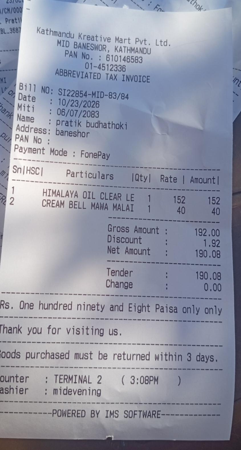


RECEIPT: 862844783_1769265710828868_4212245171983610322_n (1).jpg
VERDICT : AUTO-APPROVED (the app would file it without asking)
WHY     : Items add up to the total (VAT and discount included)
CONFIDENCE 0.942  (threshold 0.7; at or above goes straight in)

1. WHAT THE OCR READ
Engine: docTR   |   27 text lines
If a number or word you can see on the bill is missing or wrong here, the OCR is the problem, not the models.

2. LINE BY LINE: what the trained line model took each line for
sureness = how sure the model is of its label (1.00 = certain). role = what the reader finally did with the line.

  #  label     sure  role                                 text
  0  date      0.66  -                                    CM/000
  1  merchant  0.68  MERCHANT                             Pratil
  2  other     0.90  -                                    BL.3687 Kathmandu Kreative
  3  other     0.98  -                                    MID BANESWOR, Mart Pvt. Ltd.
  4  other     1.00  -         

In [26]:
MY_PHOTO_PATHS = []        # e.g. ["/content/my_bill.jpg"]. Leave empty to upload in Colab.

def read_my_photo(image, models=None, explain_it=True, name="my photo"):
    """One photo (path or PIL image) in, receipt dict out. explain_it=True also prints the full report."""
    models = models or MODELS
    if isinstance(image, (str, os.PathLike)):
        name = os.path.basename(str(image))
        image = Image.open(image)
    image.load()
    trace = {}
    result = read_photo(image, models, trace)
    if explain_it:
        show(result, trace, name)
    os.makedirs("results", exist_ok=True)
    out = os.path.join("results", "result_" + os.path.splitext(name)[0] + ".json")
    json.dump({"api_reply": result, "debug": trace}, open(out, "w", encoding="utf-8"), indent=2, ensure_ascii=False)
    print(f"\n(saved {out})")
    return result

photos = list(MY_PHOTO_PATHS)
if not photos:
    try:
        from google.colab import files
        print("Choose one or more bill photos that are NOT in Bills.zip.")
        os.makedirs("my_photos", exist_ok=True)
        for name, data in files.upload().items():
            p = os.path.join("my_photos", name)
            open(p, "wb").write(data)
            photos.append(p)
    except ImportError:
        print("Not in Colab: put paths in MY_PHOTO_PATHS and run this cell again.")
for p in photos:
    try:
        from IPython.display import display
        t = Image.open(p); t.thumbnail((450, 450)); display(t)
    except Exception:
        pass
    read_my_photo(p)

## 11. Export for the backend
**Model export point.** This writes the folder `kharcha_export/` with
* `kharcha_reader.py`: the reader as one file (settings, rules, OCR, both model classes, `KharchaReader`), copied from the `# export` cells above, so it is exactly the code you tested;
* `line_model.joblib` and `category_model.joblib`: the trained models;
* `requirements.txt` and `README.txt`.

Then it **tests the export in a fresh Python process** (no notebook state) on a photo and checks the answer is identical to the notebook's. Finally it downloads `kharcha_export.zip`.
Trained models only load with the same scikit-learn version: the requirements file pins the version used here.

In [20]:
import importlib.util, subprocess, sys

EXPORT_DIR = "kharcha_export"

def exported_source():
    """The latest run of every '# export' cell, in order."""
    history = get_ipython().user_ns["_ih"]
    latest = {}
    for src in history:
        first = src.lstrip().split("\n", 1)[0]
        if first.startswith("# export "):
            kv = dict(p.split("=") for p in first.split()[2:])
            latest[kv["name"]] = (int(kv["order"]), src)
    parts = [s for _, s in sorted(latest.values())]
    assert len(parts) == 5, f"expected 5 exported cells (settings, parse, ocr, models, pipeline), found {sorted(latest)}: run the cells above first"
    body = "\n\n\n".join(parts).replace('print("settings loaded")\n', "")
    return "# kharcha_reader.py: generated by the Kharcha notebook (part 11). Do not edit by hand; change the notebook and export again.\n" + body + "\n"

shutil.rmtree(EXPORT_DIR, ignore_errors=True)
os.makedirs(EXPORT_DIR)
open(os.path.join(EXPORT_DIR, "kharcha_reader.py"), "w", encoding="utf-8").write(exported_source())

# Load the exported module and rebuild the trained models as ITS classes, so the saved files do not depend on the notebook.
spec = importlib.util.spec_from_file_location("kharcha_reader", os.path.join(EXPORT_DIR, "kharcha_reader.py"))
kr = importlib.util.module_from_spec(spec)
sys.modules["kharcha_reader"] = kr
spec.loader.exec_module(kr)
exported = kr.Models(kr.LineModel(), kr.CategoryModel())
exported.line.__dict__.update(MODELS.line.__dict__)
exported.category.__dict__.update(MODELS.category.__dict__)
exported.save(EXPORT_DIR)

import sklearn
open(os.path.join(EXPORT_DIR, "requirements.txt"), "w").write(
    f"scikit-learn=={sklearn.__version__}\njoblib\nscipy\nnumpy\npillow\npytesseract\nopencv-python-headless\npython-doctr[torch]\n")
open(os.path.join(EXPORT_DIR, "README.txt"), "w").write(
"""Kharcha reader export
=====================
System:   apt install tesseract-ocr tesseract-ocr-eng tesseract-ocr-nep      (Windows: install Tesseract, set TESSERACT_CMD)
Python:   pip install -r requirements.txt        (scikit-learn must be the pinned version, or retrain in the notebook)

Use it:
    from kharcha_reader import KharchaReader
    reader = KharchaReader("path/to/this/folder")      # raises ModelsMissing if the .joblib files are gone
    result = reader.read("bill.jpg")                   # path or PIL image
    # result = {merchant?, date?, total, items:[{name, qty, price, category}], confidence, needs_review, reconciliation}
    # needs_review True -> send it to the review screen; False -> file it.
    # readable False (only on noise) -> nothing could be read; ask the user to type it in.

Tiny HTTP wrapper (FastAPI):
    from fastapi import FastAPI, Request
    import io; from PIL import Image
    app = FastAPI(); reader = KharchaReader(".")
    @app.post("/read")
    async def read(req: Request): return reader.read(Image.open(io.BytesIO(await req.body())))
""")
print("written:", sorted(os.listdir(EXPORT_DIR)))

written: ['README.txt', '__pycache__', 'category_model.joblib', 'kharcha_reader.py', 'line_model.joblib', 'requirements.txt']


In [21]:
# Test the export the way the backend will use it: a fresh Python process that only sees the export folder.
probe_photo = (BILL_PHOTOS[7] if BILL_PHOTOS else None)
if probe_photo is None:
    probe_photo = render(["CORNER MART", "Date: 15/10/2026", "Rice 5kg   640.00", "Milk 1l   140.00", "Grand Total   780.00"], "probe.png") and "probe.png"
child = (
    "import json, sys\n"
    "from kharcha_reader import KharchaReader\n"
    "r = KharchaReader('.')\n"
    "print(json.dumps(r.read(sys.argv[1]), ensure_ascii=False, sort_keys=True))\n")
p = subprocess.run([sys.executable, "-c", child, os.path.abspath(probe_photo)], cwd=EXPORT_DIR, capture_output=True, text=True)
if p.returncode != 0:
    print("EXPORT TEST FAILED, the error is:\n", p.stderr[-1500:])
else:
    from_export = json.loads(p.stdout.strip().splitlines()[-1])
    from_notebook = json.loads(json.dumps(read_photo(probe_photo, MODELS), sort_keys=True))
    print("photo used:", probe_photo)
    print("export result: merchant =", from_export.get("merchant"), "| total =", from_export.get("total"), "| items =", len(from_export["items"]),
          "| confidence =", from_export.get("confidence"), "| needs_review =", from_export.get("needs_review"))
    print("RESULT:", "PASS, the exported reader gives exactly the same answer as the notebook." if from_export == from_notebook
          else "DIFFERENT from the notebook: send me both outputs.")
shutil.make_archive("kharcha_export", "zip", EXPORT_DIR)
try:
    from google.colab import files
    files.download("kharcha_export.zip")
except ImportError:
    print("kharcha_export.zip written (not in Colab, so not downloaded)")

photo used: Bills/8.jpg
export result: merchant = G.R.G Bakery Pvt. Ltd | total = 340.0 | items = 2 | confidence = 0.95 | needs_review = False
RESULT: PASS, the exported reader gives exactly the same answer as the notebook.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>